# Multimodal Transformer for Relapse-Free Survival (RFS) Prediction

## Overview

This notebook implements the complete multimodal Transformer framework developed for **Relapse-Free Survival (RFS) prediction** using the TCGA-BRCA breast cancer cohort.

The proposed model integrates three complementary patient-level data modalities:

- Clinical features
- Selected genomic features
- Histopathology feature embeddings extracted from whole-slide images (WSIs)

The objective is to learn a unified patient representation that accurately predicts relapse-free survival by combining complementary clinical, genomic, and pathology-derived information.

---

## Notebook Pipeline

This notebook performs the following steps:

1. Load the multimodal RFS training, validation, and testing datasets.
2. Load histopathology feature embeddings for each patient.
3. Prepare pathology inputs using patch sampling, zero-padding, and attention masking.
4. Build the multimodal Transformer architecture.
5. Train the model using the Cox proportional hazards survival loss.
6. Apply early stopping and save the best-performing model checkpoint.
7. Evaluate the trained model on the independent test dataset.
8. Generate multiple survival evaluation metrics and visualizations.
9. Conduct modality ablation experiments to evaluate the contribution of each data modality.
10. Conduct pathology feature augmentation experiments to investigate the effect of different patch-selection and augmentation strategies on model performance.

---

## Model Architecture

The proposed multimodal Transformer consists of the following components:

- Clinical Encoder
- Genomic Encoder
- Pathology Transformer Encoder
- Multimodal Fusion Module
- Survival Prediction Head

For the pathology modality, each patient is represented using deep feature embeddings extracted from histopathology image patches.

Each patient contains up to **512 pathology patch embeddings**, where each embedding has **512 dimensions**.

Patients containing more than 512 patches are randomly sampled, while patients with fewer patches are zero-padded and accompanied by an attention mask before being processed by the pathology Transformer encoder.

The outputs of the three modality encoders are fused into a shared latent representation, which is then used to estimate each patient's survival risk.

---

## Training Strategy

The model is optimized using the **Cox proportional hazards loss**, enabling direct survival prediction without transforming the task into binary classification.

Training includes:

- **Adam optimizer:** Updates the model parameters during training to reduce the loss.
- **Learning rate scheduling:** Adjusts the learning rate during training. This helps the model make smaller updates when the learning process becomes stable.
- **Gradient clipping:** Limits very large gradients during backpropagation. This helps make training more stable.
- **Early stopping based on validation loss:** Stops training when the validation loss does not improve for several epochs. This helps prevent overfitting.
- **Automatic checkpoint saving of the best-performing model:** Saves the model with the best validation loss.

---

## Data Augmentation Experiments

This notebook includes a series of exploratory experiments designed to investigate whether pathology feature augmentation can improve relapse-free survival prediction when working with a limited number of patients and pre-extracted histopathology feature embeddings.


The experiments include the following configurations:

- **Baseline V3 selective fine-tuning:** Serves as the reference model for evaluating the effects of the subsequent augmentation experiments.
- **Random 60% patch retention:** Investigates the effect of retaining a randomly selected subset of pathology patches during training.
- **Strong pathology augmentation:** Applies noise, feature dropout, and patch dropout to pathology features to investigate whether stronger augmentation improves validation performance.
- **Random 80% patch retention:** Investigates whether retaining a larger proportion of pathology patches provides a different performance outcome.
- **Patch mixup with 80% patch retention:** Combines the 80% patch-retention setting with a mixup-based training strategy to investigate the effect of feature-level mixing.

The experiments use the same underlying training and validation cohort sizes. The original test set not used for model training.

The best checkpoint for each experiment is selected according to its validation performance. The experiments are compared using the validation C-index and Cox loss, followed by test-set evaluation for the selected experimental configurations.

The purpose of these experiments is to investigate whether modifying pathology patch selection and applying feature-level augmentation can improve model generalization. The results are treated as exploratory and are not assumed to demonstrate an improvement unless supported by the evaluation results.

### Very Important Note: Data Augmentation vs. Synthetic Data Generation

The previous data augmentation experiments **did not increase the number of patients**. The training set size remained the same.

These experiments were conducted to investigate whether different pathology data augmentation techniques could improve the model's performance.

**Synthetic data generation to increase the number of patient cases has not been implemented yet.** The synthetic data generator will be a separate experiment in the next stage of the project.

---

## Model Evaluation

The trained model is evaluated using several survival analysis metrics, including:

- **Concordance Index (C-index):** Measures the model's ability to correctly rank patients according to their survival risk. A higher C-index indicates better discrimination between patients with different risk levels.
- **Bootstrap validation with 95% confidence intervals:** Repeatedly resamples the test predictions to estimate the uncertainty of the C-index and provide a 95% confidence interval around the performance estimate.
- **Kaplan–Meier survival analysis:** Divides patients into risk groups and visualizes their estimated survival curves over time. This helps show whether the model can separate patients into groups with different survival outcomes.
- **Multi-group Log-rank test:** Statistically tests whether the Kaplan–Meier survival curves of the different predicted-risk groups are significantly different.
- **Time-dependent ROC/AUC:** Evaluates how well the model distinguishes patients with different survival outcomes at specific time points. The AUC summarizes the discrimination performance at each selected time point.
- **Integrated Brier Score (IBS):** Measures the overall accuracy of the predicted survival probabilities over time. It considers both discrimination and calibration, with lower values indicating better prediction accuracy.
- **Survival calibration analysis:** Evaluates how closely the predicted survival probabilities agree with the observed outcomes. Good calibration means that predicted risks are consistent with the actual survival experience of the patients.

These metrics evaluate both the discrimination ability and calibration quality of the proposed survival prediction model.

---

## Ablation Study

An ablation study is performed to quantify the contribution of each modality by evaluating the following configurations:

- Clinical only
- Genomics only
- Pathology only
- Clinical + Genomics
- Clinical + Pathology
- Genomics + Pathology
- Clinical + Genomics + Pathology (Full Multimodal Model)

The ablation experiments demonstrate the contribution of each modality and the benefit of multimodal feature fusion for relapse-free survival prediction.

---

## Comparison Models

In addition to the proposed Multimodal Transformer, several survival prediction models are trained and evaluated using the same dataset and survival evaluation framework.

The comparison models include:

- **Cox Proportional Hazards (Cox PH):** Classical statistical survival model
- **Random Survival Forest (RSF):** Machine Learning
- **XGBoost Survival:** Machine Learning
- **Survival Support Vector Machine (Survival SVM):** Machine Learning
- **Multilayer Perceptron Survival (MLP-Cox):** Deep Learning
- **Coxnet / Elastic-Net Cox:** Statistical + ML
- **Extra Survival Trees:** Machine Learning
- **Gradient Boosting Survival Analysis (GBSA):** Machine Learning
- **Lasso Cox:** Statistical + ML

The proposed Multimodal Transformer is then compared with these models using the same survival evaluation procedure, particularly the C-index, to provide a consistent performance comparison.

---

## Outputs

This notebook generates:

- Trained multimodal Transformer model
- Best model checkpoint
- Patient-level survival risk predictions
- Survival evaluation metrics
- Bootstrap confidence intervals
- Kaplan–Meier survival curves
- Time-dependent ROC/AUC curves
- Survival calibration analysis
- Integrated Brier Score results
- Ablation study results
- Comparison model results
- Model comparison tables
- C-index comparison visualization
- Pathology augmentation experiment checkpoints and training histories
- Validation performance summaries for augmentation experiments
- Test-set comparison results for selected augmentation configurations

---

## Objective

The objective of this notebook is to develop, train, and evaluate a multimodal Transformer capable of predicting **Relapse-Free Survival (RFS)** by integrating clinical, genomic, and histopathology-derived information into a unified survival prediction framework.

The notebook also evaluates the contribution of individual modalities through ablation experiments, investigates pathology feature augmentation strategies, and compares the proposed Transformer with established survival analysis and machine learning models.

##Imports

In [ ]:
!pip install scikit-survival
!pip install -q lifelines
import sys
import sklearn
import sksurv

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("scikit-survival:", sksurv.__version__)

from sksurv.svm import FastSurvivalSVM
from sksurv.linear_model import CoxnetSurvivalAnalysis

print("FastSurvivalSVM: OK")
print("CoxnetSurvivalAnalysis: OK")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 58.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 91.9 MB/s  0:00:00
  Created wheel for ecos: filename=ecos-2.0.14-cp313-cp313-linux_x86_64.whl size=204010 sha256=de62484dc369b868ee11435f63cda55800c55ec26391e744ea0f23a7660694eb
  Stored in directory: /root/.cache/pip/wheels/6b/82/0b/4bb5aa6c4618f367601a45db8710205d56858808423974e92a
Successfully built ecos
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [scikit-survival]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GC

In [ ]:
import sys
import sklearn

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.9.1


In [ ]:
try:
    import sksurv
    print("scikit-survival:", sksurv.__version__)
    print("scikit-survival imported successfully.")
except Exception as e:
    print("scikit-survival import failed:")
    print(type(e).__name__, ":", e)

scikit-survival: 0.28.0
scikit-survival imported successfully.


In [ ]:

!pip install -q --upgrade "scikit-learn==1.9.1" "scikit-survival==0.28.0"

In [ ]:
import sys
import sklearn

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.9.1


In [ ]:
import sksurv

print("scikit-survival:", sksurv.__version__)

from sksurv.svm import FastSurvivalSVM
from sksurv.linear_model import CoxnetSurvivalAnalysis

print("FastSurvivalSVM: OK")
print("CoxnetSurvivalAnalysis: OK")

scikit-survival: 0.28.0
FastSurvivalSVM: OK
CoxnetSurvivalAnalysis: OK


In [ ]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================


import os
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss
)

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torch.optim import AdamW

from torch.optim.lr_scheduler import CosineAnnealingLR

warnings.filterwarnings("ignore")

print("="*70)
print("Libraries Imported Successfully")
print("="*70)

Libraries Imported Successfully


##Mount Google Drive

In [ ]:
# ============================================================
# MOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/ggdrive")

print("Google Drive mounted.")

Mounted at /content/ggdrive
Google Drive mounted.


##Define Project Paths

In [ ]:

# ============================================================
# PROJECT PATHS — CORRECTED LEAKAGE-FREE MASTER DATASET V2
# ============================================================

import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

# NEW master dataset built from corrected splits and 200 genes
DATASET_DIR = os.path.join(
    BASE_DIR,
    "multimodal_rfs_dataset_leakage_free_v2"
)

# Pathology feature arrays
PATHOLOGY_DIR = os.path.join(
    BASE_DIR,
    "Features"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "trained_models_leakage_free_endpoint_v2"
)

RESULT_DIR = os.path.join(
    BASE_DIR,
    "transformer_results_leakage_free_endpoint_v2"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Confirm the expected files exist before proceeding
required_files = [
    "master_rfs_train.csv",
    "master_rfs_validation.csv",
    "master_rfs_test.csv",
    "master_rfs_all.csv"
]

for filename in required_files:
    filepath = os.path.join(DATASET_DIR, filename)
    assert os.path.isfile(filepath), (
        f"Required master dataset file not found: {filepath}"
    )

print("Project paths ready.")
print("Master dataset:", DATASET_DIR)
print("Pathology directory:", PATHOLOGY_DIR)
print("Model outputs:", MODEL_DIR)
print("Results:", RESULT_DIR)
print("\nAll four new master dataset files exist.")


Project paths ready.
Master dataset: /content/ggdrive/MyDrive/TCGA_BRCA/multimodal_rfs_dataset_leakage_free_v2
Pathology directory: /content/ggdrive/MyDrive/TCGA_BRCA/Features
Model outputs: /content/ggdrive/MyDrive/TCGA_BRCA/trained_models_leakage_free_endpoint_v2
Results: /content/ggdrive/MyDrive/TCGA_BRCA/transformer_results_leakage_free_endpoint_v2

All four new master dataset files exist.


##Load datasets

In [ ]:

# ============================================================
# LOAD CORRECTED MASTER DATASETS — ENDPOINT V2
# ============================================================

train = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_train.csv")
)

validation = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_validation.csv")
)

test = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_test.csv")
)

print("TRAIN:", train.shape)
print("VALIDATION:", validation.shape)
print("TEST:", test.shape)

print("\nPatients per split:")
print(len(train), len(validation), len(test))

# Expected corrected split sizes
assert len(train) == 236, (
    f"Expected 236 training patients, got {len(train)}."
)
assert len(validation) == 49, (
    f"Expected 49 validation patients, got {len(validation)}."
)
assert len(test) == 52, (
    f"Expected 52 test patients, got {len(test)}."
)

# Patient IDs must be unique and splits must not overlap
for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    assert df["patient_id"].notna().all(), (
        f"Missing patient IDs in {name}."
    )
    assert df["patient_id"].is_unique, (
        f"Duplicate patient IDs in {name}."
    )

assert set(train["patient_id"]).isdisjoint(
    validation["patient_id"]
)
assert set(train["patient_id"]).isdisjoint(
    test["patient_id"]
)
assert set(validation["patient_id"]).isdisjoint(
    test["patient_id"]
)

# Confirm the required survival targets exist and are valid
for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    assert {"survival_time", "event"}.issubset(df.columns), (
        f"Survival target columns missing in {name}."
    )
    assert df["survival_time"].notna().all(), (
        f"Missing survival times in {name}."
    )
    assert (df["survival_time"] > 0).all(), (
        f"Invalid survival times in {name}."
    )
    assert df["event"].isin([0, 1]).all(), (
        f"Invalid event labels in {name}."
    )

print("\nEvent counts:")
for name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test)
]:
    print(name, df["event"].value_counts().sort_index().to_dict())

print("\nPASS: corrected master datasets loaded.")
print("PASS: splits do not overlap.")
print("PASS: authoritative survival targets are present.")


TRAIN: (236, 226)
VALIDATION: (49, 226)
TEST: (52, 226)

Patients per split:
236 49 52

Event counts:
train {0: 182, 1: 54}
validation {0: 37, 1: 12}
test {0: 40, 1: 12}

PASS: corrected master datasets loaded.
PASS: splits do not overlap.
PASS: authoritative survival targets are present.


In [ ]:

# ============================================================
# DEFINE CLINICAL AND GENOMIC INPUT FEATURES — ENDPOINT V2
# ============================================================

non_feature_columns = [
    "patient_id",
    "file_uuid",
    "pathology_path",
    "split",
    "event",
    "survival_time"
]

clinical_columns = [
    "years_to_birth",
    "Tumor_purity",
    "pathologic_stage",
    "pathology_T_stage",
    "pathology_N_stage",
    "pathology_M_stage",
    "number_of_lymph_nodes",
    "radiation_therapy"
]

# Include the encoded clinical categorical features
clinical_columns += [
    c for c in train.columns
    if c.startswith((
        "histological_type",
        "PAM50",
        "race",
        "ethnicity"
    ))
]

# Check that all expected clinical features exist
missing_clinical = [
    c for c in clinical_columns
    if c not in train.columns
]

assert not missing_clinical, (
    f"Expected clinical features missing: {missing_clinical}"
)

# The master dataset should contain exactly 200 selected genes
# in addition to clinical features and metadata.
genomic_columns = [
    c for c in train.columns
    if c not in clinical_columns + non_feature_columns
]

print("Clinical features:", len(clinical_columns))
print("Genomic features:", len(genomic_columns))
print("Total tabular features:", len(clinical_columns) + len(genomic_columns))

assert len(genomic_columns) == 200, (
    f"Expected 200 genomic features from the new pipeline, "
    f"but found {len(genomic_columns)}. Check the master dataset."
)

assert not set(clinical_columns) & set(genomic_columns)
assert not set(non_feature_columns) & set(genomic_columns)

assert "event" not in clinical_columns + genomic_columns
assert "survival_time" not in clinical_columns + genomic_columns
assert "patient_id" not in clinical_columns + genomic_columns
assert "pathology_path" not in clinical_columns + genomic_columns

# Confirm the validation and test datasets have the same feature columns
for name, df in [
    ("validation", validation),
    ("test", test)
]:
    missing_features = [
        c for c in clinical_columns + genomic_columns
        if c not in df.columns
    ]
    assert not missing_features, (
        f"Features missing from {name}: {missing_features}"
    )

print("\nPASS: using the new master dataset.")
print("PASS: exactly 200 genomic features detected.")
print("PASS: survival targets and metadata excluded from inputs.")


Clinical features: 20
Genomic features: 200
Total tabular features: 220

PASS: using the new master dataset.
PASS: exactly 200 genomic features detected.
PASS: survival targets and metadata excluded from inputs.


##Dataset Quality Control

In [ ]:
# ============================================================
# DATASET QUALITY CONTROL
# ============================================================

print("="*70)
print("QUALITY CONTROL")
print("="*70)

print("Training Patients :", train.patient_id.nunique())
print("Validation Patients :", validation.patient_id.nunique())
print("Testing Patients :", test.patient_id.nunique())

print()

print("Duplicate Patients")

print(train.patient_id.duplicated().sum())
print(validation.patient_id.duplicated().sum())
print(test.patient_id.duplicated().sum())

print()

print("Missing Labels")

print(train.event.isna().sum())
print(validation.event.isna().sum())
print(test.event.isna().sum())

QUALITY CONTROL
Training Patients : 236
Validation Patients : 49
Testing Patients : 52

Duplicate Patients
0
0
0

Missing Labels
0
0
0


##Set Random Seed

In [ ]:
# ============================================================
# RANDOM SEED
# ============================================================

SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True

torch.backends.cudnn.benchmark = False

print("="*70)
print("Random Seed:", SEED)
print("="*70)

Random Seed: 42


##Device Configuration

In [ ]:
# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("="*70)
print("Running on:", DEVICE)
print("="*70)

Running on: cpu


In [ ]:
import torch

print(torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

False


In [ ]:
# ============================================================
# INSPECT DATASET COLUMNS
# ============================================================

print("="*70)
print("TRAIN COLUMNS")
print("="*70)

for i, col in enumerate(train.columns):
    print(i, col)

TRAIN COLUMNS
0 patient_id
1 split
2 survival_time
3 event
4 years_to_birth
5 Tumor_purity
6 pathologic_stage
7 pathology_T_stage
8 pathology_N_stage
9 pathology_M_stage
10 number_of_lymph_nodes
11 radiation_therapy
12 histological_type_infiltratinglobularcarcinoma
13 histological_type_medullarycarcinoma
14 histological_type_metaplasticcarcinoma
15 histological_type_mixedhistology(pleasespecify)
16 histological_type_mucinouscarcinoma
17 histological_type_other,specify
18 PAM50_Her2
19 PAM50_LumA
20 PAM50_LumB
21 race_blackorafricanamerican
22 race_white
23 ethnicity_nothispanicorlatino
24 PSCA
25 ZNF385B
26 MYBPC1
27 CALML5
28 PRAME
29 FLT3
30 GREB1
31 TSPAN8
32 IL6ST
33 TUBA3E
34 RP1
35 DUSP9
36 S100P
37 LRRN1
38 FAM83A
39 CACNG4
40 LOC100128977
41 C1orf173
42 LOC100130148
43 HOTAIR
44 PCDH10
45 LIN28A
46 CACNG1
47 SLC16A6
48 FAM5C
49 LGALS7B
50 MYO3B
51 CXCL17
52 SPDYC
53 RBM24
54 CLIC6
55 ACTL8
56 SUSD3
57 KCNK1
58 SEMA3E
59 HHIPL2
60 CRLF1
61 CA8
62 NPW
63 GSDMC
64 MMP1
65 CA12
66 

##Define feature groups

In [ ]:
# ============================================================
# DEFINE FEATURE GROUPS
# ============================================================


non_feature_columns = [
    "patient_id",
    "file_uuid",
    "event",
    "survival_time"
]

clinical_columns = [
    "years_to_birth",
    "Tumor_purity",
    "pathologic_stage",
    "pathology_T_stage",
    "pathology_N_stage",
    "pathology_M_stage",
    "number_of_lymph_nodes",
    "radiation_therapy"
]

clinical_columns += [
    c for c in train.columns
    if c.startswith((
        "histological_type",
        "PAM50",
        "race",
        "ethnicity"
    ))
]

genomic_columns = [
    c for c in train.columns
    if c not in clinical_columns + non_feature_columns
]

target_columns = [
    "event",
    "survival_time"
]

print("="*70)
print("FEATURE GROUPS")
print("="*70)

print("Clinical features:", len(clinical_columns))
print("Genomic features :", len(genomic_columns))

print("\nFirst clinical:")
print(clinical_columns[:5])

print("\nFirst genomic:")
print(genomic_columns[:5])

FEATURE GROUPS
Clinical features: 20
Genomic features : 202

First clinical:
['years_to_birth', 'Tumor_purity', 'pathologic_stage', 'pathology_T_stage', 'pathology_N_stage']

First genomic:
['split', 'PSCA', 'ZNF385B', 'MYBPC1', 'CALML5']


##Create pathology loading configuration

In [ ]:
# ============================================================
# PATHOLOGY CONFIGURATION
# ============================================================


PATHOLOGY_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA/Features"


MAX_PATCHES = 512
PATCH_FEATURES = 512


print("="*70)
print("PATHOLOGY CONFIGURATION")
print("="*70)

print("Directory:")
print(PATHOLOGY_DIR)

print()

print("Maximum patches per patient:", MAX_PATCHES)
print("Patch embedding dimension:", PATCH_FEATURES)

PATHOLOGY CONFIGURATION
Directory:
/content/ggdrive/MyDrive/TCGA_BRCA/Features

Maximum patches per patient: 512
Patch embedding dimension: 512


##Create pathology processing function

In [ ]:
import os
import hashlib
import numpy as np

def load_pathology_features(file_uuid, max_patches=512):
    path = os.path.join(PATHOLOGY_DIR, str(file_uuid) + ".npy")

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Pathology features not found: {path}"
        )

    features = np.load(path).astype(np.float32)

    if features.ndim != 2 or features.shape[1] != 512:
        raise ValueError(
            f"Expected [num_patches, 512], got {features.shape}"
        )

    if not np.isfinite(features).all():
        raise ValueError(
            f"Non-finite pathology features in {path}"
        )

    n_patches = features.shape[0]

    if n_patches > max_patches:
        # Stable seed for this patient; independent of Python's hash randomization.
        digest = hashlib.sha256(
            str(file_uuid).encode("utf-8")
        ).digest()
        seed = int.from_bytes(digest[:8], byteorder="big")

        rng = np.random.default_rng(seed)
        indices = rng.choice(
            n_patches,
            size=max_patches,
            replace=False
        )
        features = features[indices]
        mask = np.ones(max_patches, dtype=np.float32)

    elif n_patches < max_patches:
        padding = np.zeros(
            (max_patches - n_patches, 512),
            dtype=np.float32
        )
        features = np.concatenate([features, padding], axis=0)

        mask = np.concatenate([
            np.ones(n_patches, dtype=np.float32),
            np.zeros(max_patches - n_patches, dtype=np.float32)
        ])

    else:
        mask = np.ones(max_patches, dtype=np.float32)

    return features.astype(np.float32), mask.astype(np.float32)

##Test the pathology function

In [ ]:
print(train.columns.tolist())

['years_to_birth', 'Tumor_purity', 'pathologic_stage', 'pathology_T_stage', 'pathology_N_stage', 'pathology_M_stage', 'number_of_lymph_nodes', 'radiation_therapy', 'histological_type_infiltratinglobularcarcinoma', 'histological_type_medullarycarcinoma', 'histological_type_metaplasticcarcinoma', 'histological_type_mixedhistology(pleasespecify)', 'histological_type_mucinouscarcinoma', 'histological_type_other,specify', 'PAM50_Her2', 'PAM50_LumA', 'PAM50_LumB', 'race_blackorafricanamerican', 'race_white', 'ethnicity_nothispanicorlatino', 'MYBPC1', 'ZNF385B', 'ALG1L', 'PCDH10', 'FLT3', 'PCDHA6', 'SPDYC', 'CACNA1H', 'PYDC1', 'TSPAN8', 'LRRN1', 'LOC100128977', 'PSCA', 'MYO3B', 'CXCL13', 'FIBCD1', 'CPA6', 'FAM5C', 'ORM1', 'HOTAIR', 'CYP4F11', 'NTRK3', 'SULT4A1', 'MMP1', 'GREB1', 'LTF', 'CEACAM6', 'PCDHA12', 'CACNG1', 'CEACAM5', 'TUBA3E', 'PCDHA13', 'HMP19', 'CACNG4', 'CYP24A1', 'CYP4F22', 'RBM24', 'LRTM2', 'NPW', 'PCDHA4', 'CYP2A6', 'GAD1', 'LOC100130148', 'MUC2', 'KCNK3', 'IL20RA', 'VTCN1', 

In [ ]:
# ============================================================
# TEST PATHOLOGY LOADER
# ============================================================


sample_uuid = train.iloc[0]["file_uuid"]


features, mask = load_pathology_features(
    sample_uuid
)


print("="*70)

print("Pathology feature shape:")
print(features.shape)


print()

print("Mask shape:")
print(mask.shape)


print()

print("Real patches:")
print(mask.sum())

Pathology feature shape:
(512, 512)

Mask shape:
(512,)

Real patches:
512.0


##Import PyTorch

In [ ]:
# ============================================================
# MULTIMODAL PYTORCH DATASET
# ============================================================

# prepared the Dataset structure that will be used to provide data to the Transformer model.

import torch

from torch.utils.data import Dataset


class MultimodalBreastCancerDataset(Dataset):


    def __init__(
        self,
        dataframe
    ):

        self.data = dataframe.reset_index(drop=True)



    def __len__(self):

        return len(self.data)



    def __getitem__(
        self,
        idx
    ):

        row = self.data.iloc[idx]


        # ----------------------------
        # Clinical features
        # ----------------------------

        clinical = row[
            clinical_columns
        ].values.astype(np.float32)



        # ----------------------------
        # Genomic features
        # ----------------------------

        genomic = row[
            genomic_columns
        ].values.astype(np.float32)



        # ----------------------------
        # Pathology features
        # ----------------------------

        pathology, mask = load_pathology_features(
            row["file_uuid"],
            MAX_PATCHES
        )



        # ----------------------------
        # Labels
        # ----------------------------

        event = np.float32(
            row["event"]
        )


        survival = np.float32(
            row["survival_time"]
        )



        return {

            "clinical":
            torch.tensor(
                clinical
            ),


            "genomic":
            torch.tensor(
                genomic
            ),


            "pathology":
            torch.tensor(
                pathology
            ),


            "mask":
            torch.tensor(
                mask
            ),


            "label":
            torch.tensor(
                event
            ),


            "survival":
            torch.tensor(
                survival
            ),


            "event":
torch.tensor(
    event
)
        }

##Create datasets

In [ ]:

# ============================================================
# CREATE TRAIN / VALIDATION / TEST DATASETS
# ============================================================
# Creates PyTorch datasets for training, validation, and testing.
# Eğitim, validation ve test verileri için PyTorch datasetleri oluşturuldu.
#
# Each dataset contains:
# - Clinical features
# - Genomic features
# - Pathology embeddings
# - Survival information
#
# Her veri bölümü model için uygun Tensor formatında hazırlandı.

train_dataset = MultimodalBreastCancerDataset(
    train
)


val_dataset = MultimodalBreastCancerDataset(
    validation
)


test_dataset = MultimodalBreastCancerDataset(
    test
)



print("="*70)

print("Train samples:",
      len(train_dataset))

print("Validation samples:",
      len(val_dataset))

print("Test samples:",
      len(test_dataset))

Train samples: 236
Validation samples: 49
Test samples: 52


##Model hyperparameters

In [ ]:
# ============================================================
# MODEL CONFIGURATION
# ============================================================
# Defines the main parameters used by the multimodal Transformer model.

MODEL_CONFIG = {


    # feature sizes

    "clinical_dim": len(clinical_columns),

    "genomic_dim": len(genomic_columns),

    "pathology_dim": 512,


    # transformer architecture parameters

    "embed_dim": 128,

    "num_heads": 4,

    "num_layers": 2,


    # regularization settings

    "dropout": 0.3,


    # training parameters

    "batch_size": 4,

    "learning_rate": 1e-4,

    "epochs": 100

}



print("="*70)
print("MODEL CONFIGURATION")
print("="*70)


for k,v in MODEL_CONFIG.items():

    print(
        k,
        ":",
        v
    )

MODEL CONFIGURATION
clinical_dim : 20
genomic_dim : 202
pathology_dim : 512
embed_dim : 128
num_heads : 4
num_layers : 2
dropout : 0.3
batch_size : 4
learning_rate : 0.0001
epochs : 100


##Clinical Encoder

In [ ]:
# ============================================================
# CLINICAL ENCODER
# ============================================================

# Converts clinical features into Transformer-compatible embeddings.

# The encoder:
# - Projects clinical features to shared embedding dimension.
# - Applies normalization and non-linear transformation.
# - Adds token dimension for Transformer input.


import torch
import torch.nn as nn



class ClinicalEncoder(nn.Module):


    def __init__(
        self,
        input_dim,
        embed_dim,
        dropout=0.3
    ):

        super().__init__()


        self.encoder = nn.Sequential(

            nn.Linear(
                input_dim,
                embed_dim
            ),

            nn.LayerNorm(
                embed_dim
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            )

        )



    def forward(
        self,
        x
    ):

        """
        x:
        [batch, clinical_features]

        output:
        [batch, 1, embedding]
        """


        x = self.encoder(x)


        # create token dimension

        x = x.unsqueeze(1)


        return x

##Test Clinical Encoder

In [ ]:
# ============================================================
# TEST CLINICAL ENCODER
# ============================================================


clinical_encoder = ClinicalEncoder(
    MODEL_CONFIG["clinical_dim"],
    MODEL_CONFIG["embed_dim"],
    MODEL_CONFIG["dropout"]
)



sample_clinical = torch.randn(
    4,
    MODEL_CONFIG["clinical_dim"]
)


clinical_output = clinical_encoder(
    sample_clinical
)



print(
    "Input:",
    sample_clinical.shape
)


print(
    "Output:",
    clinical_output.shape
)

Input: torch.Size([4, 20])
Output: torch.Size([4, 1, 128])


##Genomic Encoder

In [ ]:
# ============================================================
# GENOMIC ENCODER
# ============================================================

# Converts genomic features into Transformer-compatible embeddings.

# The encoder:
# - Projects genomic features into a shared embedding dimension.
# - Uses normalization and non-linear transformation.
# - Adds token dimension for Transformer input.

class GenomicEncoder(nn.Module):


    def __init__(
        self,
        input_dim,
        embed_dim,
        dropout=0.3
    ):

        super().__init__()



        self.encoder = nn.Sequential(

            nn.Linear(
                input_dim,
                256
            ),

            nn.LayerNorm(
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),


            nn.Linear(
                256,
                embed_dim
            ),

            nn.LayerNorm(
                embed_dim
            )

        )



    def forward(
        self,
        x
    ):


        x = self.encoder(x)


        x = x.unsqueeze(1)


        return x

##Test genomic encoder

In [ ]:
# ============================================================
# TEST GENOMIC ENCODER
# ============================================================


genomic_encoder = GenomicEncoder(
    MODEL_CONFIG["genomic_dim"],
    MODEL_CONFIG["embed_dim"],
    MODEL_CONFIG["dropout"]
)



sample_genomic = torch.randn(
    4,
    MODEL_CONFIG["genomic_dim"]
)



genomic_output = genomic_encoder(
    sample_genomic
)



print(
    "Input:",
    sample_genomic.shape
)


print(
    "Output:",
    genomic_output.shape
)

Input: torch.Size([4, 200])
Output: torch.Size([4, 1, 128])


##Pathology Transformer Encoder

In [ ]:
class PathologyEncoder(nn.Module):
    def __init__(
        self, input_dim, embed_dim,
        num_heads, num_layers, dropout=0.3
    ):
        super().__init__()

        self.patch_projection = nn.Linear(input_dim, embed_dim)
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=embed_dim * 4,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x, mask=None):
        batch_size, num_patches, _ = x.shape

        x = self.patch_projection(x)

        cls_tokens = self.cls_token.expand(
            batch_size, -1, -1
        )
        x = torch.cat([cls_tokens, x], dim=1)

        padding_mask = None

        if mask is not None:
            if mask.shape != (batch_size, num_patches):
                raise ValueError(
                    f"Expected mask shape {(batch_size, num_patches)}, "
                    f"got {tuple(mask.shape)}"
                )

            # True means ignore this patch.
            # The CLS token must never be masked.
            patch_padding = (mask <= 0)
            cls_padding = torch.zeros(
                (batch_size, 1),
                dtype=torch.bool,
                device=x.device
            )
            padding_mask = torch.cat(
                [cls_padding, patch_padding.to(x.device)],
                dim=1
            )

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        x = self.norm(x[:, 0, :])
        return x.unsqueeze(1)

##Test Pathology Transformer Encoder

In [ ]:
# ============================================================
# TEST PATHOLOGY ENCODER
# ============================================================


pathology_encoder = PathologyEncoder(

    input_dim=MODEL_CONFIG["pathology_dim"],

    embed_dim=MODEL_CONFIG["embed_dim"],

    num_heads=MODEL_CONFIG["num_heads"],

    num_layers=MODEL_CONFIG["num_layers"],

    dropout=MODEL_CONFIG["dropout"]

)



sample_pathology = torch.randn(
    4,
    512,
    512
)



pathology_output = pathology_encoder(
    sample_pathology
)



print(
    "Input:",
    sample_pathology.shape
)


print(
    "Output:",
    pathology_output.shape
)

Input: torch.Size([4, 512, 512])
Output: torch.Size([4, 1, 128])


##The fusion module

In [ ]:
# ============================================================
# MULTIMODAL FUSION TRANSFORMER
# ============================================================

# Combines clinical, genomic, and pathology embeddings into one

# Steps:
# - Receives one token from each modality encoder.
# - Concatenates three modality tokens.
# - Uses Transformer attention to learn interactions between modalities.
# - Applies normalization and pooling to obtain final patient embedding.


class MultimodalFusionTransformer(nn.Module):


    def __init__(
        self,
        embed_dim,
        num_heads,
        num_layers,
        dropout=0.3
    ):

        super().__init__()



        encoder_layer = nn.TransformerEncoderLayer(

            d_model=embed_dim,

            nhead=num_heads,

            dim_feedforward=embed_dim*4,

            dropout=dropout,

            batch_first=True,

            activation="gelu"

        )



        self.transformer = nn.TransformerEncoder(

            encoder_layer,

            num_layers=num_layers

        )



        self.norm = nn.LayerNorm(
            embed_dim
        )



    def forward(
        self,
        clinical_token,
        genomic_token,
        pathology_token
    ):


        """

        Inputs:

        clinical:
        [batch,1,128]


        genomic:
        [batch,1,128]


        pathology:
        [batch,1,128]



        Output:

        fused representation

        [batch,128]

        """



        # concatenate modality tokens

        x = torch.cat(

            [
                clinical_token,
                genomic_token,
                pathology_token
            ],

            dim=1

        )



        # now:

        # [batch,3,128]


        x = self.transformer(
            x
        )


        x = self.norm(x)



        # mean pooling over modalities

        x = x.mean(
            dim=1
        )


        return x

##Testing

In [ ]:
print(MODEL_CONFIG)

{'clinical_dim': 20, 'genomic_dim': 200, 'pathology_dim': 512, 'embed_dim': 128, 'num_heads': 4, 'num_layers': 2, 'dropout': 0.3, 'batch_size': 4, 'learning_rate': 0.0001, 'epochs': 100}


##Test the fusion module

In [ ]:
# ============================================================
# TEST FUSION TRANSFORMER
# ============================================================


fusion_model = MultimodalFusionTransformer(

    embed_dim=MODEL_CONFIG["embed_dim"],

    num_heads=MODEL_CONFIG["num_heads"],

    num_layers=MODEL_CONFIG["num_layers"],

    dropout=MODEL_CONFIG["dropout"]

)



sample_clinical_token = torch.randn(
    4,
    1,
    128
)


sample_genomic_token = torch.randn(
    4,
    1,
    128
)


sample_pathology_token = torch.randn(
    4,
    1,
    128
)



fusion_output = fusion_model(

    sample_clinical_token,

    sample_genomic_token,

    sample_pathology_token

)



print(
    "Fusion output:",
    fusion_output.shape
)

Fusion output: torch.Size([4, 128])



##Prediction Heads

In [ ]:

# Converts the fused multimodal patient representation into a survival risk score.

# The head:
# - Reduces embedding dimension.
# - Applies non-linear transformation.
# - Outputs one risk score for each patient.
#
# The output is used with Cox proportional hazards loss for Relapse-Free Survival prediction.

class SurvivalPredictionHead(nn.Module):

    def __init__(
        self,
        embed_dim,
        dropout=0.3
    ):
        super().__init__()

        self.head = nn.Sequential(

            nn.Linear(
                embed_dim,
                64
            ),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(
                64,
                1
            )
        )


    def forward(self, x):

        risk = self.head(x)

        return risk

##Test Prediction Heads

In [ ]:
# ============================================================
# TEST PREDICTION HEAD
# ============================================================


prediction_head = SurvivalPredictionHead(

    embed_dim=MODEL_CONFIG["embed_dim"],

    dropout=MODEL_CONFIG["dropout"]

)



sample_features = torch.randn(
    4,
    128
)



survival_output = prediction_head(
    sample_features
)




print(
    "Survival output:",
    survival_output.shape
)

Survival output: torch.Size([4, 1])


# ============================================================
# TRAINING UTILITIES
# ============================================================

In [ ]:
# ============================================================
# DEVICE CONFIGURATION
# ============================================================

import torch

if torch.cuda.is_available():

    device = torch.device("cuda")

else:

    device = torch.device("cpu")


print("="*70)
print("DEVICE CONFIGURATION")
print("="*70)

print("Using device:", device)


if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

DEVICE CONFIGURATION
Using device: cpu


##Cox Partial Likelihood Loss

In [ ]:

def full_cox_loss_and_coefficients(risk, survival_time, event):
    risk = risk.reshape(-1).double()
    time = survival_time.reshape(-1).double()
    event = event.reshape(-1).double()

    if not (risk.numel() == time.numel() == event.numel()):
        raise ValueError("Risk, time and event lengths do not match.")
    if not torch.isfinite(risk).all():
        raise ValueError("Risk scores contain non-finite values.")
    if not torch.isfinite(time).all() or (time <= 0).any():
        raise ValueError("Survival times must be finite and positive.")
    if not torch.isfinite(event).all():
        raise ValueError("Event labels contain non-finite values.")
    if not torch.all((event == 0) | (event == 1)):
        raise ValueError("Event labels must be 0 or 1.")

    n_events = event.sum()
    if n_events.item() == 0:
        raise ValueError("The cohort has no observed events.")

    risk_max = risk.max()
    z = torch.exp(risk - risk_max)

    # Row i contains the risk set for patient i:
    # patient j is at risk at time i if time_j >= time_i.
    risk_set = time.unsqueeze(0) >= time.unsqueeze(1)

    denominators = (
        risk_set.double() * z.unsqueeze(0)
    ).sum(dim=1).clamp_min(1e-12)

    log_denominators = torch.log(denominators) + risk_max

    loss = -(
        event * (risk - log_denominators)
    ).sum() / n_events

    # Correct orientation: event patient i includes patient j
    # in its risk set when time_j >= time_i.
    contributes = time.unsqueeze(1) <= time.unsqueeze(0)

    event_weights = event / denominators

    coefficients = (
        -event
        + z * (
            contributes.double()
            * event_weights.unsqueeze(1)
        ).sum(dim=0)
    ) / n_events

    return loss.detach().float(), coefficients.detach().float()


def validate_epoch(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.no_grad():
        for batch in loader:
            clinical = batch["clinical"].to(device).float()
            genomic = batch["genomic"].to(device).float()
            pathology = batch["pathology"].to(device).float()
            mask = batch["mask"].to(device).float()

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(output["survival"].reshape(-1).cpu())
            all_survival.append(batch["survival"].reshape(-1).cpu())
            all_events.append(batch["event"].reshape(-1).cpu())

    all_risk = torch.cat(all_risk)
    all_survival = torch.cat(all_survival)
    all_events = torch.cat(all_events)

    # One loss over the entire validation cohort.
    val_loss, _ = full_cox_loss_and_coefficients(
        all_risk, all_survival, all_events
    )

    return (
        val_loss.item(),
        all_risk.numpy(),
        all_survival.numpy(),
        all_events.numpy()
    )

print("Corrected full-cohort Cox helper and validation function defined.")


Corrected full-cohort Cox helper and validation function defined.


In [ ]:

# ============================================================
# COX SURVIVAL LOSS — FIXED TENSOR SHAPES
# ============================================================

class CoxPHLoss(nn.Module):

    def __init__(self):
        super().__init__()

    def forward(self, risk, survival_time, event):

        # Preserve a 1D tensor even when batch size = 1
        risk = risk.reshape(-1)
        survival_time = survival_time.reshape(-1)
        event = event.reshape(-1).to(dtype=risk.dtype)

        # Check input consistency
        if not (
            risk.numel() == survival_time.numel() == event.numel()
        ):
            raise ValueError(
                f"Input size mismatch: risk={risk.shape}, "
                f"survival_time={survival_time.shape}, "
                f"event={event.shape}"
            )

        # A Cox loss requires at least one observed event
        if event.sum().item() == 0:
            return risk.sum() * 0.0

        # Sort by decreasing survival time
        order = torch.argsort(survival_time, descending=True)

        risk = risk[order]
        event = event[order]

        # Cumulative risk over the sorted batch
        log_cumulative_hazard = torch.logcumsumexp(risk, dim=0)

        # Negative partial log-likelihood
        partial_likelihood = risk - log_cumulative_hazard

        loss = -(partial_likelihood * event).sum() / event.sum()

        return loss

cox_loss = CoxPHLoss()


In [ ]:

def full_cox_loss_and_coefficients(risk, survival_time, event):
    risk = risk.reshape(-1).double()
    time = survival_time.reshape(-1).double()
    event = event.reshape(-1).double()

    if not (risk.numel() == time.numel() == event.numel()):
        raise ValueError("Risk, time and event lengths do not match.")
    if not torch.isfinite(risk).all():
        raise ValueError("Risk scores contain non-finite values.")
    if not torch.isfinite(time).all() or (time <= 0).any():
        raise ValueError("Survival times must be finite and positive.")
    if not torch.isfinite(event).all():
        raise ValueError("Event labels contain non-finite values.")
    if not torch.all((event == 0) | (event == 1)):
        raise ValueError("Event labels must be 0 or 1.")

    n_events = event.sum()
    if n_events.item() == 0:
        raise ValueError("The cohort has no observed events.")

    risk_max = risk.max()
    z = torch.exp(risk - risk_max)

    # Row i contains the risk set for patient i:
    # patient j is at risk at time i if time_j >= time_i.
    risk_set = time.unsqueeze(0) >= time.unsqueeze(1)

    denominators = (
        risk_set.double() * z.unsqueeze(0)
    ).sum(dim=1).clamp_min(1e-12)

    log_denominators = torch.log(denominators) + risk_max

    loss = -(
        event * (risk - log_denominators)
    ).sum() / n_events

    # Correct orientation: event patient i includes patient j
    # in its risk set when time_j >= time_i.
    contributes = time.unsqueeze(1) <= time.unsqueeze(0)

    event_weights = event / denominators

    coefficients = (
        -event
        + z * (
            contributes.double()
            * event_weights.unsqueeze(1)
        ).sum(dim=0)
    ) / n_events

    return loss.detach().float(), coefficients.detach().float()


def validate_epoch(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.no_grad():
        for batch in loader:
            clinical = batch["clinical"].to(device).float()
            genomic = batch["genomic"].to(device).float()
            pathology = batch["pathology"].to(device).float()
            mask = batch["mask"].to(device).float()

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(output["survival"].reshape(-1).cpu())
            all_survival.append(batch["survival"].reshape(-1).cpu())
            all_events.append(batch["event"].reshape(-1).cpu())

    all_risk = torch.cat(all_risk)
    all_survival = torch.cat(all_survival)
    all_events = torch.cat(all_events)

    # One loss over the entire validation cohort.
    val_loss, _ = full_cox_loss_and_coefficients(
        all_risk, all_survival, all_events
    )

    return (
        val_loss.item(),
        all_risk.numpy(),
        all_survival.numpy(),
        all_events.numpy()
    )

print("Corrected full-cohort Cox helper and validation function defined.")


Corrected full-cohort Cox helper and validation function defined.


In [ ]:

from torch.utils.data import DataLoader, SequentialSampler

train_loader_fullrisk = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

print("=" * 60)
print("FULL-COHORT TRAINING LOADER AUDIT")
print("=" * 60)

print("Training patients:", len(train_dataset))
print("Batches:", len(train_loader_fullrisk))
print("Sequential sampler:", isinstance(
    train_loader_fullrisk.sampler, SequentialSampler
))
print("Drop last:", train_loader_fullrisk.drop_last)

checks = {
    "236 training patients": len(train_dataset) == 236,
    "Sequential order": isinstance(
        train_loader_fullrisk.sampler, SequentialSampler
    ),
    "No dropped final batch": not train_loader_fullrisk.drop_last
}

if hasattr(train_dataset, "data") and "patient_id" in train_dataset.data.columns:
    dataset_ids = train_dataset.data["patient_id"].astype(str).tolist()
    expected_ids = train["patient_id"].astype(str).tolist()

    checks["IDs match training dataframe in order"] = (
        dataset_ids == expected_ids
    )
    checks["Patient IDs unique"] = (
        len(set(dataset_ids)) == len(dataset_ids)
    )

seen = 0
for batch in train_loader_fullrisk:
    seen += len(batch["survival"])

checks["Loader covers all 236 patients"] = seen == 236

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("Patients yielded:", seen)
print(
    "\nLOADER AUDIT PASSED"
    if all(checks.values())
    else "\nLOADER AUDIT NEEDS REVIEW"
)


FULL-COHORT TRAINING LOADER AUDIT
Training patients: 236
Batches: 59
Sequential sampler: True
Drop last: False
236 training patients: PASS
Sequential order: PASS
No dropped final batch: PASS
IDs match training dataframe in order: PASS
Patient IDs unique: PASS
Loader covers all 236 patients: PASS
Patients yielded: 236

LOADER AUDIT PASSED


In [ ]:

from torch.utils.data import DataLoader, SequentialSampler

train_loader_fullrisk = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

print("=" * 60)
print("FULL-COHORT TRAINING LOADER AUDIT")
print("=" * 60)

print("Training patients:", len(train_dataset))
print("Batches:", len(train_loader_fullrisk))
print("Sequential sampler:", isinstance(
    train_loader_fullrisk.sampler, SequentialSampler
))
print("Drop last:", train_loader_fullrisk.drop_last)

checks = {
    "236 training patients": len(train_dataset) == 236,
    "Sequential order": isinstance(
        train_loader_fullrisk.sampler, SequentialSampler
    ),
    "No dropped final batch": not train_loader_fullrisk.drop_last
}

if hasattr(train_dataset, "data") and "patient_id" in train_dataset.data.columns:
    dataset_ids = train_dataset.data["patient_id"].astype(str).tolist()
    expected_ids = train["patient_id"].astype(str).tolist()

    checks["IDs match training dataframe in order"] = (
        dataset_ids == expected_ids
    )
    checks["Patient IDs unique"] = (
        len(set(dataset_ids)) == len(dataset_ids)
    )

seen = 0
for batch in train_loader_fullrisk:
    seen += len(batch["survival"])

checks["Loader covers all 236 patients"] = seen == 236

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("Patients yielded:", seen)
print(
    "\nLOADER AUDIT PASSED"
    if all(checks.values())
    else "\nLOADER AUDIT NEEDS REVIEW"
)


FULL-COHORT TRAINING LOADER AUDIT
Training patients: 236
Batches: 59
Sequential sampler: True
Drop last: False
236 training patients: PASS
Sequential order: PASS
No dropped final batch: PASS
IDs match training dataframe in order: PASS
Patient IDs unique: PASS
Loader covers all 236 patients: PASS
Patients yielded: 236

LOADER AUDIT PASSED


In [ ]:

import torch

print("=" * 60)
print("FULL-COHORT COX GRADIENT VERIFICATION")
print("=" * 60)

# Four artificial patients; no real patient data is used.
risk_values = torch.tensor(
    [0.4, -0.2, 0.7, 0.1], dtype=torch.float64
)
times = torch.tensor(
    [10.0, 8.0, 5.0, 2.0], dtype=torch.float64
)
events = torch.tensor(
    [1.0, 0.0, 1.0, 1.0], dtype=torch.float64
)

# A. Get the loss and analytical gradient coefficients
helper_loss, coefficients = full_cox_loss_and_coefficients(
    risk_values, times, events
)

# B. Independently calculate the Cox loss using autograd
risk_auto = risk_values.clone().detach().requires_grad_(True)

risk_set = times.unsqueeze(0) >= times.unsqueeze(1)
denominators = (
    risk_set.double() * torch.exp(risk_auto).unsqueeze(0)
).sum(dim=1)

direct_loss = -(
    events * (risk_auto - torch.log(denominators))
).sum() / events.sum()

direct_loss.backward()
autograd_gradient = risk_auto.grad.detach()

# C. Compare the helper's coefficients with autograd's gradient
max_gradient_difference = (
    coefficients.double() - autograd_gradient
).abs().max().item()

loss_difference = abs(helper_loss.item() - direct_loss.item())

print("Helper Cox loss:", helper_loss.item())
print("Autograd Cox loss:", direct_loss.item())
print("Loss difference:", loss_difference)
print("\nHelper gradient coefficients:")
print(coefficients)
print("\nAutograd gradient:")
print(autograd_gradient)
print("\nMaximum gradient difference:", max_gradient_difference)

loss_ok = loss_difference < 1e-6
gradient_ok = max_gradient_difference < 1e-6

print("\nLoss matches:", loss_ok)
print("Gradient matches:", gradient_ok)

if loss_ok and gradient_ok:
    print("\nCOX MATHEMATICAL VERIFICATION PASSED")
else:
    print("\nVERIFICATION FAILED — DO NOT TRAIN YET")


FULL-COHORT COX GRADIENT VERIFICATION
Helper Cox loss: 0.785365104675293
Autograd Cox loss: 0.7853651197061339
Loss difference: 1.50308409052613e-08

Helper gradient coefficients:
tensor([ 0.2066,  0.1134, -0.0545, -0.2655])

Autograd gradient:
tensor([ 0.2066,  0.1134, -0.0545, -0.2655], dtype=torch.float64)

Maximum gradient difference: 1.418203354752734e-08

Loss matches: True
Gradient matches: True

COX MATHEMATICAL VERIFICATION PASSED


In [ ]:

import copy
import torch
import torch.nn as nn

print("=" * 65)
print("TWO-PASS COX TRAINING GRADIENT VERIFICATION")
print("=" * 65)

torch.manual_seed(2026)

# Synthetic data: 11 artificial patients, 5 input features each.
n = 11
batch_size = 4
x = torch.randn(n, 5)
times = torch.tensor(
    [11., 10., 9., 8., 7., 6., 5., 4., 3., 2., 1.]
)
events = torch.tensor(
    [1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1.]
)

class ToySurvivalModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(5, 8),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(8, 1)
        )

    def forward(self, inputs):
        return self.net(inputs).reshape(-1)

model_two_pass = ToySurvivalModel()
initial_state = copy.deepcopy(model_two_pass.state_dict())

# ------------------------------------------------------------
# PASS A: obtain all risks and save RNG states for dropout replay
# ------------------------------------------------------------
model_two_pass.train()
rng_states = []
risk_parts = []

with torch.no_grad():
    for start in range(0, n, batch_size):
        rng_states.append(torch.get_rng_state().clone())
        risk_parts.append(
            model_two_pass(x[start:start + batch_size]).cpu()
        )

risks = torch.cat(risk_parts)

loss_a, coefficients = full_cox_loss_and_coefficients(
    risks, times, events
)

# ------------------------------------------------------------
# PASS B: accumulate the surrogate gradient batch by batch
# ------------------------------------------------------------
model_two_pass.zero_grad(set_to_none=True)

for batch_idx, start in enumerate(range(0, n, batch_size)):
    torch.set_rng_state(rng_states[batch_idx])

    end = min(start + batch_size, n)
    risk_batch = model_two_pass(x[start:end])

    coeff_batch = coefficients[start:end]
    surrogate = (risk_batch * coeff_batch).sum()
    surrogate.backward()

two_pass_gradients = {
    name: param.grad.detach().clone()
    for name, param in model_two_pass.named_parameters()
}

# ------------------------------------------------------------
# REFERENCE: same per-batch dropout masks, one full Cox loss
# ------------------------------------------------------------
model_reference = ToySurvivalModel()
model_reference.load_state_dict(initial_state)
model_reference.train()

reference_risks = []

for batch_idx, start in enumerate(range(0, n, batch_size)):
    torch.set_rng_state(rng_states[batch_idx])
    end = min(start + batch_size, n)
    reference_risks.append(model_reference(x[start:end]))

reference_risks = torch.cat(reference_risks)

# Differentiable full-cohort Cox loss
risk = reference_risks.double()
time = times.double()
event = events.double()

risk_max = risk.max()
z = torch.exp(risk - risk_max)
risk_set = time.unsqueeze(0) >= time.unsqueeze(1)

denominators = (
    risk_set.double() * z.unsqueeze(0)
).sum(dim=1).clamp_min(1e-12)

reference_loss = -(
    event * (
        risk - (torch.log(denominators) + risk_max)
    )
).sum() / event.sum()

reference_loss.backward()

# ------------------------------------------------------------
# COMPARE GRADIENTS
# ------------------------------------------------------------
max_difference = 0.0

for name, param in model_reference.named_parameters():
    grad_two_pass = two_pass_gradients[name]
    grad_reference = param.grad.detach()

    difference = (
        grad_two_pass - grad_reference
    ).abs().max().item()

    max_difference = max(max_difference, difference)
    print(f"{name}: max gradient difference = {difference:.10g}")

print("\nPass-A Cox loss:", loss_a.item())
print("Reference Cox loss:", reference_loss.item())
print("Maximum parameter-gradient difference:", max_difference)

loss_difference = abs(loss_a.item() - reference_loss.item())

passed = (
    loss_difference < 1e-5
    and max_difference < 1e-5
)

print("Loss matches:", loss_difference < 1e-5)
print("Gradients match:", max_difference < 1e-5)
print(
    "\nTWO-PASS GRADIENT TEST PASSED"
    if passed
    else "\nTEST FAILED — DO NOT TRAIN YET"
)


TWO-PASS COX TRAINING GRADIENT VERIFICATION
net.0.weight: max gradient difference = 7.450580597e-09
net.0.bias: max gradient difference = 3.725290298e-09
net.3.weight: max gradient difference = 0
net.3.bias: max gradient difference = 0

Pass-A Cox loss: 1.4734761714935303
Reference Cox loss: 1.4734761891574237
Maximum parameter-gradient difference: 7.450580596923828e-09
Loss matches: True
Gradients match: True

TWO-PASS GRADIENT TEST PASSED


In [ ]:

import copy
import torch
import numpy as np

print("=" * 65)
print("REAL-DATA ONE-EPOCH SAFETY TEST")
print("=" * 65)

# Preserve the current model and optimizer states.
original_model_state = copy.deepcopy(model.state_dict())

# Create an isolated model copy.
test_model = copy.deepcopy(model).to(device)

test_optimizer = torch.optim.AdamW(
    test_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Confirm the copy initially matches the working model.
initial_match = all(
    torch.equal(
        original_model_state[name].to(test_model.state_dict()[name].device),
        test_model.state_dict()[name]
    )
    for name in original_model_state
)

print("Copied model initially matches working model:", initial_match)
print("Training patients:", len(train_dataset))
print("Batches:", len(train_loader_fullrisk))

# Run one epoch on the copy only.
try:
    test_loss = train_one_epoch(
        test_model,
        train_loader_fullrisk,
        test_optimizer
    )

    updated_params = 0
    finite_params = True

    for name, parameter in test_model.named_parameters():
        if not torch.isfinite(parameter).all():
            finite_params = False

        if not torch.equal(
            parameter.detach(),
            original_model_state[name].to(parameter.device)
        ):
            updated_params += 1

    # Verify that the original model remains unchanged.
    original_unchanged = all(
        torch.equal(
            original_model_state[name],
            model.state_dict()[name]
        )
        for name in original_model_state
    )

    print("\nTest results:")
    print("Full-cohort Cox loss:", test_loss)
    print("Loss is finite:", np.isfinite(test_loss))
    print("Updated parameter tensors in copied model:", updated_params)
    print("All copied-model parameters finite:", finite_params)
    print("Original working model unchanged:", original_unchanged)

    passed = (
        initial_match
        and np.isfinite(test_loss)
        and updated_params > 0
        and finite_params
        and original_unchanged
    )

    print(
        "\nONE-EPOCH SAFETY TEST PASSED"
        if passed
        else "\nSAFETY TEST FAILED — DO NOT START FULL TRAINING"
    )

except Exception as exc:
    print("\nONE-EPOCH SAFETY TEST FAILED")
    print(type(exc).__name__ + ":", str(exc))
    raise


REAL-DATA ONE-EPOCH SAFETY TEST
Copied model initially matches working model: True
Training patients: 236
Batches: 59

Test results:
Full-cohort Cox loss: 4.7037577629089355
Loss is finite: True
Updated parameter tensors in copied model: 71
All copied-model parameters finite: True
Original working model unchanged: True

ONE-EPOCH SAFETY TEST PASSED


In [ ]:

from torch.utils.data import DataLoader, SequentialSampler

print("=" * 65)
print("VALIDATION DATASET AUDIT")
print("=" * 65)

# Find the validation dataset variable used in your notebook.
if "val_dataset" in globals():
    validation_dataset = val_dataset
elif "validation_dataset" in globals():
    validation_dataset = globals()["validation_dataset"]
else:
    raise NameError(
        "Could not find val_dataset or validation_dataset. "
        "Please show me the cell where the datasets are created."
    )

# Create a dedicated, sequential validation loader.
val_loader_fullrisk = DataLoader(
    validation_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False,
    num_workers=0
)

print("Validation patients:", len(validation_dataset))
print("Validation batches:", len(val_loader_fullrisk))
print("Sequential sampler:", isinstance(
    val_loader_fullrisk.sampler, SequentialSampler
))
print("Drop last:", val_loader_fullrisk.drop_last)

# Count the actual patients and events yielded by the loader.
n_seen = 0
n_events = 0
all_times = []

for batch in val_loader_fullrisk:
    n_seen += len(batch["survival"])
    n_events += int(batch["event"].sum().item())
    all_times.extend(batch["survival"].reshape(-1).tolist())

checks = {
    "Exactly 49 validation patients": len(validation_dataset) == 49,
    "Loader yields all 49 patients": n_seen == 49,
    "Exactly 12 validation events": n_events == 12,
    "Sequential order": isinstance(
        val_loader_fullrisk.sampler, SequentialSampler
    ),
    "No patients dropped": not val_loader_fullrisk.drop_last,
    "All survival times positive": all(t > 0 for t in all_times),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

print("\nPatients yielded:", n_seen)
print("Observed events:", n_events)
print(
    "\nVALIDATION AUDIT PASSED"
    if all(checks.values())
    else "\nVALIDATION AUDIT NEEDS REVIEW"
)


VALIDATION DATASET AUDIT
Validation patients: 49
Validation batches: 13
Sequential sampler: True
Drop last: False
Exactly 49 validation patients: PASS
Loader yields all 49 patients: PASS
Exactly 12 validation events: PASS
Sequential order: PASS
No patients dropped: PASS
All survival times positive: PASS

Patients yielded: 49
Observed events: 12

VALIDATION AUDIT PASSED


In [ ]:

import os
import torch

PRETRAINED_PATH = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "clinical_genomic_pretraining_leakage_free_v1/"
    "best_clinical_genomic_pretraining.pt"
)

print("=" * 65)
print("PRETRAINED CHECKPOINT COMPATIBILITY AUDIT")
print("=" * 65)

assert os.path.isfile(PRETRAINED_PATH), (
    f"Checkpoint not found: {PRETRAINED_PATH}"
)

checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)

assert isinstance(checkpoint, dict), "Unexpected checkpoint format."
assert "model_state_dict" in checkpoint, (
    "Checkpoint does not contain model_state_dict."
)

pretrained_state = checkpoint["model_state_dict"]
current_state = model.state_dict()

# Only the clinical and genomic encoders are transferred.
# Fusion and survival-head weights are not transferred.
prefixes = ("clinical_encoder.", "genomic_encoder.")

compatible = []
missing = []
shape_mismatch = []

for key, value in pretrained_state.items():
    if not key.startswith(prefixes):
        continue

    if key not in current_state:
        missing.append((key, "parameter absent from target model"))
    elif current_state[key].shape != value.shape:
        shape_mismatch.append(
            (key, tuple(value.shape), tuple(current_state[key].shape))
        )
    else:
        compatible.append(key)

print("Checkpoint exists: PASS")
print("Pretraining epoch:", checkpoint.get("epoch", "not recorded"))
print("Pretraining train loss:", checkpoint.get("train_loss", "not recorded"))
print("Pretraining validation loss:", checkpoint.get("val_loss", "not recorded"))
print("Compatible encoder tensors:", len(compatible))
print("Missing target tensors:", len(missing))
print("Shape mismatches:", len(shape_mismatch))

print("\nCompatible parameter names:")
for key in compatible:
    print(" ", key)

if missing:
    print("\nMissing tensors:")
    for item in missing:
        print(" ", item)

if shape_mismatch:
    print("\nShape mismatches:")
    for item in shape_mismatch:
        print(" ", item)

print("\nCurrent three-modality model parameters:", len(current_state))

if compatible and not missing and not shape_mismatch:
    print("\nENCODER TRANSFER AUDIT PASSED")
else:
    print("\nAUDIT NEEDS REVIEW — DO NOT TRANSFER WEIGHTS YET")


PRETRAINED CHECKPOINT COMPATIBILITY AUDIT
Checkpoint exists: PASS
Pretraining epoch: 1
Pretraining train loss: 6.218307971954346
Pretraining validation loss: not recorded
Compatible encoder tensors: 12
Missing target tensors: 0
Shape mismatches: 0

Compatible parameter names:
  clinical_encoder.encoder.0.weight
  clinical_encoder.encoder.0.bias
  clinical_encoder.encoder.1.weight
  clinical_encoder.encoder.1.bias
  genomic_encoder.encoder.0.weight
  genomic_encoder.encoder.0.bias
  genomic_encoder.encoder.1.weight
  genomic_encoder.encoder.1.bias
  genomic_encoder.encoder.4.weight
  genomic_encoder.encoder.4.bias
  genomic_encoder.encoder.5.weight
  genomic_encoder.encoder.5.bias

Current three-modality model parameters: 71

ENCODER TRANSFER AUDIT PASSED


In [ ]:

import os
import copy
import torch

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
PRETRAINED_PATH = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "clinical_genomic_pretraining_leakage_free_v1/"
    "best_clinical_genomic_pretraining.pt"
)

EXPERIMENT_DIR = (
    "/content/drive/MyDrive/TCGA_BRCA/"
    "pretraining_vs_scratch_comparison_v1"
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

# ------------------------------------------------------------
# LOAD PRETRAINED CHECKPOINT
# ------------------------------------------------------------
checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)
pretrained_state = checkpoint["model_state_dict"]

# Preserve the current model's initialization as the shared starting point.
# Neither model has been trained by the earlier safety test.
shared_initial_state = copy.deepcopy(model.state_dict())

# ------------------------------------------------------------
# CREATE TWO INDEPENDENT MODELS
# ------------------------------------------------------------
baseline_model = copy.deepcopy(model).to(device)
pretrained_model = copy.deepcopy(model).to(device)

# Explicitly ensure both models start from identical parameters.
baseline_model.load_state_dict(shared_initial_state)
pretrained_model.load_state_dict(shared_initial_state)

# ------------------------------------------------------------
# TRANSFER ONLY COMPATIBLE ENCODER WEIGHTS
# ------------------------------------------------------------
target_state = pretrained_model.state_dict()

transfer_keys = [
    key for key in pretrained_state
    if key.startswith(("clinical_encoder.", "genomic_encoder."))
]

transferred = []

for key in transfer_keys:
    if key not in target_state:
        raise KeyError(f"Target model is missing: {key}")

    if target_state[key].shape != pretrained_state[key].shape:
        raise ValueError(f"Shape mismatch: {key}")

    target_state[key] = pretrained_state[key].to(
        dtype=target_state[key].dtype
    )
    transferred.append(key)

pretrained_model.load_state_dict(target_state)

# ------------------------------------------------------------
# VERIFY THE INITIALIZATIONS
# ------------------------------------------------------------
baseline_state = baseline_model.state_dict()
final_pretrained_state = pretrained_model.state_dict()

encoder_prefixes = ("clinical_encoder.", "genomic_encoder.")

encoder_differences = []
non_encoder_mismatches = []
transfer_mismatches = []

for key in baseline_state:
    is_encoder = key.startswith(encoder_prefixes)

    same = torch.equal(
        baseline_state[key].detach().cpu(),
        final_pretrained_state[key].detach().cpu()
    )

    if is_encoder and not same:
        encoder_differences.append(key)

    if not is_encoder and not same:
        non_encoder_mismatches.append(key)

for key in transferred:
    if not torch.equal(
        final_pretrained_state[key].detach().cpu(),
        pretrained_state[key].detach().cpu()
    ):
        transfer_mismatches.append(key)

all_finite = all(
    torch.isfinite(parameter).all().item()
    for current_model in (baseline_model, pretrained_model)
    for parameter in current_model.parameters()
)

print("=" * 65)
print("BASELINE VS PRETRAINED INITIALIZATION AUDIT")
print("=" * 65)

print("Transferred encoder tensors:", len(transferred))
print("Encoder tensors differing from baseline:", len(encoder_differences))
print("Non-encoder parameter mismatches:", len(non_encoder_mismatches))
print("Transfer mismatches:", len(transfer_mismatches))
print("All model parameters finite:", all_finite)

checks = {
    "Exactly 12 tensors transferred": len(transferred) == 12,
    "At least one encoder tensor differs": len(encoder_differences) > 0,
    "All non-encoder parameters remain identical": len(non_encoder_mismatches) == 0,
    "Transferred tensors match checkpoint": len(transfer_mismatches) == 0,
    "All parameters finite": all_finite,
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

if all(checks.values()):
    baseline_path = os.path.join(
        EXPERIMENT_DIR, "baseline_initial_weights.pt"
    )
    pretrained_init_path = os.path.join(
        EXPERIMENT_DIR, "pretrained_initial_weights.pt"
    )

    torch.save(
        {
            "model_state_dict": baseline_model.state_dict(),
            "initialization": "random_from_shared_initial_state",
            "transferred_encoder_tensors": [],
        },
        baseline_path
    )

    torch.save(
        {
            "model_state_dict": pretrained_model.state_dict(),
            "initialization": "clinical_genomic_pretrained",
            "pretraining_checkpoint": PRETRAINED_PATH,
            "transferred_encoder_tensors": transferred,
        },
        pretrained_init_path
    )

    print("\nINITIALIZATION AUDIT PASSED")
    print("Baseline initialization saved:", baseline_path)
    print("Pretrained initialization saved:", pretrained_init_path)
else:
    print("\nAUDIT FAILED — DO NOT START TRAINING")


BASELINE VS PRETRAINED INITIALIZATION AUDIT
Transferred encoder tensors: 12
Encoder tensors differing from baseline: 12
Non-encoder parameter mismatches: 0
Transfer mismatches: 0
All model parameters finite: True
Exactly 12 tensors transferred: PASS
At least one encoder tensor differs: PASS
All non-encoder parameters remain identical: PASS
Transferred tensors match checkpoint: PASS
All parameters finite: PASS

INITIALIZATION AUDIT PASSED
Baseline initialization saved: /content/drive/MyDrive/TCGA_BRCA/pretraining_vs_scratch_comparison_v1/baseline_initial_weights.pt
Pretrained initialization saved: /content/drive/MyDrive/TCGA_BRCA/pretraining_vs_scratch_comparison_v1/pretrained_initial_weights.pt


In [ ]:

import os
import copy
import random
import numpy as np
import pandas as pd
import torch

# ============================================================
# BASELINE EXPERIMENT — NO CLINICAL-GENOMIC PRETRAINING
# ============================================================

EXPERIMENT_DIR = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "pretraining_vs_scratch_comparison_v1"
)

BASELINE_INIT_PATH = os.path.join(
    EXPERIMENT_DIR, "baseline_initial_weights.pt"
)

BASELINE_BEST_PATH = os.path.join(
    EXPERIMENT_DIR, "baseline_best_model.pt"
)

BASELINE_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR, "baseline_training_history.csv"
)

assert os.path.isfile(BASELINE_INIT_PATH), (
    "Baseline initialization checkpoint not found."
)

assert len(train_dataset) == 236
assert len(validation_dataset) == 49

# Reproducible starting seed
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create a separate baseline model and load its saved initialization.
baseline_run_model = copy.deepcopy(model).to(device)

baseline_init = torch.load(
    BASELINE_INIT_PATH,
    map_location="cpu",
    weights_only=False
)

baseline_run_model.load_state_dict(
    baseline_init["model_state_dict"],
    strict=True
)

baseline_optimizer = torch.optim.AdamW(
    baseline_run_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

MAX_EPOCHS = 100
PATIENCE = 15

best_val_loss = float("inf")
best_epoch = None
epochs_without_improvement = 0
history = []
best_state = None

print("=" * 65)
print("BASELINE TRAINING — FROM SCRATCH")
print("=" * 65)
print("Device:", device)
print("Training patients:", len(train_dataset))
print("Validation patients:", len(validation_dataset))
print("Training batches per epoch:", len(train_loader_fullrisk))
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)
print("\nStarting training...\n")

for epoch in range(1, MAX_EPOCHS + 1):

    # Train on the training cohort only.
    train_loss = train_one_epoch(
        baseline_run_model,
        train_loader_fullrisk,
        baseline_optimizer
    )

    # Validation is used for model selection, never for gradient updates.
    val_loss, _, _, _ = validate_epoch(
        baseline_run_model,
        val_loader_fullrisk
    )

    if not np.isfinite(train_loss) or not np.isfinite(val_loss):
        raise RuntimeError(
            f"Non-finite loss at epoch {epoch}: "
            f"train={train_loss}, validation={val_loss}"
        )

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in baseline_run_model.state_dict().items()
        }

        torch.save(
            {
                "model_state_dict": best_state,
                "experiment": "three_modality_baseline_from_scratch",
                "best_epoch": best_epoch,
                "best_val_cox_loss": best_val_loss,
                "train_cox_loss_at_best_epoch": train_loss,
                "seed": SEED,
                "learning_rate": 1e-4,
                "weight_decay": 1e-4,
                "training_patients": 236,
                "validation_patients": 49,
                "selection_criterion": "full_cohort_validation_cox_loss",
            },
            BASELINE_BEST_PATH
        )

    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_cox_loss": train_loss,
        "validation_cox_loss": val_loss,
        "best_validation_cox_loss_so_far": best_val_loss,
        "best_epoch_so_far": best_epoch,
        "improved": improved,
        "epochs_without_improvement": epochs_without_improvement,
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train Cox: {train_loss:.4f} | "
        f"Val Cox: {val_loss:.4f} | "
        f"Best epoch: {best_epoch}"
    )

    # Save progress after every epoch.
    pd.DataFrame(history).to_csv(
        BASELINE_HISTORY_PATH,
        index=False
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}; "
            f"best epoch was {best_epoch}."
        )
        break

if best_state is None:
    raise RuntimeError("No valid baseline checkpoint was produced.")

# Restore the best validation-loss checkpoint.
baseline_run_model.load_state_dict(best_state)

print("\n" + "=" * 65)
print("BASELINE TRAINING FINISHED")
print("=" * 65)
print("Best epoch:", best_epoch)
print("Best validation Cox loss:", best_val_loss)
print("Best model saved:", BASELINE_BEST_PATH)
print("Training history saved:", BASELINE_HISTORY_PATH)
print("Test set was not evaluated.")


BASELINE TRAINING — FROM SCRATCH
Device: cuda
Training patients: 236
Validation patients: 49
Training batches per epoch: 59
Maximum epochs: 100
Early-stopping patience: 15

Starting training...

Epoch 001 | Train Cox: 4.7038 | Val Cox: 2.7301 | Best epoch: 1
Epoch 002 | Train Cox: 4.7209 | Val Cox: 2.7260 | Best epoch: 2
Epoch 003 | Train Cox: 4.6752 | Val Cox: 2.7226 | Best epoch: 3
Epoch 004 | Train Cox: 4.6809 | Val Cox: 2.7199 | Best epoch: 4
Epoch 005 | Train Cox: 4.6945 | Val Cox: 2.7175 | Best epoch: 5
Epoch 006 | Train Cox: 4.6723 | Val Cox: 2.7154 | Best epoch: 6
Epoch 007 | Train Cox: 4.6701 | Val Cox: 2.7137 | Best epoch: 7
Epoch 008 | Train Cox: 4.6103 | Val Cox: 2.7123 | Best epoch: 8
Epoch 009 | Train Cox: 4.6522 | Val Cox: 2.7104 | Best epoch: 9
Epoch 010 | Train Cox: 4.6062 | Val Cox: 2.7085 | Best epoch: 10
Epoch 011 | Train Cox: 4.5744 | Val Cox: 2.7061 | Best epoch: 11
Epoch 012 | Train Cox: 4.6048 | Val Cox: 2.7034 | Best epoch: 12
Epoch 013 | Train Cox: 4.5653 | Va

In [ ]:

import os
import copy
import random
import numpy as np
import pandas as pd
import torch

# ============================================================
# PRETRAINED EXPERIMENT — CLINICAL-GENOMIC WEIGHT TRANSFER
# ============================================================

EXPERIMENT_DIR = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "pretraining_vs_scratch_comparison_v1"
)

PRETRAINED_INIT_PATH = os.path.join(
    EXPERIMENT_DIR, "pretrained_initial_weights.pt"
)

PRETRAINED_BEST_PATH = os.path.join(
    EXPERIMENT_DIR, "pretrained_best_model.pt"
)

PRETRAINED_HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR, "pretrained_training_history.csv"
)

assert os.path.isfile(PRETRAINED_INIT_PATH), (
    "Pretrained initialization checkpoint not found."
)
assert len(train_dataset) == 236
assert len(validation_dataset) == 49

# Use the same seed and training settings as the baseline.
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Create an independent model and load the saved pretrained initialization.
pretrained_run_model = copy.deepcopy(model).to(device)

pretrained_init = torch.load(
    PRETRAINED_INIT_PATH,
    map_location="cpu",
    weights_only=False
)

pretrained_run_model.load_state_dict(
    pretrained_init["model_state_dict"],
    strict=True
)

pretrained_optimizer = torch.optim.AdamW(
    pretrained_run_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

MAX_EPOCHS = 100
PATIENCE = 15

best_val_loss = float("inf")
best_epoch = None
epochs_without_improvement = 0
history = []
best_state = None

print("=" * 65)
print("PRETRAINED THREE-MODALITY TRAINING")
print("=" * 65)
print("Device:", device)
print("Training patients:", len(train_dataset))
print("Validation patients:", len(validation_dataset))
print("Transferred encoder tensors:",
      len(pretrained_init["transferred_encoder_tensors"]))
print("Maximum epochs:", MAX_EPOCHS)
print("Early-stopping patience:", PATIENCE)
print("\nStarting training...\n")

for epoch in range(1, MAX_EPOCHS + 1):

    train_loss = train_one_epoch(
        pretrained_run_model,
        train_loader_fullrisk,
        pretrained_optimizer
    )

    val_loss, _, _, _ = validate_epoch(
        pretrained_run_model,
        val_loader_fullrisk
    )

    if not np.isfinite(train_loss) or not np.isfinite(val_loss):
        raise RuntimeError(
            f"Non-finite loss at epoch {epoch}: "
            f"train={train_loss}, validation={val_loss}"
        )

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in pretrained_run_model.state_dict().items()
        }

        torch.save(
            {
                "model_state_dict": best_state,
                "experiment": "three_modality_clinical_genomic_pretrained",
                "best_epoch": best_epoch,
                "best_val_cox_loss": best_val_loss,
                "train_cox_loss_at_best_epoch": train_loss,
                "seed": SEED,
                "learning_rate": 1e-4,
                "weight_decay": 1e-4,
                "training_patients": 236,
                "validation_patients": 49,
                "selection_criterion": "full_cohort_validation_cox_loss",
                "pretraining_initialization": PRETRAINED_INIT_PATH,
                "transferred_encoder_tensors":
                    pretrained_init["transferred_encoder_tensors"],
            },
            PRETRAINED_BEST_PATH
        )

    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_cox_loss": train_loss,
        "validation_cox_loss": val_loss,
        "best_validation_cox_loss_so_far": best_val_loss,
        "best_epoch_so_far": best_epoch,
        "improved": improved,
        "epochs_without_improvement": epochs_without_improvement,
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train Cox: {train_loss:.4f} | "
        f"Val Cox: {val_loss:.4f} | "
        f"Best epoch: {best_epoch}"
    )

    pd.DataFrame(history).to_csv(
        PRETRAINED_HISTORY_PATH,
        index=False
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping at epoch {epoch}; "
            f"best epoch was {best_epoch}."
        )
        break

if best_state is None:
    raise RuntimeError("No valid pretrained checkpoint was produced.")

pretrained_run_model.load_state_dict(best_state)

print("\n" + "=" * 65)
print("PRETRAINED TRAINING FINISHED")
print("=" * 65)
print("Best epoch:", best_epoch)
print("Best validation Cox loss:", best_val_loss)
print("Best model saved:", PRETRAINED_BEST_PATH)
print("Training history saved:", PRETRAINED_HISTORY_PATH)
print("Test set was not evaluated.")


PRETRAINED THREE-MODALITY TRAINING
Device: cuda
Training patients: 236
Validation patients: 49
Transferred encoder tensors: 12
Maximum epochs: 100
Early-stopping patience: 15

Starting training...

Epoch 001 | Train Cox: 4.7012 | Val Cox: 2.7283 | Best epoch: 1
Epoch 002 | Train Cox: 4.6893 | Val Cox: 2.7264 | Best epoch: 2
Epoch 003 | Train Cox: 4.6843 | Val Cox: 2.7249 | Best epoch: 3
Epoch 004 | Train Cox: 4.6891 | Val Cox: 2.7233 | Best epoch: 4
Epoch 005 | Train Cox: 4.6926 | Val Cox: 2.7208 | Best epoch: 5
Epoch 006 | Train Cox: 4.6530 | Val Cox: 2.7184 | Best epoch: 6
Epoch 007 | Train Cox: 4.6467 | Val Cox: 2.7160 | Best epoch: 7
Epoch 008 | Train Cox: 4.6270 | Val Cox: 2.7134 | Best epoch: 8
Epoch 009 | Train Cox: 4.6428 | Val Cox: 2.7112 | Best epoch: 9
Epoch 010 | Train Cox: 4.5962 | Val Cox: 2.7092 | Best epoch: 10
Epoch 011 | Train Cox: 4.6130 | Val Cox: 2.7075 | Best epoch: 11
Epoch 012 | Train Cox: 4.6225 | Val Cox: 2.7065 | Best epoch: 12
Epoch 013 | Train Cox: 4.5821 |

In [ ]:
# ============================================================
# BASELINE VS PRETRAINED: VALIDATION C-INDEX COMPARISON
# ============================================================

import os
import copy
import numpy as np
import pandas as pd
import torch
from lifelines.utils import concordance_index

EXPERIMENT_DIR = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "pretraining_vs_scratch_comparison_v1"
)

BASELINE_PATH = os.path.join(
    EXPERIMENT_DIR, "baseline_best_model.pt"
)

PRETRAINED_PATH = os.path.join(
    EXPERIMENT_DIR, "pretrained_best_model.pt"
)

assert os.path.exists(BASELINE_PATH), "Baseline checkpoint missing."
assert os.path.exists(PRETRAINED_PATH), "Pretrained checkpoint missing."

# Confirm that the same untouched validation loader is used.
assert len(validation_dataset) == 49
assert len(val_loader_fullrisk.dataset) == 49

def extract_state_dict(checkpoint):
    """Support either a raw state_dict or a checkpoint dictionary."""
    if isinstance(checkpoint, dict):
        for key in ("model_state_dict", "state_dict", "model"):
            if key in checkpoint and isinstance(checkpoint[key], dict):
                return checkpoint[key]
    return checkpoint

def load_checkpoint_safely(path):
    try:
        checkpoint = torch.load(
            path, map_location=device, weights_only=True
        )
    except TypeError:
        checkpoint = torch.load(path, map_location=device)

    state_dict = extract_state_dict(checkpoint)

    # Start from the same architecture, then load the saved weights.
    evaluation_model = copy.deepcopy(model).to(device)
    evaluation_model.load_state_dict(state_dict, strict=True)
    evaluation_model.eval()

    return evaluation_model

def get_validation_predictions(evaluation_model):
    risks = []
    times = []
    events = []

    evaluation_model.eval()

    with torch.no_grad():
        for batch in val_loader_fullrisk:
            clinical = batch["clinical"].to(device).float()
            genomic = batch["genomic"].to(device).float()
            pathology = batch["pathology"].to(device).float()
            mask = batch["mask"].to(device).float()

            output = evaluation_model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            risks.extend(
                output["survival"].reshape(-1).cpu().numpy()
            )
            times.extend(
                batch["survival"].reshape(-1).cpu().numpy()
            )
            events.extend(
                batch["event"].reshape(-1).cpu().numpy()
            )

    risks = np.asarray(risks, dtype=float)
    times = np.asarray(times, dtype=float)
    events = np.asarray(events, dtype=int)

    assert len(risks) == 49
    assert len(times) == 49
    assert len(events) == 49
    assert np.isfinite(risks).all()
    assert np.isfinite(times).all()
    assert np.all(times > 0)
    assert set(np.unique(events)).issubset({0, 1})
    assert events.sum() == 12

    # The model outputs risk: higher risk means shorter survival.
    # lifelines expects higher predicted scores to mean longer survival,
    # so use negative risk.
    c_index = concordance_index(
        times,
        -risks,
        event_observed=events
    )

    return c_index, risks, times, events

# Load the two saved best models.
baseline_eval = load_checkpoint_safely(BASELINE_PATH)
pretrained_eval = load_checkpoint_safely(PRETRAINED_PATH)

# Calculate metrics on exactly the same validation patients.
baseline_c, baseline_risk, val_times, val_events = (
    get_validation_predictions(baseline_eval)
)

pretrained_c, pretrained_risk, _, _ = (
    get_validation_predictions(pretrained_eval)
)

# Report the comparison.
comparison = pd.DataFrame([
    {
        "Model": "Baseline (scratch)",
        "Best_epoch": 20,
        "Best_validation_Cox_loss": 2.6911094189,
        "Validation_C_index": baseline_c
    },
    {
        "Model": "Clinical-genomic pretrained",
        "Best_epoch": 14,
        "Best_validation_Cox_loss": 2.7058186531,
        "Validation_C_index": pretrained_c
    }
])

print("=" * 72)
print("VALIDATION COMPARISON — TEST SET NOT USED")
print("=" * 72)
print(comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print()
print(f"Validation patients: {len(val_times)}")
print(f"Observed events: {val_events.sum()}")
print(f"Baseline minus pretrained C-index: {baseline_c - pretrained_c:.4f}")

VALIDATION COMPARISON — TEST SET NOT USED
                      Model  Best_epoch  Best_validation_Cox_loss  Validation_C_index
         Baseline (scratch)          20                    2.6911              0.6744
Clinical-genomic pretrained          14                    2.7058              0.6628

Validation patients: 49
Observed events: 12
Baseline minus pretrained C-index: 0.0116


In [ ]:
# ============================================================
# VERIFY ORIGINAL C-INDEX CODE ON CURRENT VALIDATION COHORT
# ============================================================

import numpy as np
import torch
from lifelines.utils import concordance_index

OLD_CHECKPOINT = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/trained_models/"
    "best_transformer_all_Modailates_RFS2_200genes8.pt"
)

# Load original weights into a separate model.
old_model = load_checkpoint_safely(OLD_CHECKPOINT)

# Use your original prediction function and the current
# protected validation loader.
old_val_risk, old_val_survival, old_val_events = predict_validation(
    old_model,
    val_loader_fullrisk,
    {
        "clinical": True,
        "genomic": True,
        "pathology": True
    }
)

# Apply your original C-index formula.
original_style_c_index = concordance_index(
    old_val_survival,
    -old_val_risk,
    old_val_events
)

# Independently calculate using the current helper.
helper_c_index, helper_risk, helper_times, helper_events = (
    get_validation_predictions(old_model)
)

print("=" * 70)
print("C-INDEX IMPLEMENTATION VERIFICATION")
print("=" * 70)

print("Patients:", len(old_val_survival))
print("Observed events:", int(np.sum(old_val_events)))
print(f"Original-style C-index: {original_style_c_index:.8f}")
print(f"Current-helper C-index: {helper_c_index:.8f}")

print(
    "Maximum absolute risk difference:",
    f"{np.max(np.abs(old_val_risk - helper_risk)):.10f}"
)

print(
    "Survival times identical:",
    np.array_equal(old_val_survival, helper_times)
)

print(
    "Event labels identical:",
    np.array_equal(old_val_events, helper_events)
)

print(
    "C-index difference:",
    f"{abs(original_style_c_index - helper_c_index):.10f}"
)

C-INDEX IMPLEMENTATION VERIFICATION
Patients: 49
Observed events: 12
Original-style C-index: 0.69379845
Current-helper C-index: 0.69379845
Maximum absolute risk difference: 0.0000000000
Survival times identical: True
Event labels identical: True
C-index difference: 0.0000000000


In [ ]:
# ============================================================
# REPRODUCIBILITY AUDIT: ORIGINAL CHECKPOINT ON TEST SET
# ============================================================

import numpy as np
from lifelines.utils import concordance_index

old_test_risk, old_test_survival, old_test_events = (
    predict_test_survival(
        old_model,
        test_loader,
        {
            "clinical": True,
            "genomic": True,
            "pathology": True
        }
    )
)

old_test_c_index = concordance_index(
    old_test_survival,
    -old_test_risk,
    old_test_events
)

print("=" * 68)
print("ORIGINAL CHECKPOINT — TEST REPRODUCIBILITY AUDIT")
print("=" * 68)
print("Test patients:", len(old_test_survival))
print("Observed events:", int(old_test_events.sum()))
print(f"Test C-index: {old_test_c_index:.4f}")
print("Previously reported C-index: 0.8125")
print(f"Absolute difference: {abs(old_test_c_index - 0.8125):.4f}")

ORIGINAL CHECKPOINT — TEST REPRODUCIBILITY AUDIT
Test patients: 52
Observed events: 12
Test C-index: 0.8095
Previously reported C-index: 0.8125
Absolute difference: 0.0030


In [ ]:

# ============================================================
# EXPERIMENT V2: FROZEN CLINICAL-GENOMIC ENCODERS
# Three-modality Transformer fine-tuning
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Paths: do not overwrite previous experiments
# ------------------------------------------------------------

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

SOURCE_INIT = os.path.join(
    BASE_DIR,
    "pretraining_vs_scratch_comparison_v1",
    "pretrained_initial_weights.pt"
)

EXPERIMENT_DIR = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_frozen_encoders_v2_new"
)
os.makedirs(EXPERIMENT_DIR, exist_ok=True)

BEST_PATH = os.path.join(
    EXPERIMENT_DIR, "best_frozen_encoder_model.pt"
)
HISTORY_PATH = os.path.join(
    EXPERIMENT_DIR, "training_history.csv"
)

assert os.path.isfile(SOURCE_INIT), (
    f"Missing pretrained initialization: {SOURCE_INIT}"
)
assert len(train_dataset) == 236
assert len(validation_dataset) == 49

# ------------------------------------------------------------
# 2. Reproducibility
# ------------------------------------------------------------

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 3. Initialize from the pretrained weights
# ------------------------------------------------------------

init_package = torch.load(
    SOURCE_INIT,
    map_location="cpu",
    weights_only=False
)

frozen_model = copy.deepcopy(model).to(device)

frozen_model.load_state_dict(
    init_package["model_state_dict"],
    strict=True
)

# ------------------------------------------------------------
# 4. Freeze the transferred encoders
# ------------------------------------------------------------

for name, parameter in frozen_model.named_parameters():
    parameter.requires_grad = True

    if name.startswith(
        ("clinical_encoder.", "genomic_encoder.")
    ):
        parameter.requires_grad = False

trainable_params = [
    p for p in frozen_model.parameters()
    if p.requires_grad
]

assert len(trainable_params) > 0

print("Frozen clinical/genomic encoder parameters:",
      sum(p.numel() for n, p in frozen_model.named_parameters()
          if n.startswith(("clinical_encoder.", "genomic_encoder."))))

print("Trainable parameters:",
      sum(p.numel() for p in trainable_params))

# ------------------------------------------------------------
# 5. Optimizer
# ------------------------------------------------------------

optimizer_v2 = torch.optim.AdamW(
    trainable_params,
    lr=5e-5,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# 6. Exact full-cohort Cox training with frozen encoders
#    Uses your existing full_cox_loss_and_coefficients helper.
# ------------------------------------------------------------

def train_one_epoch_frozen(model, loader, optimizer):
    model.train()

    # Keep frozen encoders deterministic and disable their dropout.
    model.clinical_encoder.eval()
    model.genomic_encoder.eval()

    all_risk, all_time, all_event = [], [], []
    rng_states = []

    # PASS A: full-cohort predictions
    with torch.no_grad():
        for batch in loader:
            rng_states.append({
                "cpu": torch.get_rng_state(),
                "cuda": (
                    torch.cuda.get_rng_state(device)
                    if torch.cuda.is_available()
                    else None
                )
            })

            output = model(
                batch["clinical"].to(device),
                batch["genomic"].to(device),
                batch["pathology"].to(device),
                batch["mask"].to(device),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(
                output["survival"].reshape(-1).cpu()
            )
            all_time.append(batch["survival"].reshape(-1).cpu())
            all_event.append(batch["event"].reshape(-1).cpu())

    risks = torch.cat(all_risk)
    times = torch.cat(all_time)
    events = torch.cat(all_event)

    full_loss, coefficients = full_cox_loss_and_coefficients(
        risks, times, events
    )

    # PASS B: reproduce predictions and accumulate gradients
    optimizer.zero_grad()
    offset = 0

    for batch_idx, batch in enumerate(loader):
        torch.set_rng_state(rng_states[batch_idx]["cpu"])

        if (
            torch.cuda.is_available()
            and rng_states[batch_idx]["cuda"] is not None
        ):
            torch.cuda.set_rng_state(
                rng_states[batch_idx]["cuda"], device
            )

        output = model(
            batch["clinical"].to(device),
            batch["genomic"].to(device),
            batch["pathology"].to(device),
            batch["mask"].to(device),
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True
            }
        )

        risk = output["survival"].reshape(-1)
        n = risk.numel()

        coeff = coefficients[offset:offset+n].to(device)
        (risk * coeff).sum().backward()
        offset += n

    if offset != len(loader.dataset):
        raise RuntimeError(
            f"Processed {offset} patients; "
            f"expected {len(loader.dataset)}."
        )

    torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
    optimizer.step()

    return float(full_loss.item())


# ------------------------------------------------------------
# 7. Full-cohort validation and C-index
# ------------------------------------------------------------

def evaluate_full_validation(model, loader):
    model.eval()

    risks, times, events = [], [], []

    with torch.no_grad():
        for batch in loader:
            output = model(
                batch["clinical"].to(device),
                batch["genomic"].to(device),
                batch["pathology"].to(device),
                batch["mask"].to(device),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            risks.append(output["survival"].reshape(-1).cpu())
            times.append(batch["survival"].reshape(-1).cpu())
            events.append(batch["event"].reshape(-1).cpu())

    risks = torch.cat(risks).numpy()
    times = torch.cat(times).numpy()
    events = torch.cat(events).numpy()

    # Use the same full-cohort Cox helper as the training objective.
    val_loss, _ = full_cox_loss_and_coefficients(
        torch.as_tensor(risks),
        torch.as_tensor(times),
        torch.as_tensor(events)
    )

    c_index = concordance_index(
        times, -risks, events
    )

    return float(val_loss.item()), float(c_index), int(events.sum())


# ------------------------------------------------------------
# 8. Train and select using validation C-index
#    Lower validation Cox loss breaks C-index ties.
# ------------------------------------------------------------

MAX_EPOCHS = 60
PATIENCE = 10

best_cindex = -float("inf")
best_val_loss = float("inf")
best_epoch = None
wait = 0
history = []
best_state = None

print("\nStarting frozen-encoder fine-tuning...")
print("Device:", device)
print("Training patients:", len(train_dataset))
print("Validation patients:", len(validation_dataset))
print("Test set will NOT be evaluated in this experiment.\n")

for epoch in range(1, MAX_EPOCHS + 1):

    train_loss = train_one_epoch_frozen(
        frozen_model, train_loader_fullrisk, optimizer_v2
    )

    val_loss, val_cindex, val_events = evaluate_full_validation(
        frozen_model, val_loader_fullrisk
    )

    if not np.isfinite(train_loss) or not np.isfinite(val_loss):
        raise RuntimeError(
            f"Non-finite loss at epoch {epoch}."
        )

    improved = (
        val_cindex > best_cindex
        or (
            np.isclose(val_cindex, best_cindex)
            and val_loss < best_val_loss
        )
    )

    if improved:
        best_cindex = val_cindex
        best_val_loss = val_loss
        best_epoch = epoch
        wait = 0

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in frozen_model.state_dict().items()
        }

        torch.save(
            {
                "model_state_dict": best_state,
                "experiment": "frozen_clinical_genomic_encoders_v2",
                "best_epoch": best_epoch,
                "best_validation_cindex": best_cindex,
                "best_validation_cox_loss": best_val_loss,
                "seed": SEED,
                "learning_rate": 5e-5,
                "training_patients": 236,
                "validation_patients": 49,
                "selection_criterion":
                    "validation_cindex_then_cox_loss",
                "initialization_checkpoint": SOURCE_INIT
            },
            BEST_PATH
        )
    else:
        wait += 1

    history.append({
        "epoch": epoch,
        "train_cox_loss": train_loss,
        "validation_cox_loss": val_loss,
        "validation_cindex": val_cindex,
        "best_validation_cindex": best_cindex,
        "best_epoch": best_epoch,
        "early_stopping_wait": wait
    })

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(
        f"Epoch {epoch:03d} | "
        f"Train Cox={train_loss:.4f} | "
        f"Val Cox={val_loss:.4f} | "
        f"Val C-index={val_cindex:.4f} | "
        f"Best C-index={best_cindex:.4f} (epoch {best_epoch})"
    )

    if wait >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

if best_state is None:
    raise RuntimeError("No valid model checkpoint was saved.")

frozen_model.load_state_dict(best_state)

print("\n" + "=" * 65)
print("FROZEN-ENCODER EXPERIMENT FINISHED")
print("=" * 65)
print("Best epoch:", best_epoch)
print(f"Best validation C-index: {best_cindex:.4f}")
print(f"Validation Cox loss: {best_val_loss:.4f}")
print("Checkpoint:", BEST_PATH)
print("History:", HISTORY_PATH)
print("Test set evaluated: NO")


Frozen clinical/genomic encoder parameters: 88064
Trainable parameters: 867713

Starting frozen-encoder fine-tuning...
Device: cuda
Training patients: 236
Validation patients: 49
Test set will NOT be evaluated in this experiment.

Epoch 001 | Train Cox=4.7138 | Val Cox=2.7289 | Val C-index=0.5155 | Best C-index=0.5155 (epoch 1)
Epoch 002 | Train Cox=4.6962 | Val Cox=2.7277 | Val C-index=0.5233 | Best C-index=0.5233 (epoch 2)
Epoch 003 | Train Cox=4.7274 | Val Cox=2.7266 | Val C-index=0.5388 | Best C-index=0.5388 (epoch 3)
Epoch 004 | Train Cox=4.7076 | Val Cox=2.7256 | Val C-index=0.5388 | Best C-index=0.5388 (epoch 4)
Epoch 005 | Train Cox=4.6974 | Val Cox=2.7246 | Val C-index=0.5465 | Best C-index=0.5465 (epoch 5)
Epoch 006 | Train Cox=4.7073 | Val Cox=2.7237 | Val C-index=0.5543 | Best C-index=0.5543 (epoch 6)
Epoch 007 | Train Cox=4.6945 | Val Cox=2.7227 | Val C-index=0.5543 | Best C-index=0.5543 (epoch 7)
Epoch 008 | Train Cox=4.6754 | Val Cox=2.7217 | Val C-index=0.5581 | Best C-

In [ ]:

# ================================================================
# EXPERIMENT V3: SELECTIVE FINE-TUNING WITH DIFFERENTIAL LEARNING RATES
# Clinical/genomic encoders: 1e-5
# Other model components:   5e-5
# Test set: NOT evaluated
# ================================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import torch

from lifelines.utils import concordance_index
from torch.nn.utils import clip_grad_norm_

# -----------------------------
# 1. Reproducibility
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = DEVICE

# -----------------------------
# 2. Paths
# -----------------------------
BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

SOURCE_INIT = os.path.join(
    BASE_DIR,
    "pretraining_vs_scratch_comparison_v1",
    "pretrained_initial_weights.pt"
)

OUT_DIR = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_new"
)
os.makedirs(OUT_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    OUT_DIR, "best_selective_finetuning_model.pt"
)
HISTORY_PATH = os.path.join(
    OUT_DIR, "training_history.csv"
)

# -----------------------------
# 3. Experiment settings
# -----------------------------
MODEL_CONFIG = {
    "clinical_dim": 20,
    "genomic_dim": 200,
    "pathology_dim": 512,
    "embed_dim": 128,
    "num_heads": 4,
    "num_layers": 2,
    "dropout": 0.3
}

ENCODER_LR = 1e-5
OTHER_LR = 5e-5
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 60
PATIENCE = 12
GRAD_CLIP = 1.0

# -----------------------------
# 4. Verify prerequisites
# -----------------------------
assert os.path.isfile(SOURCE_INIT), (
    f"Pretrained initialization not found: {SOURCE_INIT}"
)

assert "MultimodalTransformer" in globals(), (
    "MultimodalTransformer class is not defined. "
    "Run the model-definition cell first."
)

assert "full_cox_loss_and_coefficients" in globals(), (
    "The full_cox_loss_and_coefficients helper is not defined."
)

assert "train_loader_fullrisk" in globals(), (
    "train_loader_fullrisk is missing."
)

assert "val_loader_fullrisk" in globals(), (
    "val_loader_fullrisk is missing."
)

print("=" * 68)
print("SELECTIVE FINE-TUNING V3")
print("=" * 68)
print("Device:", DEVICE)
print("Training patients:", len(train_loader_fullrisk.dataset))
print("Validation patients:", len(val_loader_fullrisk.dataset))
print("Test set will NOT be evaluated.")
print("Clinical/genomic encoder LR:", ENCODER_LR)
print("Other component LR:", OTHER_LR)

# -----------------------------
# 5. Instantiate and load pretrained initialization
# -----------------------------
model = MultimodalTransformer(MODEL_CONFIG).to(DEVICE)

try:
    checkpoint = torch.load(
        SOURCE_INIT,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    # Compatibility with older PyTorch versions
    checkpoint = torch.load(
        SOURCE_INIT,
        map_location=DEVICE
    )

# Support either a raw state_dict or a wrapped checkpoint.
if isinstance(checkpoint, dict):
    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint
else:
    raise TypeError(
        "Unexpected checkpoint format: "
        f"{type(checkpoint)}"
    )

# Remove a DataParallel prefix if one is present.
if state_dict and all(
    isinstance(k, str) and k.startswith("module.")
    for k in state_dict.keys()
):
    state_dict = {
        k[len("module."):]: v
        for k, v in state_dict.items()
    }

# Strict loading ensures the model architecture matches the checkpoint.
model.load_state_dict(state_dict, strict=True)
model.to(DEVICE)

print("\nPretrained initialization loaded successfully.")

# -----------------------------
# 6. Create differential-LR groups
# -----------------------------
clinical_genomic_prefixes = (
    "clinical_encoder.",
    "genomic_encoder."
)

clinical_genomic_params = []
other_params = []

clinical_genomic_names = []
other_names = []

for name, param in model.named_parameters():
    # All components remain trainable in this experiment.
    param.requires_grad = True

    if name.startswith(clinical_genomic_prefixes):
        clinical_genomic_params.append(param)
        clinical_genomic_names.append(name)
    else:
        other_params.append(param)
        other_names.append(name)

assert len(clinical_genomic_params) > 0, (
    "No clinical/genomic encoder parameters were identified. "
    "Check the actual model parameter names before training."
)

assert len(other_params) > 0, (
    "No non-clinical/genomic parameters were identified."
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": clinical_genomic_params,
            "lr": ENCODER_LR,
            "group_name": "pretrained_clinical_genomic"
        },
        {
            "params": other_params,
            "lr": OTHER_LR,
            "group_name": "other_components"
        }
    ],
    weight_decay=WEIGHT_DECAY
)

print("\nParameter groups:")
print(
    "Clinical/genomic parameters:",
    sum(p.numel() for p in clinical_genomic_params)
)
print(
    "Other trainable parameters:",
    sum(p.numel() for p in other_params)
)
print("All model components are trainable.")

# -----------------------------
# 7. Full-cohort Cox training
#    Two-pass gradient calculation
# -----------------------------
def train_one_epoch_selective(model, loader, optimizer):
    model.train()

    all_risk = []
    all_survival = []
    all_events = []
    rng_states = []

    # Pass A: collect risks for the complete training cohort.
    # Record RNG states so dropout can be reproduced in Pass B.
    with torch.no_grad():
        for batch in loader:
            rng_states.append({
                "cpu": torch.get_rng_state().clone(),
                "cuda": (
                    torch.cuda.get_rng_state(DEVICE).clone()
                    if DEVICE.type == "cuda"
                    else None
                )
            })

            clinical = batch["clinical"].to(DEVICE)
            genomic = batch["genomic"].to(DEVICE)
            pathology = batch["pathology"].to(DEVICE)
            mask = batch["mask"].to(DEVICE)

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_survival.append(
                batch["survival"].reshape(-1).detach().cpu()
            )
            all_events.append(
                batch["event"].reshape(-1).detach().cpu()
            )

    risks = torch.cat(all_risk)
    times = torch.cat(all_survival)
    events = torch.cat(all_events)

    # Calculate the Cox objective and its risk coefficients over
    # the full cohort, rather than treating each batch as independent.
    full_loss, coefficients = full_cox_loss_and_coefficients(
        risks, times, events
    )

    if not torch.isfinite(full_loss):
        raise RuntimeError(
            f"Non-finite full-cohort Cox loss: {full_loss.item()}"
        )

    optimizer.zero_grad(set_to_none=True)

    # Pass B: replay each batch and accumulate the full-cohort
    # Cox gradient using the coefficients from Pass A.
    offset = 0

    for batch_idx, batch in enumerate(loader):
        torch.set_rng_state(rng_states[batch_idx]["cpu"])

        if DEVICE.type == "cuda":
            torch.cuda.set_rng_state(
                rng_states[batch_idx]["cuda"],
                DEVICE
            )

        clinical = batch["clinical"].to(DEVICE)
        genomic = batch["genomic"].to(DEVICE)
        pathology = batch["pathology"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        output = model(
            clinical,
            genomic,
            pathology,
            mask,
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True
            }
        )

        risk = output["survival"].reshape(-1)
        n = risk.numel()

        batch_coefficients = coefficients[
            offset:offset + n
        ].to(DEVICE)

        (risk * batch_coefficients).sum().backward()
        offset += n

    assert offset == len(loader.dataset), (
        f"Processed {offset} patients but dataset contains "
        f"{len(loader.dataset)}. Check the loader and batching."
    )

    clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad],
        max_norm=GRAD_CLIP
    )

    optimizer.step()

    return float(full_loss.detach().cpu().item())


# -----------------------------
# 8. Full-cohort validation
# -----------------------------
def evaluate_selective(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.no_grad():
        for batch in loader:
            output = model(
                batch["clinical"].to(DEVICE),
                batch["genomic"].to(DEVICE),
                batch["pathology"].to(DEVICE),
                batch["mask"].to(DEVICE),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_survival.append(
                batch["survival"].reshape(-1).detach().cpu()
            )
            all_events.append(
                batch["event"].reshape(-1).detach().cpu()
            )

    risks = torch.cat(all_risk).numpy().reshape(-1)
    times = torch.cat(all_survival).numpy().reshape(-1)
    events = torch.cat(all_events).numpy().reshape(-1)

    # Match the existing evaluation convention.
    val_cindex = float(
        concordance_index(times, -risks, events)
    )

    val_loss, _ = full_cox_loss_and_coefficients(
        torch.as_tensor(risks, dtype=torch.float32),
        torch.as_tensor(times, dtype=torch.float32),
        torch.as_tensor(events, dtype=torch.float32)
    )

    val_loss = float(val_loss.detach().cpu().item())

    return val_loss, val_cindex


# -----------------------------
# 9. Train and select by validation C-index
# -----------------------------
history = []
best_val_cindex = -float("inf")
best_val_loss = float("inf")
best_epoch = None
epochs_without_improvement = 0

print("\nStarting selective fine-tuning...")
print("=" * 68)

for epoch in range(1, MAX_EPOCHS + 1):

    train_loss = train_one_epoch_selective(
        model,
        train_loader_fullrisk,
        optimizer
    )

    val_loss, val_cindex = evaluate_selective(
        model,
        val_loader_fullrisk
    )

    # Select primarily by validation C-index.
    # If tied, prefer the lower validation Cox loss.
    improved = (
        val_cindex > best_val_cindex + 1e-12
        or (
            abs(val_cindex - best_val_cindex) <= 1e-12
            and val_loss < best_val_loss
        )
    )

    if improved:
        best_val_cindex = val_cindex
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": copy.deepcopy(
                    model.state_dict()
                ),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_cindex": val_cindex,
                "val_cox_loss": val_loss,
                "train_cox_loss": train_loss,
                "model_config": MODEL_CONFIG,
                "encoder_lr": ENCODER_LR,
                "other_lr": OTHER_LR,
                "seed": SEED
            },
            BEST_CHECKPOINT
        )
    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_cox_loss": train_loss,
        "val_cox_loss": val_loss,
        "val_cindex": val_cindex,
        "best_val_cindex_so_far": best_val_cindex,
        "best_epoch_so_far": best_epoch
    })

    print(
        f"Epoch {epoch:03d} | "
        f"Train Cox={train_loss:.4f} | "
        f"Val Cox={val_loss:.4f} | "
        f"Val C-index={val_cindex:.4f} | "
        f"Best={best_val_cindex:.4f} "
        f"(epoch {best_epoch})"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping: no improvement for "
            f"{PATIENCE} epochs."
        )
        break

# -----------------------------
# 10. Save history and report
# -----------------------------
history_df = pd.DataFrame(history)
history_df.to_csv(HISTORY_PATH, index=False)

print("\n" + "=" * 68)
print("SELECTIVE FINE-TUNING V3 FINISHED")
print("=" * 68)
print("Best epoch:", best_epoch)
print(f"Best validation C-index: {best_val_cindex:.4f}")
print(f"Validation Cox loss: {best_val_loss:.4f}")
print("Checkpoint:", BEST_CHECKPOINT)
print("History:", HISTORY_PATH)
print("Test set evaluated: NO")

# Display the top validation epochs for inspection.
print("\nBest 10 epochs by validation C-index:")
display(
    history_df.sort_values(
        ["val_cindex", "val_cox_loss"],
        ascending=[False, True]
    ).head(10).reset_index(drop=True)
)


SELECTIVE FINE-TUNING V3
Device: cuda
Training patients: 236
Validation patients: 49
Test set will NOT be evaluated.
Clinical/genomic encoder LR: 1e-05
Other component LR: 5e-05

Pretrained initialization loaded successfully.

Parameter groups:
Clinical/genomic parameters: 88064
Other trainable parameters: 867713
All model components are trainable.

Starting selective fine-tuning...
Epoch 001 | Train Cox=4.7204 | Val Cox=2.7290 | Val C-index=0.5116 | Best=0.5116 (epoch 1)
Epoch 002 | Train Cox=4.7159 | Val Cox=2.7278 | Val C-index=0.5233 | Best=0.5233 (epoch 2)
Epoch 003 | Train Cox=4.7112 | Val Cox=2.7269 | Val C-index=0.5194 | Best=0.5233 (epoch 2)
Epoch 004 | Train Cox=4.6942 | Val Cox=2.7257 | Val C-index=0.5349 | Best=0.5349 (epoch 4)
Epoch 005 | Train Cox=4.7036 | Val Cox=2.7247 | Val C-index=0.5388 | Best=0.5388 (epoch 5)
Epoch 006 | Train Cox=4.7050 | Val Cox=2.7238 | Val C-index=0.5426 | Best=0.5426 (epoch 6)
Epoch 007 | Train Cox=4.6931 | Val Cox=2.7229 | Val C-index=0.5465 |

,epoch,train_cox_loss,val_cox_loss,val_cindex,best_val_cindex_so_far,best_epoch_so_far
0,38,4.562838,2.694951,0.678295,0.678295,38
1,37,4.589334,2.695567,0.678295,0.678295,37
2,36,4.587533,2.696275,0.678295,0.678295,36
3,35,4.585126,2.696929,0.678295,0.678295,35
4,34,4.600264,2.697607,0.678295,0.678295,34
5,33,4.655814,2.698306,0.678295,0.678295,33
6,47,4.562481,2.691909,0.674419,0.678295,38
7,48,4.540784,2.691950,0.674419,0.678295,38
8,46,4.542575,2.691976,0.674419,0.678295,38
9,50,4.575625,2.692038,0.674419,0.678295,38


In [ ]:

# ================================================================
# EXPERIMENT V3-2: SELECTIVE FINE-TUNING WITH DIFFERENTIAL LEARNING RATES
# Clinical/genomic encoders: 1e-5
# Other model components:   5e-5
# Test set: NOT evaluated
#
# ONLY CHECKPOINT-SAVING CHANGES:
# - New checkpoint filename
# - Verify Google Drive access and write permission
# - Verify saved checkpoint after every save
# - Save a backup checkpoint
# - Verify final checkpoint
# ================================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import torch

from lifelines.utils import concordance_index
from torch.nn.utils import clip_grad_norm_


# -----------------------------
# 1. Reproducibility
# -----------------------------

# -----------------------------
# 1. Reproducibility and device
# -----------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is unavailable. Select a GPU runtime in Colab "
        "before starting training."
    )

torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0")
device = DEVICE

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))



# -----------------------------
# 2. Paths
# -----------------------------
BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

SOURCE_INIT = os.path.join(
    BASE_DIR,
    "pretraining_vs_scratch_comparison_v1",
    "pretrained_initial_weights.pt"
)

# OUT_DIR = os.path.join(
#     BASE_DIR,
#     "pretraining_finetuning_differential_lr_v3_new"
# )
# os.makedirs(OUT_DIR, exist_ok=True)

# # NEW filename, separate from the missing old checkpoint.
# BEST_CHECKPOINT = os.path.join(
#     OUT_DIR,
#     "best_selective_finetuning_v3_seed42_verified.pt"
# )

# # Separate backup file.
# BACKUP_CHECKPOINT = os.path.join(
#     OUT_DIR,
#     "backup_selective_finetuning_v3_seed42.pt"
# )

# HISTORY_PATH = os.path.join(
#     OUT_DIR,
#     "training_history_v3_seed42_verified.csv"
# )

OUT_DIR = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_gpu_run2"
)
os.makedirs(OUT_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(
    OUT_DIR,
    "best_selective_finetuning_v3_gpu_seed42.pt"
)

BACKUP_CHECKPOINT = os.path.join(
    OUT_DIR,
    "backup_selective_finetuning_v3_gpu_seed42.pt"
)

HISTORY_PATH = os.path.join(
    OUT_DIR,
    "training_history_v3_gpu_seed42.csv"
)


# -----------------------------
# 3. Verify Drive and paths
# -----------------------------
DRIVE_ROOT = "/content/ggdrive/MyDrive"

assert os.path.isdir(DRIVE_ROOT), (
    f"Google Drive is not accessible at {DRIVE_ROOT}. "
    "Mount Google Drive before running this cell."
)

assert os.path.isfile(SOURCE_INIT), (
    f"Pretrained initialization not found: {SOURCE_INIT}"
)

# Check that the output folder is writable before training.
test_path = os.path.join(OUT_DIR, "_drive_write_test.tmp")

with open(test_path, "w") as f:
    f.write("Write test passed.")

assert os.path.isfile(test_path) and os.path.getsize(test_path) > 0
os.remove(test_path)

print("Google Drive access: OK")
print("Output folder write test: PASSED")
print("New checkpoint:", BEST_CHECKPOINT)
print("Backup checkpoint:", BACKUP_CHECKPOINT)


# -----------------------------
# 4. Verify prerequisites
# -----------------------------
assert "MultimodalTransformer" in globals(), (
    "MultimodalTransformer class is not defined. "
    "Run the model-definition cell first."
)

assert "full_cox_loss_and_coefficients" in globals(), (
    "The full_cox_loss_and_coefficients helper is not defined."
)

assert "train_loader_fullrisk" in globals(), (
    "train_loader_fullrisk is missing."
)

assert "val_loader_fullrisk" in globals(), (
    "val_loader_fullrisk is missing."
)

print("=" * 68)
print("SELECTIVE FINE-TUNING V3")
print("=" * 68)
print("Device:", DEVICE)
print("Training patients:", len(train_loader_fullrisk.dataset))
print("Validation patients:", len(val_loader_fullrisk.dataset))
print("Test set will NOT be evaluated.")


# -----------------------------
# 5. Instantiate and load pretrained initialization
# -----------------------------
model = MultimodalTransformer({
    "clinical_dim": 20,
    "genomic_dim": 200,
    "pathology_dim": 512,
    "embed_dim": 128,
    "num_heads": 4,
    "num_layers": 2,
    "dropout": 0.3
}).to(DEVICE)

MODEL_CONFIG = {
    "clinical_dim": 20,
    "genomic_dim": 200,
    "pathology_dim": 512,
    "embed_dim": 128,
    "num_heads": 4,
    "num_layers": 2,
    "dropout": 0.3
}

try:
    checkpoint = torch.load(
        SOURCE_INIT,
        map_location=DEVICE,
        weights_only=False
    )
except TypeError:
    checkpoint = torch.load(
        SOURCE_INIT,
        map_location=DEVICE
    )

if isinstance(checkpoint, dict):
    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint
else:
    raise TypeError(
        "Unexpected checkpoint format: "
        f"{type(checkpoint)}"
    )

if state_dict and all(
    isinstance(k, str) and k.startswith("module.")
    for k in state_dict.keys()
):
    state_dict = {
        k[len("module."):]: v
        for k, v in state_dict.items()
    }

model.load_state_dict(state_dict, strict=True)
model.to(DEVICE)

print("\nPretrained initialization loaded successfully.")


# -----------------------------
# 6. Create differential-LR groups
# -----------------------------
ENCODER_LR = 1e-5
OTHER_LR = 5e-5
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 60
PATIENCE = 12
GRAD_CLIP = 1.0

clinical_genomic_prefixes = (
    "clinical_encoder.",
    "genomic_encoder."
)

clinical_genomic_params = []
other_params = []

clinical_genomic_names = []
other_names = []

for name, param in model.named_parameters():
    param.requires_grad = True

    if name.startswith(clinical_genomic_prefixes):
        clinical_genomic_params.append(param)
        clinical_genomic_names.append(name)
    else:
        other_params.append(param)
        other_names.append(name)

assert len(clinical_genomic_params) > 0, (
    "No clinical/genomic encoder parameters were identified. "
    "Check the actual model parameter names before training."
)

assert len(other_params) > 0, (
    "No non-clinical/genomic parameters were identified."
)

optimizer = torch.optim.AdamW(
    [
        {
            "params": clinical_genomic_params,
            "lr": ENCODER_LR,
            "group_name": "pretrained_clinical_genomic"
        },
        {
            "params": other_params,
            "lr": OTHER_LR,
            "group_name": "other_components"
        }
    ],
    weight_decay=WEIGHT_DECAY
)

print("\nParameter groups:")
print(
    "Clinical/genomic parameters:",
    sum(p.numel() for p in clinical_genomic_params)
)
print(
    "Other trainable parameters:",
    sum(p.numel() for p in other_params)
)
print("All model components are trainable.")


# -----------------------------
# 7. Full-cohort Cox training
#    Two-pass gradient calculation
# -----------------------------
def train_one_epoch_selective(model, loader, optimizer):
    model.train()

    all_risk = []
    all_survival = []
    all_events = []
    rng_states = []

    # Pass A: collect risks for the complete training cohort.
    # Record RNG states so dropout can be reproduced in Pass B.
    with torch.no_grad():
        for batch in loader:
            rng_states.append({
                "cpu": torch.get_rng_state().clone(),
                "cuda": (
                    torch.cuda.get_rng_state(DEVICE).clone()
                    if DEVICE.type == "cuda"
                    else None
                )
            })

            clinical = batch["clinical"].to(DEVICE)
            genomic = batch["genomic"].to(DEVICE)
            pathology = batch["pathology"].to(DEVICE)
            mask = batch["mask"].to(DEVICE)

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_survival.append(
                batch["survival"].reshape(-1).detach().cpu()
            )
            all_events.append(
                batch["event"].reshape(-1).detach().cpu()
            )

    risks = torch.cat(all_risk)
    times = torch.cat(all_survival)
    events = torch.cat(all_events)

    full_loss, coefficients = full_cox_loss_and_coefficients(
        risks, times, events
    )

    if not torch.isfinite(full_loss):
        raise RuntimeError(
            f"Non-finite full-cohort Cox loss: {full_loss.item()}"
        )

    optimizer.zero_grad(set_to_none=True)

    # Pass B: replay batches and accumulate the full-cohort gradient.
    offset = 0

    for batch_idx, batch in enumerate(loader):
        torch.set_rng_state(rng_states[batch_idx]["cpu"])

        if DEVICE.type == "cuda":
            torch.cuda.set_rng_state(
                rng_states[batch_idx]["cuda"],
                DEVICE
            )

        clinical = batch["clinical"].to(DEVICE)
        genomic = batch["genomic"].to(DEVICE)
        pathology = batch["pathology"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        output = model(
            clinical,
            genomic,
            pathology,
            mask,
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True
            }
        )

        risk = output["survival"].reshape(-1)
        n = risk.numel()

        batch_coefficients = coefficients[
            offset:offset + n
        ].to(DEVICE)

        (risk * batch_coefficients).sum().backward()
        offset += n

    assert offset == len(loader.dataset), (
        f"Processed {offset} patients but dataset contains "
        f"{len(loader.dataset)}. Check the loader and batching."
    )

    clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad],
        max_norm=GRAD_CLIP
    )

    optimizer.step()

    return float(full_loss.detach().cpu().item())


# -----------------------------
# 8. Full-cohort validation
# -----------------------------
def evaluate_selective(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.no_grad():
        for batch in loader:
            output = model(
                batch["clinical"].to(DEVICE),
                batch["genomic"].to(DEVICE),
                batch["pathology"].to(DEVICE),
                batch["mask"].to(DEVICE),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_survival.append(
                batch["survival"].reshape(-1).detach().cpu()
            )
            all_events.append(
                batch["event"].reshape(-1).detach().cpu()
            )

    risks = torch.cat(all_risk).numpy().reshape(-1)
    times = torch.cat(all_survival).numpy().reshape(-1)
    events = torch.cat(all_events).numpy().reshape(-1)

    val_cindex = float(
        concordance_index(times, -risks, events)
    )

    val_loss, _ = full_cox_loss_and_coefficients(
        torch.as_tensor(risks, dtype=torch.float32),
        torch.as_tensor(times, dtype=torch.float32),
        torch.as_tensor(events, dtype=torch.float32)
    )

    val_loss = float(val_loss.detach().cpu().item())

    return val_loss, val_cindex


# -----------------------------
# 9. Checkpoint verification helper
# -----------------------------
def verify_saved_checkpoint(path, expected_state_dict=None):
    assert os.path.isfile(path), (
        f"CHECKPOINT MISSING: {path}"
    )

    file_size = os.path.getsize(path)

    assert file_size > 0, (
        f"CHECKPOINT IS EMPTY: {path}"
    )

    try:
        saved = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )
    except TypeError:
        saved = torch.load(path, map_location="cpu")

    assert isinstance(saved, dict), (
        "Saved checkpoint has an unexpected format."
    )

    assert "model_state_dict" in saved, (
        "Saved checkpoint is missing model_state_dict."
    )

    if expected_state_dict is not None:
        saved_state = saved["model_state_dict"]

        assert saved_state.keys() == expected_state_dict.keys(), (
            "Saved model parameter names do not match."
        )

        for name, expected_tensor in expected_state_dict.items():
            assert torch.equal(
                saved_state[name].detach().cpu(),
                expected_tensor.detach().cpu()
            ), f"Saved weights differ for parameter: {name}"

    print(
        f"SAVE VERIFIED: {path}\n"
        f"  Size: {file_size:,} bytes\n"
        f"  Epoch: {saved.get('epoch')}\n"
        f"  Validation C-index: {saved.get('val_cindex')}"
    )

    return saved


# -----------------------------
# 10. Train and select by validation C-index
# -----------------------------
history = []
best_val_cindex = -float("inf")
best_val_loss = float("inf")
best_epoch = None
epochs_without_improvement = 0

print("\nStarting selective fine-tuning...")
print("=" * 68)

for epoch in range(1, MAX_EPOCHS + 1):

    train_loss = train_one_epoch_selective(
        model,
        train_loader_fullrisk,
        optimizer
    )

    val_loss, val_cindex = evaluate_selective(
        model,
        val_loader_fullrisk
    )

    # Select primarily by validation C-index.
    # If tied, prefer lower validation Cox loss.
    improved = (
        val_cindex > best_val_cindex + 1e-12
        or (
            abs(val_cindex - best_val_cindex) <= 1e-12
            and val_loss < best_val_loss
        )
    )

    if improved:
        best_val_cindex = val_cindex
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        checkpoint_payload = {
            "epoch": epoch,
            "model_state_dict": copy.deepcopy(
                model.state_dict()
            ),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_cindex": val_cindex,
            "val_cox_loss": val_loss,
            "train_cox_loss": train_loss,
            "model_config": MODEL_CONFIG,
            "encoder_lr": ENCODER_LR,
            "other_lr": OTHER_LR,
            "seed": SEED
        }

        # Save to a temporary file first, then verify it.
        temp_checkpoint = BEST_CHECKPOINT + ".tmp"

        torch.save(checkpoint_payload, temp_checkpoint)

        verify_saved_checkpoint(
            temp_checkpoint,
            expected_state_dict=checkpoint_payload["model_state_dict"]
        )

        # Replace the primary checkpoint only after temporary save verifies.
        os.replace(temp_checkpoint, BEST_CHECKPOINT)

        # Verify the actual final checkpoint in Google Drive.
        verify_saved_checkpoint(
            BEST_CHECKPOINT,
            expected_state_dict=checkpoint_payload["model_state_dict"]
        )

        # Save a separate backup and verify it.
        temp_backup = BACKUP_CHECKPOINT + ".tmp"
        torch.save(checkpoint_payload, temp_backup)

        verify_saved_checkpoint(
            temp_backup,
            expected_state_dict=checkpoint_payload["model_state_dict"]
        )

        os.replace(temp_backup, BACKUP_CHECKPOINT)

        verify_saved_checkpoint(
            BACKUP_CHECKPOINT,
            expected_state_dict=checkpoint_payload["model_state_dict"]
        )

    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_cox_loss": train_loss,
        "val_cox_loss": val_loss,
        "val_cindex": val_cindex,
        "best_val_cindex_so_far": best_val_cindex,
        "best_epoch_so_far": best_epoch
    })

    # Preserve history after every epoch.
    history_df = pd.DataFrame(history)
    history_temp = HISTORY_PATH + ".tmp"
    history_df.to_csv(history_temp, index=False)
    os.replace(history_temp, HISTORY_PATH)

    print(
        f"Epoch {epoch:03d} | "
        f"Train Cox={train_loss:.4f} | "
        f"Val Cox={val_loss:.4f} | "
        f"Val C-index={val_cindex:.4f} | "
        f"Best={best_val_cindex:.4f} "
        f"(epoch {best_epoch})"
    )

    if epochs_without_improvement >= PATIENCE:
        print(
            f"\nEarly stopping: no improvement for "
            f"{PATIENCE} epochs."
        )
        break


# -----------------------------
# 11. Save history and verify final files
# -----------------------------
history_df = pd.DataFrame(history)
history_temp = HISTORY_PATH + ".tmp"
history_df.to_csv(history_temp, index=False)
os.replace(history_temp, HISTORY_PATH)

assert best_epoch is not None, (
    "No best model was saved. Check the training results."
)

# Verify primary checkpoint and backup one last time.
final_checkpoint = verify_saved_checkpoint(BEST_CHECKPOINT)
final_backup = verify_saved_checkpoint(BACKUP_CHECKPOINT)

assert final_checkpoint["epoch"] == best_epoch
assert final_backup["epoch"] == best_epoch

assert os.path.isfile(HISTORY_PATH)
assert os.path.getsize(HISTORY_PATH) > 0

print("\n" + "=" * 68)
print("SELECTIVE FINE-TUNING V3 FINISHED")
print("=" * 68)
print("Best epoch:", best_epoch)
print(f"Best validation C-index: {best_val_cindex:.4f}")
print(f"Validation Cox loss: {best_val_loss:.4f}")
print("Primary checkpoint:", BEST_CHECKPOINT)
print("Backup checkpoint:", BACKUP_CHECKPOINT)
print("History:", HISTORY_PATH)
print("Test set evaluated: NO")
print("FINAL CHECKPOINT VERIFICATION: PASSED")

print("\nBest 10 epochs by validation C-index:")
display(
    history_df.sort_values(
        ["val_cindex", "val_cox_loss"],
        ascending=[False, True]
    ).head(10).reset_index(drop=True)
)


Device: cuda:0
GPU: Tesla T4
Google Drive access: OK
Output folder write test: PASSED
New checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Backup checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/backup_selective_finetuning_v3_gpu_seed42.pt
SELECTIVE FINE-TUNING V3
Device: cuda:0
Training patients: 236
Validation patients: 49
Test set will NOT be evaluated.

Pretrained initialization loaded successfully.

Parameter groups:
Clinical/genomic parameters: 88064
Other trainable parameters: 867713
All model components are trainable.

Starting selective fine-tuning...
SAVE VERIFIED: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt.tmp
  Size: 11,567,789 bytes
  Epoch: 1
  Validation C-index: 0.5116279069767442
SAVE VERIFIED: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finet

,epoch,train_cox_loss,val_cox_loss,val_cindex,best_val_cindex_so_far,best_epoch_so_far
0,38,4.562838,2.694951,0.678295,0.678295,38
1,37,4.589334,2.695567,0.678295,0.678295,37
2,36,4.587533,2.696275,0.678295,0.678295,36
3,35,4.585126,2.696929,0.678295,0.678295,35
4,34,4.600264,2.697607,0.678295,0.678295,34
5,33,4.655814,2.698306,0.678295,0.678295,33
6,47,4.562481,2.691909,0.674419,0.678295,38
7,48,4.540784,2.691950,0.674419,0.678295,38
8,46,4.542575,2.691976,0.674419,0.678295,38
9,50,4.575625,2.692038,0.674419,0.678295,38


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU is unavailable. Stop here and check the Colab runtime settings."
    )

CUDA available: True
GPU: Tesla T4


In [ ]:

# ============================================================
# EXPLORATORY TEST EVALUATION: V1 vs V2 vs V3
# Uses the same batch keys and C-index convention as the
# ORIGINAL TRANSFORMER evaluation code supplied by the user.
#
# No training. No test-set tuning. Same existing test_loader.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
from lifelines.utils import concordance_index

# ----------------------------
# 1. Reproducibility and device
# ----------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# ----------------------------
# 2. Confirm existing objects
# ----------------------------
required_objects = ["MultimodalTransformer", "test_loader"]

for obj_name in required_objects:
    if obj_name not in globals():
        raise NameError(
            f"{obj_name} is not defined. Run the original model/dataset "
            "preparation cells first."
        )

# Reuse the existing config if your notebook defines it.
# Otherwise use the configuration recorded for this model.
if "config" in globals() and isinstance(config, dict):
    MODEL_CONFIG = config
elif "CONFIG" in globals() and isinstance(CONFIG, dict):
    MODEL_CONFIG = CONFIG
else:
    MODEL_CONFIG = {
        "clinical_dim": 20,
        "genomic_dim": 200,
        "pathology_dim": 512,
        "embed_dim": 128,
        "num_heads": 4,
        "num_layers": 2,
        "dropout": 0.3,
    }

print("Model configuration:", MODEL_CONFIG)

# ----------------------------
# 3. Checkpoint paths
# ----------------------------
BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

CHECKPOINTS = {
    "V1_standard_pretrained": os.path.join(
        BASE_DIR,
        "pretraining_vs_scratch_comparison_v1",
        "pretrained_best_model.pt",
    ),
    # "V2_frozen_encoders": os.path.join(
    #     BASE_DIR,
    #     "pretraining_finetuning_frozen_encoders_v2_new",
    #     "best_frozen_encoder_model.pt",
    # ),

    "V3_selective_finetuning": os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_gpu_run2/",
    "best_selective_finetuning_v3_gpu_seed42.pt",
    ),


    # "V3_selective_finetuning": os.path.join(
    #     BASE_DIR,
    #     "pretraining_finetuning_differential_lr_v3_new",
    #     "best_selective_finetuning_model.pt",
    # ),
}

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "exploratory_test_evaluation_v1_v2_v3",
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

for name, path in CHECKPOINTS.items():
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")
    print(" ", path)

missing = [
    name for name, path in CHECKPOINTS.items()
    if not os.path.isfile(path)
]
if missing:
    raise FileNotFoundError(
        "Missing checkpoint(s): " + ", ".join(missing)
        + ". Check the paths printed above."
    )

# ----------------------------
# 4. Load checkpoint safely
# ----------------------------
def load_state_dict(checkpoint_path):
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True,
        )
    except TypeError:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
        )

    # Support either a raw state_dict or a wrapped checkpoint.
    if isinstance(checkpoint, dict):
        for key in ("model_state_dict", "state_dict", "model_state"):
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"Unexpected checkpoint format: {checkpoint_path}"
        )

    # Remove DataParallel prefix if present.
    if checkpoint and all(
        key.startswith("module.") for key in checkpoint.keys()
    ):
        checkpoint = {
            key[len("module."):]: value
            for key, value in checkpoint.items()
        }

    return checkpoint

# ----------------------------
# 5. Predict using YOUR batch structure
# ----------------------------
def predict_test_survival_for_checkpoint(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.inference_mode():
        for batch in loader:
            # Match the original inference code.
            clinical = batch["clinical"].to(device)
            genomic = batch["genomic"].to(device)
            pathology = batch["pathology"].to(device)
            mask = batch["mask"].to(device)

            # Match the original label names.
            survival = batch["survival"].detach().cpu().numpy().reshape(-1)
            event = batch["event"].detach().cpu().numpy().reshape(-1)

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True,
                },
            )

            risk = output["survival"]

            all_risk.extend(
                risk.reshape(-1).detach().cpu().numpy().tolist()
            )
            all_survival.extend(survival.tolist())
            all_events.extend(event.tolist())

    return (
        np.asarray(all_risk, dtype=float),
        np.asarray(all_survival, dtype=float),
        np.asarray(all_events, dtype=int),
    )

# ----------------------------
# 6. Calculate C-index and bootstrap CI
# ----------------------------
def evaluate_checkpoint(model_name, checkpoint_path):
    print("\n" + "=" * 70)
    print("Evaluating:", model_name)
    print("=" * 70)

    model = MultimodalTransformer(MODEL_CONFIG).to(device)
    state_dict = load_state_dict(checkpoint_path)

    # Do not silently ignore architecture differences.
    model.load_state_dict(state_dict, strict=True)

    test_risk, test_survival, test_events = (
        predict_test_survival_for_checkpoint(model, test_loader)
    )

    # Basic data integrity checks.
    n = len(test_survival)

    if not (len(test_risk) == len(test_events) == n):
        raise ValueError(
            f"Unequal prediction/label lengths for {model_name}: "
            f"risk={len(test_risk)}, time={n}, event={len(test_events)}"
        )

    if n == 0:
        raise ValueError("The test loader returned no patients.")

    if not (
        np.isfinite(test_risk).all()
        and np.isfinite(test_survival).all()
    ):
        raise ValueError("Non-finite risks or survival times detected.")

    if np.any(test_survival <= 0):
        raise ValueError("Survival times must be positive.")

    if not np.isin(test_events, [0, 1]).all():
        raise ValueError("Event labels must be 0 or 1.")

    n_events = int(test_events.sum())
    n_censored = int(n - n_events)

    if n_events == 0:
        raise ValueError("No observed events in test set.")

    # Same risk direction as your original code.
    c_index = float(
        concordance_index(
            test_survival,
            -test_risk,
            test_events,
        )
    )

    # Bootstrap 95% CI, using the same approach as your original code.
    rng = np.random.RandomState(SEED)
    bootstrap_scores = []

    for _ in range(1000):
        indices = rng.choice(n, size=n, replace=True)

        try:
            score = concordance_index(
                test_survival[indices],
                -test_risk[indices],
                test_events[indices],
            )
            if np.isfinite(score):
                bootstrap_scores.append(float(score))
        except (ZeroDivisionError, ValueError):
            # A resample can contain no usable comparable pairs.
            continue

    if len(bootstrap_scores) >= 100:
        ci_lower, ci_upper = np.percentile(
            bootstrap_scores, [2.5, 97.5]
        )
        bootstrap_mean = float(np.mean(bootstrap_scores))
        valid_bootstraps = len(bootstrap_scores)
    else:
        ci_lower, ci_upper = np.nan, np.nan
        bootstrap_mean = np.nan
        valid_bootstraps = len(bootstrap_scores)

    # Save predictions for reproducibility.
    prediction_path = os.path.join(
        OUTPUT_DIR, f"{model_name}_test_predictions.csv"
    )

    pd.DataFrame({
        "test_row_index": np.arange(n),
        "survival": test_survival,
        "event": test_events,
        "predicted_risk": test_risk,
    }).to_csv(prediction_path, index=False)

    result = {
        "model": model_name,
        "n_test": n,
        "n_events": n_events,
        "n_censored": n_censored,
        "test_c_index": c_index,
        "bootstrap_95ci_lower": float(ci_lower),
        "bootstrap_95ci_upper": float(ci_upper),
        "valid_bootstrap_samples": valid_bootstraps,
        "checkpoint": checkpoint_path,
        "predictions_csv": prediction_path,
    }

    print(f"Test patients : {n}")
    print(f"Observed events: {n_events}")
    print(f"Censored       : {n_censored}")
    print(f"C-index        : {c_index:.4f}")
    print(
        f"Bootstrap 95% CI: ({ci_lower:.4f}, {ci_upper:.4f})"
    )
    print(f"Valid bootstrap samples: {valid_bootstraps}")
    print(f"Predictions saved to: {prediction_path}")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# ----------------------------
# 7. Run all three evaluations
# ----------------------------
results = []

for model_name, checkpoint_path in CHECKPOINTS.items():
    results.append(
        evaluate_checkpoint(model_name, checkpoint_path)
    )

results_df = pd.DataFrame(results)

summary_path = os.path.join(
    OUTPUT_DIR, "exploratory_test_c_index_summary.csv"
)
results_df.to_csv(summary_path, index=False)

print("\n" + "=" * 90)
print("FINAL EXPLORATORY TEST COMPARISON")
print("=" * 90)

print(
    results_df[
        [
            "model",
            "n_test",
            "n_events",
            "n_censored",
            "test_c_index",
            "bootstrap_95ci_lower",
            "bootstrap_95ci_upper",
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.4f}")
)

print("\nSummary CSV:", summary_path)
print("\nThese test results are exploratory; do not use them repeatedly")
print("to tune hyperparameters or select the best future experiment.")


Device: cuda:0
Model configuration: {'clinical_dim': 20, 'genomic_dim': 200, 'pathology_dim': 512, 'embed_dim': 128, 'num_heads': 4, 'num_layers': 2, 'dropout': 0.3}
V1_standard_pretrained: FOUND
  /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_vs_scratch_comparison_v1/pretrained_best_model.pt
V3_selective_finetuning: FOUND
  /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt

Evaluating: V1_standard_pretrained
Test patients : 52
Observed events: 12
Censored       : 40
C-index        : 0.8036
Bootstrap 95% CI: (0.6533, 0.9132)
Valid bootstrap samples: 1000
Predictions saved to: /content/ggdrive/MyDrive/TCGA_BRCA/exploratory_test_evaluation_v1_v2_v3/V1_standard_pretrained_test_predictions.csv

Evaluating: V3_selective_finetuning
Test patients : 52
Observed events: 12
Censored       : 40
C-index        : 0.8214
Bootstrap 95% CI: (0.6758, 0.9305)
Valid bootstrap samples: 1000
Predictions saved to: /content/ggdri

## Data Augmetnaion

##Configure both experiments and verify the V3 checkpoint

In [ ]:

# ============================================================
# EXPERIMENTS 2 AND 3 — START FROM V3_NEW, NEVER THE BASELINE
# ============================================================

import os
import copy
import hashlib
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader
from torch.nn.utils import clip_grad_norm_
from lifelines.utils import concordance_index

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"
DATASET_DIR = os.path.join(
    BASE_DIR, "multimodal_rfs_dataset_leakage_free_v2"
)
PATHOLOGY_DIR = os.path.join(BASE_DIR, "Features")

# This is the BEST V3 selective-fine-tuning checkpoint.
V3_CHECKPOINT = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_gpu_run2/",
    "best_selective_finetuning_v3_gpu_seed42.pt"
)

assert os.path.isfile(V3_CHECKPOINT), (
    f"V3 checkpoint not found: {V3_CHECKPOINT}"
)
assert "MultimodalTransformer" in globals(), (
    "Run your existing model-definition cells first."
)
assert "full_cox_loss_and_coefficients" in globals(), (
    "Run your existing full-cohort Cox helper cell first."
)

for filename in [
    "master_rfs_train.csv",
    "master_rfs_validation.csv",
    "master_rfs_test.csv",
]:
    assert os.path.isfile(os.path.join(DATASET_DIR, filename)), (
        f"Missing master dataset: {filename}"
    )

train = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_train.csv")
)
validation = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_validation.csv")
)
test = pd.read_csv(
    os.path.join(DATASET_DIR, "master_rfs_test.csv")
)

# Validate the fixed patient-level splits.
assert len(train) == 236, f"Expected 236 training patients, got {len(train)}"
assert len(validation) == 49, (
    f"Expected 49 validation patients, got {len(validation)}"
)
assert len(test) == 52, f"Expected 52 test patients, got {len(test)}"

for split_name, df in [
    ("train", train),
    ("validation", validation),
    ("test", test),
]:
    assert df["patient_id"].notna().all()
    assert df["patient_id"].is_unique
    assert df["file_uuid"].notna().all()
    assert df["survival_time"].notna().all()
    assert (df["survival_time"] > 0).all()
    assert df["event"].isin([0, 1]).all()

assert set(train.patient_id).isdisjoint(validation.patient_id)
assert set(train.patient_id).isdisjoint(test.patient_id)
assert set(validation.patient_id).isdisjoint(test.patient_id)

# Recreate the exact feature-column convention from your notebook.
non_feature_columns = [
    "patient_id", "file_uuid", "pathology_path", "split",
    "event", "survival_time"
]

clinical_columns = [
    "years_to_birth",
    "Tumor_purity",
    "pathologic_stage",
    "pathology_T_stage",
    "pathology_N_stage",
    "pathology_M_stage",
    "number_of_lymph_nodes",
    "radiation_therapy",
]
clinical_columns += [
    c for c in train.columns
    if c.startswith((
        "histological_type", "PAM50", "race", "ethnicity"
    ))
]

missing_clinical = [c for c in clinical_columns if c not in train.columns]
assert not missing_clinical, (
    f"Missing clinical columns: {missing_clinical}"
)

genomic_columns = [
    c for c in train.columns
    if c not in clinical_columns + non_feature_columns
]

assert len(genomic_columns) == 200, (
    f"Expected 200 genomic features, found {len(genomic_columns)}"
)

for split_name, df in [
    ("validation", validation),
    ("test", test),
]:
    missing = [
        c for c in clinical_columns + genomic_columns
        if c not in df.columns
    ]
    assert not missing, f"{split_name} is missing features: {missing}"

print("Device:", DEVICE)
print("Training / validation / test:", len(train), len(validation), len(test))
print("Training events:", int(train["event"].sum()))
print("Validation events:", int(validation["event"].sum()))
print("Test events (not used for model selection):", int(test["event"].sum()))
print("Clinical features:", len(clinical_columns))
print("Genomic features:", len(genomic_columns))
print("Starting checkpoint:", V3_CHECKPOINT)


Device: cuda
Training / validation / test: 236 49 52
Training events: 54
Validation events: 12
Test events (not used for model selection): 12
Clinical features: 20
Genomic features: 200
Starting checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt


##Build the experiment-specific pathology dataset

In [ ]:

# ============================================================
# EXPERIMENT DATASET — PATCH SUBSAMPLING AND EMBEDDING AUGMENTATION
# ============================================================

MAX_PATCHES = 512
PATCH_FEATURES = 512

# Experiment 2 setting
PATCH_KEEP_FRACTION = 0.60

# Experiment 3 settings.
# These are starting hyperparameters for feature-space augmentation,
# not image transformations.
AUG_NOISE_FRACTION = 0.05
AUG_FEATURE_DROPOUT = 0.10
AUG_PATCH_DROPOUT = 0.15


def stable_seed(*parts):
    """Reproducible seed independent of Python hash randomization."""
    message = "|".join(str(x) for x in parts)
    digest = hashlib.sha256(message.encode("utf-8")).digest()
    return int.from_bytes(digest[:8], byteorder="big") % (2**32)


def load_base_pathology(file_uuid, max_patches=MAX_PATCHES):
    """
    Load the existing [num_patches, 512] feature array and use the
    same stable maximum-512 patch selection/padding convention.
    """
    path = os.path.join(PATHOLOGY_DIR, f"{file_uuid}.npy")

    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing pathology feature file: {path}")

    features = np.load(path).astype(np.float32)

    if features.ndim != 2 or features.shape[1] != PATCH_FEATURES:
        raise ValueError(
            f"{path}: expected [num_patches, 512], got {features.shape}"
        )
    if not np.isfinite(features).all():
        raise ValueError(f"Non-finite values in {path}")

    n_patches = features.shape[0]

    if n_patches > max_patches:
        # Preserve the original deterministic selection convention.
        rng = np.random.default_rng(stable_seed("base_patch_cap", file_uuid))
        indices = rng.choice(n_patches, size=max_patches, replace=False)
        features = features[indices]
        mask = np.ones(max_patches, dtype=np.float32)

    elif n_patches < max_patches:
        padding = np.zeros(
            (max_patches - n_patches, PATCH_FEATURES),
            dtype=np.float32
        )
        features = np.concatenate([features, padding], axis=0)
        mask = np.concatenate([
            np.ones(n_patches, dtype=np.float32),
            np.zeros(max_patches - n_patches, dtype=np.float32)
        ])

    else:
        mask = np.ones(max_patches, dtype=np.float32)

    return features, mask


class PathologyExperimentDataset(Dataset):
    """
    experiment:
      "none"      = no pathology augmentation
      "patch60"   = retain 60% of valid patches per training patient
      "strong_aug"= feature-space augmentation of training patches

    set_epoch() makes random choices repeatable within an epoch.
    This is important because the full-cohort Cox training uses two passes.
    """

    def __init__(
        self,
        dataframe,
        split_name,
        experiment="none",
        seed=SEED,
    ):
        self.data = dataframe.reset_index(drop=True).copy()
        self.split_name = split_name
        self.experiment = experiment
        self.seed = seed
        self.epoch = 0

        assert experiment in {"none", "patch60", "strong_aug"}
        assert split_name in {"train", "validation", "test"}

        if split_name != "train":
            assert experiment == "none", (
                "Validation/test must use experiment='none'."
            )

    def __len__(self):
        return len(self.data)

    def set_epoch(self, epoch):
        self.epoch = int(epoch)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        clinical = row[clinical_columns].to_numpy(dtype=np.float32)
        genomic = row[genomic_columns].to_numpy(dtype=np.float32)

        pathology, mask = load_base_pathology(row["file_uuid"])
        valid_indices = np.flatnonzero(mask > 0)

        # Local RNG: does not consume PyTorch's dropout RNG.
        # The same patient/experiment/epoch gets identical augmentation
        # in both passes of the full-cohort Cox training step.
        rng = np.random.default_rng(
            stable_seed(
                self.seed,
                self.experiment,
                row["file_uuid"],
                self.epoch,
            )
        )

        if self.split_name == "train" and self.experiment == "patch60":
            n_valid = len(valid_indices)
            if n_valid == 0:
                raise ValueError(
                    f"No valid pathology patches for {row['patient_id']}"
                )

            n_keep = max(1, int(np.ceil(PATCH_KEEP_FRACTION * n_valid)))
            selected = rng.choice(
                valid_indices,
                size=n_keep,
                replace=False
            )

            # Preserve the fixed tensor shape. Excluded patches are masked.
            new_mask = np.zeros_like(mask, dtype=np.float32)
            new_mask[selected] = 1.0
            mask = new_mask

        elif self.split_name == "train" and self.experiment == "strong_aug":
            valid_indices = np.flatnonzero(mask > 0)

            if len(valid_indices) == 0:
                raise ValueError(
                    f"No valid pathology patches for {row['patient_id']}"
                )

            # A. Randomly drop some patches. Always retain at least one.
            n_drop = int(np.floor(AUG_PATCH_DROPOUT * len(valid_indices)))
            if n_drop > 0 and n_drop < len(valid_indices):
                dropped = rng.choice(
                    valid_indices, size=n_drop, replace=False
                )
                mask[dropped] = 0.0

            kept_indices = np.flatnonzero(mask > 0)
            kept = pathology[kept_indices].copy()

            # B. Feature dropout: randomly zero some embedding dimensions.
            feature_keep = (
                rng.random(kept.shape) >= AUG_FEATURE_DROPOUT
            )
            kept = kept * feature_keep.astype(np.float32)

            # C. Gaussian jitter scaled to this patient's embedding scale.
            # The scale is computed only from valid training embeddings.
            scale = float(np.std(pathology[valid_indices]))
            if not np.isfinite(scale) or scale < 1e-8:
                scale = float(np.std(pathology[kept_indices]))

            if np.isfinite(scale) and scale >= 1e-8:
                noise = rng.normal(
                    loc=0.0,
                    scale=AUG_NOISE_FRACTION * scale,
                    size=kept.shape
                ).astype(np.float32)
                kept = kept + noise

            pathology[kept_indices] = kept.astype(np.float32)

        if not (
            np.isfinite(clinical).all()
            and np.isfinite(genomic).all()
            and np.isfinite(pathology).all()
        ):
            raise ValueError(
                f"Non-finite input for patient {row['patient_id']}"
            )

        event = np.float32(row["event"])
        survival = np.float32(row["survival_time"])

        return {
            "clinical": torch.from_numpy(clinical.copy()),
            "genomic": torch.from_numpy(genomic.copy()),
            "pathology": torch.from_numpy(pathology.copy()),
            "mask": torch.from_numpy(mask.astype(np.float32).copy()),
            "survival": torch.tensor(survival, dtype=torch.float32),
            "event": torch.tensor(event, dtype=torch.float32),
            "label": torch.tensor(event, dtype=torch.float32),
        }


print("Experiment dataset class defined.")


Experiment dataset class defined.


##Load V3_new and define the training functions

In [ ]:

# ============================================================
# LOAD THE EXACT V3_NEW CHECKPOINT AND TRAINING CONFIGURATION
# ============================================================

try:
    V3_PACKAGE = torch.load(
        V3_CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )
except TypeError:
    V3_PACKAGE = torch.load(V3_CHECKPOINT, map_location="cpu")


def extract_state_dict(package):
    if not isinstance(package, dict):
        raise TypeError("The V3 checkpoint must contain a dictionary.")

    for key in ("model_state_dict", "state_dict", "model_state"):
        if key in package and isinstance(package[key], dict):
            state = package[key]
            break
    else:
        # Also support a checkpoint that is itself a state_dict.
        state = package

    if state and all(
        isinstance(k, str) and k.startswith("module.")
        for k in state
    ):
        state = {
            k[len("module."):]: v
            for k, v in state.items()
        }

    return state


V3_STATE_DICT = extract_state_dict(V3_PACKAGE)

MODEL_CONFIG = V3_PACKAGE.get(
    "model_config",
    {
        "clinical_dim": 20,
        "genomic_dim": 200,
        "pathology_dim": 512,
        "embed_dim": 128,
        "num_heads": 4,
        "num_layers": 2,
        "dropout": 0.3,
    }
)

# Verify that the checkpoint architecture matches the current features.
assert MODEL_CONFIG["clinical_dim"] == len(clinical_columns), (
    f"Checkpoint clinical_dim={MODEL_CONFIG['clinical_dim']}, "
    f"but current clinical feature count={len(clinical_columns)}"
)
assert MODEL_CONFIG["genomic_dim"] == len(genomic_columns), (
    f"Checkpoint genomic_dim={MODEL_CONFIG['genomic_dim']}, "
    f"but current genomic feature count={len(genomic_columns)}"
)
assert MODEL_CONFIG["pathology_dim"] == PATCH_FEATURES

# Confirm strict compatibility before launching either experiment.
_check_model = MultimodalTransformer(MODEL_CONFIG)
_check_model.load_state_dict(V3_STATE_DICT, strict=True)
del _check_model

print("PASS: V3_new checkpoint loads strictly into the current architecture.")
print("Checkpoint epoch:", V3_PACKAGE.get("epoch", "not recorded"))
print("Checkpoint validation C-index:", V3_PACKAGE.get("val_cindex", "not recorded"))
print("Checkpoint validation Cox loss:", V3_PACKAGE.get("val_cox_loss", "not recorded"))


# ============================================================
# TRAINING SETTINGS — MATCH V3
# ============================================================

ENCODER_LR = 1e-5
OTHER_LR = 5e-5
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 60
PATIENCE = 12
GRAD_CLIP = 1.0
BATCH_SIZE = 4


def make_model_from_v3():
    """Create a fresh model loaded from the same V3 checkpoint."""
    model = MultimodalTransformer(MODEL_CONFIG).to(DEVICE)
    model.load_state_dict(V3_STATE_DICT, strict=True)
    return model


def make_optimizer(model):
    clinical_genomic_prefixes = (
        "clinical_encoder.",
        "genomic_encoder.",
    )

    pretrained_encoder_params = []
    other_params = []

    for name, param in model.named_parameters():
        param.requires_grad = True

        if name.startswith(clinical_genomic_prefixes):
            pretrained_encoder_params.append(param)
        else:
            other_params.append(param)

    assert pretrained_encoder_params
    assert other_params

    return torch.optim.AdamW(
        [
            {
                "params": pretrained_encoder_params,
                "lr": ENCODER_LR,
            },
            {
                "params": other_params,
                "lr": OTHER_LR,
            },
        ],
        weight_decay=WEIGHT_DECAY,
    )


# ============================================================
# FULL-COHORT COX TRAINING — TWO-PASS GRADIENT ACCUMULATION
# ============================================================

def train_one_epoch_experiment(model, loader, optimizer, epoch):
    model.train()

    # Fix the dataset epoch before both passes. This makes patch
    # sampling/augmentation identical in both passes.
    loader.dataset.set_epoch(epoch)

    all_risk = []
    all_time = []
    all_event = []
    rng_states = []

    # PASS A: risk predictions over the complete training cohort.
    with torch.no_grad():
        for batch in loader:
            # Save RNG state immediately before the stochastic model forward.
            rng_states.append({
                "cpu": torch.get_rng_state().clone(),
                "cuda": (
                    torch.cuda.get_rng_state(DEVICE).clone()
                    if DEVICE.type == "cuda"
                    else None
                ),
            })

            output = model(
                batch["clinical"].to(DEVICE),
                batch["genomic"].to(DEVICE),
                batch["pathology"].to(DEVICE),
                batch["mask"].to(DEVICE),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True,
                },
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_time.append(batch["survival"].reshape(-1).detach().cpu())
            all_event.append(batch["event"].reshape(-1).detach().cpu())

    risks = torch.cat(all_risk).reshape(-1)
    times = torch.cat(all_time).reshape(-1)
    events = torch.cat(all_event).reshape(-1)

    assert len(risks) == len(loader.dataset), (
        f"Pass A produced {len(risks)} predictions for "
        f"{len(loader.dataset)} patients."
    )

    full_loss, coefficients = full_cox_loss_and_coefficients(
        risks, times, events
    )

    if not torch.isfinite(full_loss):
        raise RuntimeError(
            f"Non-finite full-cohort Cox loss at epoch {epoch}: "
            f"{full_loss.item()}"
        )

    coefficients = coefficients.detach().reshape(-1).cpu()
    assert len(coefficients) == len(loader.dataset)

    optimizer.zero_grad(set_to_none=True)

    # PASS B: replay the same dropout RNG state for each batch,
    # then accumulate the full-cohort Cox gradient.
    offset = 0

    for batch_idx, batch in enumerate(loader):
        torch.set_rng_state(rng_states[batch_idx]["cpu"])

        if DEVICE.type == "cuda":
            torch.cuda.set_rng_state(
                rng_states[batch_idx]["cuda"],
                DEVICE
            )

        output = model(
            batch["clinical"].to(DEVICE),
            batch["genomic"].to(DEVICE),
            batch["pathology"].to(DEVICE),
            batch["mask"].to(DEVICE),
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True,
            },
        )

        risk = output["survival"].reshape(-1)
        n = risk.numel()

        batch_coeff = coefficients[offset:offset + n].to(DEVICE)
        if len(batch_coeff) != n:
            raise RuntimeError("Cox coefficient/batch length mismatch.")

        (risk * batch_coeff).sum().backward()
        offset += n

    assert offset == len(loader.dataset), (
        f"Pass B processed {offset} patients, expected {len(loader.dataset)}."
    )

    clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad],
        max_norm=GRAD_CLIP
    )
    optimizer.step()

    return float(full_loss.detach().cpu().item())


# ============================================================
# VALIDATION — NO PATCH SUBSAMPLING OR AUGMENTATION
# ============================================================

def evaluate_experiment(model, loader):
    model.eval()
    loader.dataset.set_epoch(0)

    all_risk = []
    all_time = []
    all_event = []

    with torch.inference_mode():
        for batch in loader:
            output = model(
                batch["clinical"].to(DEVICE),
                batch["genomic"].to(DEVICE),
                batch["pathology"].to(DEVICE),
                batch["mask"].to(DEVICE),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True,
                },
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_time.append(batch["survival"].reshape(-1).detach().cpu())
            all_event.append(batch["event"].reshape(-1).detach().cpu())

    risks = torch.cat(all_risk).reshape(-1)
    times = torch.cat(all_time).reshape(-1)
    events = torch.cat(all_event).reshape(-1)

    if not (
        torch.isfinite(risks).all()
        and torch.isfinite(times).all()
    ):
        raise RuntimeError("Non-finite validation predictions or survival times.")

    if int(events.sum().item()) == 0:
        raise RuntimeError("Validation split contains no observed events.")

    val_cindex = float(
        concordance_index(
            times.numpy(),
            -risks.numpy(),
            events.numpy()
        )
    )

    val_loss, _ = full_cox_loss_and_coefficients(
        risks.float(),
        times.float(),
        events.float()
    )
    val_loss = float(val_loss.detach().cpu().item())

    return val_loss, val_cindex


PASS: V3_new checkpoint loads strictly into the current architecture.
Checkpoint epoch: 38
Checkpoint validation C-index: 0.6782945736434108
Checkpoint validation Cox loss: 2.694950819015503


##Run both experiments independently and save their best checkpoints

In [ ]:

# ============================================================
# RUN ONE EXPERIMENT FROM A FRESH COPY OF V3_NEW
# ============================================================

def run_pathology_experiment(experiment_name, dataset_mode):
    assert experiment_name in {"experiment_2_random60", "experiment_3_strong_aug"}
    assert dataset_mode in {"patch60", "strong_aug"}

    output_dir = os.path.join(
        BASE_DIR,
        f"{experiment_name}_starting_from_v3_new"
    )
    os.makedirs(output_dir, exist_ok=True)

    best_checkpoint = os.path.join(
        output_dir, "best_model.pt"
    )
    history_path = os.path.join(
        output_dir, "training_history.csv"
    )

    # Fresh model and optimizer for each experiment.
    # Both start from the exact same V3_new weights.
    model = make_model_from_v3()
    optimizer = make_optimizer(model)

    train_experiment_dataset = PathologyExperimentDataset(
        train,
        split_name="train",
        experiment=dataset_mode,
        seed=SEED,
    )

    # Validation always uses the original unaugmented pathology data.
    val_experiment_dataset = PathologyExperimentDataset(
        validation,
        split_name="validation",
        experiment="none",
        seed=SEED,
    )

    train_loader = DataLoader(
        train_experiment_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=0,
    )
    val_loader = DataLoader(
        val_experiment_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=0,
    )

    assert len(train_loader.dataset) == 236
    assert len(val_loader.dataset) == 49

    history = []
    best_val_cindex = -float("inf")
    best_val_loss = float("inf")
    best_epoch = None
    epochs_without_improvement = 0

    print("\n" + "=" * 76)
    print("STARTING:", experiment_name)
    print("Initial checkpoint: V3_new")
    print("Training patients:", len(train_loader.dataset))
    print("Validation patients:", len(val_loader.dataset))
    print("Output:", output_dir)
    print("=" * 76)

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss = train_one_epoch_experiment(
            model,
            train_loader,
            optimizer,
            epoch=epoch,
        )

        val_loss, val_cindex = evaluate_experiment(
            model,
            val_loader,
        )

        improved = (
            val_cindex > best_val_cindex + 1e-12
            or (
                abs(val_cindex - best_val_cindex) <= 1e-12
                and val_loss < best_val_loss
            )
        )

        if improved:
            best_val_cindex = val_cindex
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            # Save a CPU copy to make checkpoint loading portable.
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            torch.save(
                {
                    "experiment_name": experiment_name,
                    "dataset_mode": dataset_mode,
                    "source_v3_checkpoint": V3_CHECKPOINT,
                    "epoch": epoch,
                    "model_state_dict": best_state,
                    "model_config": MODEL_CONFIG,
                    "val_cindex": val_cindex,
                    "val_cox_loss": val_loss,
                    "train_cox_loss": train_loss,
                    "seed": SEED,
                    "encoder_lr": ENCODER_LR,
                    "other_lr": OTHER_LR,
                    "weight_decay": WEIGHT_DECAY,
                    "batch_size": BATCH_SIZE,
                    "max_patches": MAX_PATCHES,
                    "patch_keep_fraction": (
                        PATCH_KEEP_FRACTION
                        if dataset_mode == "patch60"
                        else None
                    ),
                    "augmentation": (
                        {
                            "noise_fraction": AUG_NOISE_FRACTION,
                            "feature_dropout": AUG_FEATURE_DROPOUT,
                            "patch_dropout": AUG_PATCH_DROPOUT,
                        }
                        if dataset_mode == "strong_aug"
                        else None
                    ),
                },
                best_checkpoint,
            )

        else:
            epochs_without_improvement += 1

        history.append({
            "epoch": epoch,
            "train_cox_loss": train_loss,
            "val_cox_loss": val_loss,
            "val_cindex": val_cindex,
            "best_val_cindex_so_far": best_val_cindex,
            "best_epoch_so_far": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
        })

        print(
            f"{experiment_name} | "
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train Cox={train_loss:.5f} | "
            f"Val Cox={val_loss:.5f} | "
            f"Val C-index={val_cindex:.4f} | "
            f"Best={best_val_cindex:.4f} (epoch {best_epoch})"
        )

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    history_df = pd.DataFrame(history)
    history_df.to_csv(history_path, index=False)

    if not os.path.isfile(best_checkpoint):
        raise RuntimeError(
            f"No best checkpoint was saved for {experiment_name}."
        )

    print("\nCompleted:", experiment_name)
    print("Best epoch:", best_epoch)
    print("Best validation C-index:", round(best_val_cindex, 4))
    print("Best validation Cox loss:", round(best_val_loss, 5))
    print("Best checkpoint:", best_checkpoint)
    print("History:", history_path)

    # Return summary only; do not evaluate on test here.
    result = {
        "experiment": experiment_name,
        "source_checkpoint": V3_CHECKPOINT,
        "best_epoch": best_epoch,
        "best_val_cindex": best_val_cindex,
        "best_val_cox_loss": best_val_loss,
        "n_train": len(train),
        "n_validation": len(validation),
        "train_events": int(train["event"].sum()),
        "validation_events": int(validation["event"].sum()),
        "best_checkpoint": best_checkpoint,
        "history_csv": history_path,
    }

    del model, optimizer, train_loader, val_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ============================================================
# EXPERIMENT 2 — RANDOMLY RETAIN 60% OF VALID TRAINING PATCHES
# ============================================================

experiment_2_result = run_pathology_experiment(
    experiment_name="experiment_2_random60",
    dataset_mode="patch60",
)

# ============================================================
# EXPERIMENT 3 — STRONGER TRAINING-ONLY EMBEDDING AUGMENTATION
# ============================================================

experiment_3_result = run_pathology_experiment(
    experiment_name="experiment_3_strong_aug",
    dataset_mode="strong_aug",
)

# ============================================================
# SAVE VALIDATION-BASED COMPARISON
# ============================================================

comparison_df = pd.DataFrame([
    experiment_2_result,
    experiment_3_result,
])

comparison_path = os.path.join(
    BASE_DIR,
    "pathology_experiments_v3_new_validation_comparison.csv",
)
comparison_df.to_csv(comparison_path, index=False)

display(
    comparison_df[
        [
            "experiment",
            "best_epoch",
            "best_val_cindex",
            "best_val_cox_loss",
            "n_train",
            "n_validation",
            "best_checkpoint",
        ]
    ].sort_values(
        ["best_val_cindex", "best_val_cox_loss"],
        ascending=[False, True],
    ).reset_index(drop=True)
)

print("Comparison saved to:", comparison_path)



STARTING: experiment_2_random60
Initial checkpoint: V3_new
Training patients: 236
Validation patients: 49
Output: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_2_random60_starting_from_v3_new
experiment_2_random60 | Epoch 01/60 | Train Cox=4.55382 | Val Cox=2.69353 | Val C-index=0.6744 | Best=0.6744 (epoch 1)
experiment_2_random60 | Epoch 02/60 | Train Cox=4.57178 | Val Cox=2.69343 | Val C-index=0.6744 | Best=0.6744 (epoch 2)
experiment_2_random60 | Epoch 03/60 | Train Cox=4.56611 | Val Cox=2.69327 | Val C-index=0.6744 | Best=0.6744 (epoch 3)
experiment_2_random60 | Epoch 04/60 | Train Cox=4.53129 | Val Cox=2.69296 | Val C-index=0.6744 | Best=0.6744 (epoch 4)
experiment_2_random60 | Epoch 05/60 | Train Cox=4.56179 | Val Cox=2.69267 | Val C-index=0.6744 | Best=0.6744 (epoch 5)
experiment_2_random60 | Epoch 06/60 | Train Cox=4.55835 | Val Cox=2.69251 | Val C-index=0.6705 | Best=0.6744 (epoch 5)
experiment_2_random60 | Epoch 07/60 | Train Cox=4.52932 | Val Cox=2.69227 | Val C-index=0.670

,experiment,best_epoch,best_val_cindex,best_val_cox_loss,n_train,n_validation,best_checkpoint
0,experiment_2_random60,38,0.697674,2.714691,236,49,/content/ggdrive/MyDrive/TCGA_BRCA/experiment_...
1,experiment_3_strong_aug,17,0.682171,2.692093,236,49,/content/ggdrive/MyDrive/TCGA_BRCA/experiment_...


Comparison saved to: /content/ggdrive/MyDrive/TCGA_BRCA/pathology_experiments_v3_new_validation_comparison.csv


##Sanity-check the two datasets before training

In [ ]:

import os
import hashlib
import pandas as pd
import torch

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

FILES_TO_CHECK = {
    "V3 GPU primary checkpoint": os.path.join(
        BASE_DIR,
        "pretraining_finetuning_differential_lr_v3_gpu_run2",
        "best_selective_finetuning_v3_gpu_seed42.pt",
    ),
    "V3 GPU backup checkpoint": os.path.join(
        BASE_DIR,
        "pretraining_finetuning_differential_lr_v3_gpu_run2",
        "backup_selective_finetuning_v3_gpu_seed42.pt",
    ),
    "V3 GPU training history": os.path.join(
        BASE_DIR,
        "pretraining_finetuning_differential_lr_v3_gpu_run2",
        "training_history_v3_gpu_seed42.csv",
    ),
    "60% experiment checkpoint": os.path.join(
        BASE_DIR,
        "experiment_2_random60_starting_from_v3_new",
        "best_model.pt",
    ),
    "60% experiment history": os.path.join(
        BASE_DIR,
        "experiment_2_random60_starting_from_v3_new",
        "training_history.csv",
    ),
    "Strong augmentation checkpoint": os.path.join(
        BASE_DIR,
        "experiment_3_strong_aug_starting_from_v3_new",
        "best_model.pt",
    ),
    "Strong augmentation history": os.path.join(
        BASE_DIR,
        "experiment_3_strong_aug_starting_from_v3_new",
        "training_history.csv",
    ),
    "Experiment comparison CSV": os.path.join(
        BASE_DIR,
        "pathology_experiments_v3_new_validation_comparison.csv",
    ),
}

assert os.path.isdir(os.path.dirname(BASE_DIR)), (
    "Google Drive path is unavailable. Check that Drive is mounted."
)

report = []
checkpoint_objects = {}

for name, path in FILES_TO_CHECK.items():
    row = {
        "file": name,
        "exists": os.path.isfile(path),
        "path": path,
        "size_MB": None,
        "readable": False,
        "sha256": None,
        "details": "",
    }

    if not row["exists"]:
        row["details"] = "MISSING"
        report.append(row)
        continue

    row["size_MB"] = round(os.path.getsize(path) / (1024**2), 3)

    if row["size_MB"] == 0:
        row["details"] = "EMPTY FILE"
        report.append(row)
        continue

    try:
        if path.endswith(".pt"):
            try:
                obj = torch.load(
                    path, map_location="cpu", weights_only=False
                )
            except TypeError:
                obj = torch.load(path, map_location="cpu")

            if not isinstance(obj, dict) or len(obj) == 0:
                raise ValueError("Checkpoint is not a non-empty dictionary.")

            checkpoint_objects[name] = obj
            row["details"] = "Loaded; keys: " + ", ".join(
                list(obj.keys())[:12]
            )

        elif path.endswith(".csv"):
            df = pd.read_csv(path)
            if df.empty:
                raise ValueError("CSV has no data rows.")
            row["details"] = f"CSV readable; rows={len(df)}, columns={len(df.columns)}"

        row["readable"] = True

        # File fingerprint helps identify this exact saved version later.
        digest = hashlib.sha256()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                digest.update(chunk)
        row["sha256"] = digest.hexdigest()

    except Exception as e:
        row["details"] = f"READ ERROR: {e}"

    report.append(row)

report_df = pd.DataFrame(report)

display(
    report_df[
        ["file", "exists", "size_MB", "readable", "details"]
    ]
)

audit_path = os.path.join(
    BASE_DIR, "checkpoint_integrity_audit_2026-10-26.csv"
)
report_df.to_csv(audit_path, index=False)

print("\nAudit report:", audit_path)

all_ok = report_df["exists"].all() and report_df["readable"].all()
print("\nALL FILES EXIST AND ARE READABLE:", all_ok)

if not all_ok:
    print(
        "\nWARNING: At least one file is missing or unreadable. "
        "Do not assume that checkpoint is safely available."
    )
else:
    print(
        "\nPASS: All listed checkpoints and history/comparison files "
        "exist and were read successfully."
    )


,file,exists,size_MB,readable,details
0,V3 GPU primary checkpoint,True,11.032,True,"Loaded; keys: epoch, model_state_dict, optimiz..."
1,V3 GPU backup checkpoint,True,11.032,True,"Loaded; keys: epoch, model_state_dict, optimiz..."
2,V3 GPU training history,True,0.004,True,"CSV readable; rows=50, columns=6"
3,60% experiment checkpoint,True,3.669,True,"Loaded; keys: experiment_name, dataset_mode, s..."
4,60% experiment history,True,0.004,True,"CSV readable; rows=50, columns=7"
5,Strong augmentation checkpoint,True,3.669,True,"Loaded; keys: experiment_name, dataset_mode, s..."
6,Strong augmentation history,True,0.002,True,"CSV readable; rows=29, columns=7"
7,Experiment comparison CSV,True,0.001,True,"CSV readable; rows=2, columns=11"



Audit report: /content/ggdrive/MyDrive/TCGA_BRCA/checkpoint_integrity_audit_2026-10-26.csv

ALL FILES EXIST AND ARE READABLE: True

PASS: All listed checkpoints and history/comparison files exist and were read successfully.


In [ ]:

# ============================================================
# PRE-TRAINING SANITY CHECK — NO MODEL TRAINING
# ============================================================

patch60_check = PathologyExperimentDataset(
    train.head(3),
    split_name="train",
    experiment="patch60",
    seed=SEED,
)
patch60_check.set_epoch(1)

strong_aug_check = PathologyExperimentDataset(
    train.head(3),
    split_name="train",
    experiment="strong_aug",
    seed=SEED,
)
strong_aug_check.set_epoch(1)

for i in range(3):
    item60 = patch60_check[i]
    item_aug = strong_aug_check[i]

    # Same patient, same experiment, same epoch -> reproducible result.
    item60_repeat = patch60_check[i]
    item_aug_repeat = strong_aug_check[i]

    assert torch.equal(item60["pathology"], item60_repeat["pathology"])
    assert torch.equal(item60["mask"], item60_repeat["mask"])
    assert torch.equal(item_aug["pathology"], item_aug_repeat["pathology"])
    assert torch.equal(item_aug["mask"], item_aug_repeat["mask"])

    for item in (item60, item_aug):
        assert item["pathology"].shape == (512, 512)
        assert item["mask"].shape == (512,)
        assert torch.isfinite(item["pathology"]).all()
        assert torch.isin(item["mask"], torch.tensor([0.0, 1.0])).all()
        assert item["mask"].sum().item() >= 1

    original_features, original_mask = load_base_pathology(
        train.iloc[i]["file_uuid"]
    )
    original_valid = int(original_mask.sum())
    expected_keep = max(1, int(np.ceil(0.60 * original_valid)))
    actual_keep = int(item60["mask"].sum().item())

    assert actual_keep == expected_keep, (
        f"60% sampling mismatch: expected {expected_keep}, got {actual_keep}"
    )

    print(
        f"Patient {i + 1}: original valid={original_valid}, "
        f"60% experiment valid={actual_keep}, "
        f"strong augmentation valid={int(item_aug['mask'].sum().item())}"
    )

print("\nPASS: both experiment datasets have valid shapes and masks.")
print("PASS: random choices are reproducible within an epoch.")
print("PASS: 60% patch sampling matches the expected counts.")


Patient 1: original valid=512, 60% experiment valid=308, strong augmentation valid=436
Patient 2: original valid=512, 60% experiment valid=308, strong augmentation valid=436
Patient 3: original valid=512, 60% experiment valid=308, strong augmentation valid=436

PASS: both experiment datasets have valid shapes and masks.
PASS: random choices are reproducible within an epoch.
PASS: 60% patch sampling matches the expected counts.


##Expermints 4: data augmentaion with 80%

In [ ]:

import os
import torch
import pandas as pd
import numpy as np

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

V3_CHECKPOINT = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_gpu_run2",
    "best_selective_finetuning_v3_gpu_seed42.pt",
)

assert os.path.isfile(V3_CHECKPOINT), (
    f"V3 checkpoint not found: {V3_CHECKPOINT}"
)

print("Verified V3 starting checkpoint:")
print(V3_CHECKPOINT)
print("Size (MB):", round(os.path.getsize(V3_CHECKPOINT) / 1024**2, 2))

try:
    v3_saved = torch.load(
        V3_CHECKPOINT, map_location="cpu", weights_only=False
    )
except TypeError:
    v3_saved = torch.load(V3_CHECKPOINT, map_location="cpu")

assert "model_state_dict" in v3_saved, (
    "The V3 checkpoint has no model_state_dict."
)

print("Checkpoint epoch:", v3_saved.get("epoch", "metadata unavailable"))
print("Saved validation C-index:", v3_saved.get("val_cindex", "metadata unavailable"))
print("PASS: V3 checkpoint can be loaded.")


Verified V3 starting checkpoint:
/content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Size (MB): 11.03
Checkpoint epoch: 38
Saved validation C-index: 0.6782945736434108
PASS: V3 checkpoint can be loaded.


In [ ]:

# ============================================================
# ADD PATCH80 MODE WITHOUT REPLACING EXISTING DATASET LOGIC
# ============================================================

OriginalPathologyExperimentDataset = PathologyExperimentDataset

class PathologyExperimentDataset80(OriginalPathologyExperimentDataset):
    """
    Reuse the existing patch60 implementation, but retain 80%
    of valid training patches instead of 60%.
    """

    def __init__(
        self,
        dataframe,
        split_name,
        experiment="none",
        seed=42,
    ):
        if experiment == "patch80":
            # Initialize through the existing supported mode.
            super().__init__(
                dataframe,
                split_name=split_name,
                experiment="patch60",
                seed=seed,
            )
            self.experiment = "patch80"
        else:
            super().__init__(
                dataframe,
                split_name=split_name,
                experiment=experiment,
                seed=seed,
            )

    def __getitem__(self, idx):
        if self.experiment != "patch80":
            return super().__getitem__(idx)

        # Reuse the original patch60 selection implementation.
        # DataLoader currently uses num_workers=0.
        original_experiment = self.experiment
        original_fraction = PATCH_KEEP_FRACTION

        try:
            self.experiment = "patch60"
            globals()["PATCH_KEEP_FRACTION"] = 0.80
            return super().__getitem__(idx)
        finally:
            self.experiment = original_experiment
            globals()["PATCH_KEEP_FRACTION"] = original_fraction


# Use the compatible subclass for subsequent experiment calls.
PathologyExperimentDataset = PathologyExperimentDataset80

print("Added patch80 mode.")
print("Original dataset class preserved:", OriginalPathologyExperimentDataset)
print("Current retention fraction setting:", PATCH_KEEP_FRACTION)


Added patch80 mode.
Original dataset class preserved: <class '__main__.PathologyExperimentDataset'>
Current retention fraction setting: 0.6


In [ ]:

# Preflight only: this does not train the model.

assert len(train) == 236, f"Expected 236 training patients; got {len(train)}"
assert len(validation) == 49, f"Expected 49 validation patients; got {len(validation)}"
assert len(test) == 52, f"Expected 52 test patients; got {len(test)}"

test_patch80 = PathologyExperimentDataset80(
    train,
    split_name="train",
    experiment="patch80",
    seed=SEED,
)

print("Dataset class accepted patch80 mode.")
print("Training patients:", len(test_patch80))

for i in range(min(3, len(test_patch80))):
    item = test_patch80[i]
    print(f"Patient sample {i + 1} loaded successfully.")

del test_patch80


Dataset class accepted patch80 mode.
Training patients: 236
Patient sample 1 loaded successfully.
Patient sample 2 loaded successfully.
Patient sample 3 loaded successfully.


In [ ]:

# ============================================================
# EXPERIMENT 4 — RANDOMLY RETAIN 80% OF VALID TRAINING PATCHES
# Starts from the verified V3 GPU checkpoint.
# Validation remains original and unaugmented.
# Test set is NOT evaluated in this cell.
# ============================================================

EXPERIMENT_NAME = "experiment_4_random80"
DATASET_MODE = "patch80"

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "experiment_4_random80_starting_from_v3_gpu",
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

BEST_CHECKPOINT = os.path.join(OUTPUT_DIR, "best_model.pt")
HISTORY_PATH = os.path.join(OUTPUT_DIR, "training_history.csv")
SUMMARY_PATH = os.path.join(OUTPUT_DIR, "experiment_summary.csv")

# Do not overwrite a previous attempt.
if os.path.exists(BEST_CHECKPOINT):
    raise FileExistsError(
        f"Checkpoint already exists: {BEST_CHECKPOINT}\n"
        "Preserve it. Use a new output folder for a fresh run."
    )

if os.path.exists(HISTORY_PATH):
    raise FileExistsError(
        f"History already exists: {HISTORY_PATH}\n"
        "Use a new output folder for a fresh run."
    )

# Confirm the source V3 checkpoint is still available.
assert os.path.isfile(V3_CHECKPOINT), V3_CHECKPOINT

# Create a fresh model from the specified V3 checkpoint.
# IMPORTANT: make_model_from_v3() must read V3_CHECKPOINT.
model = make_model_from_v3()
optimizer = make_optimizer(model)

train_experiment_dataset = PathologyExperimentDataset80(
    train,
    split_name="train",
    experiment=DATASET_MODE,
    seed=SEED,
)

# Keep validation completely unmodified.
val_experiment_dataset = PathologyExperimentDataset80(
    validation,
    split_name="validation",
    experiment="none",
    seed=SEED,
)

train_loader = DataLoader(
    train_experiment_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

val_loader = DataLoader(
    val_experiment_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
)

assert len(train_loader.dataset) == 236
assert len(val_loader.dataset) == 49

print("=" * 72)
print("STARTING:", EXPERIMENT_NAME)
print("Dataset mode:", DATASET_MODE)
print("Starting checkpoint:", V3_CHECKPOINT)
print("Training patients:", len(train_loader.dataset))
print("Validation patients:", len(val_loader.dataset))
print("Output folder:", OUTPUT_DIR)
print("Device:", next(model.parameters()).device)
print("=" * 72)

history = []
best_val_cindex = -float("inf")
best_val_loss = float("inf")
best_epoch = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):

    train_loss = train_one_epoch_experiment(
        model,
        train_loader,
        optimizer,
        epoch=epoch,
    )

    val_loss, val_cindex = evaluate_experiment(
        model,
        val_loader,
    )

    improved = (
        val_cindex > best_val_cindex + 1e-12
        or (
            abs(val_cindex - best_val_cindex) <= 1e-12
            and val_loss < best_val_loss
        )
    )

    if improved:
        best_val_cindex = float(val_cindex)
        best_val_loss = float(val_loss)
        best_epoch = epoch
        epochs_without_improvement = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        checkpoint_payload = {
            "experiment_name": EXPERIMENT_NAME,
            "dataset_mode": DATASET_MODE,
            "source_v3_checkpoint": V3_CHECKPOINT,
            "epoch": epoch,
            "model_state_dict": best_state,
            "model_config": MODEL_CONFIG,
            "val_cindex": float(val_cindex),
            "val_cox_loss": float(val_loss),
            "train_cox_loss": float(train_loss),
            "seed": SEED,
            "encoder_lr": ENCODER_LR,
            "other_lr": OTHER_LR,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
            "max_patches": MAX_PATCHES,
            "patch_keep_fraction": 0.80,
        }

        # Write to a temporary file first, then replace the target.
        temporary_path = BEST_CHECKPOINT + ".tmp"
        torch.save(checkpoint_payload, temporary_path)
        os.replace(temporary_path, BEST_CHECKPOINT)

        # Verify the newly saved checkpoint can be read.
        try:
            saved_check = torch.load(
                BEST_CHECKPOINT,
                map_location="cpu",
                weights_only=False,
            )
        except TypeError:
            saved_check = torch.load(
                BEST_CHECKPOINT,
                map_location="cpu",
            )

        assert saved_check["experiment_name"] == EXPERIMENT_NAME
        assert saved_check["dataset_mode"] == DATASET_MODE
        assert saved_check["source_v3_checkpoint"] == V3_CHECKPOINT
        assert saved_check["epoch"] == epoch
        assert "model_state_dict" in saved_check

    else:
        epochs_without_improvement += 1

    history.append({
        "epoch": epoch,
        "train_cox_loss": float(train_loss),
        "val_cox_loss": float(val_loss),
        "val_cindex": float(val_cindex),
        "best_val_cindex_so_far": best_val_cindex,
        "best_epoch_so_far": best_epoch,
        "epochs_without_improvement": epochs_without_improvement,
    })

    # Save history after EVERY epoch, not just at the end.
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(
        f"{EXPERIMENT_NAME} | "
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Cox={train_loss:.5f} | "
        f"Val Cox={val_loss:.5f} | "
        f"Val C-index={val_cindex:.4f} | "
        f"Best={best_val_cindex:.4f} (epoch {best_epoch})"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

assert os.path.isfile(BEST_CHECKPOINT), "Best checkpoint was not saved."
assert os.path.isfile(HISTORY_PATH), "Training history was not saved."

summary = {
    "experiment": EXPERIMENT_NAME,
    "dataset_mode": DATASET_MODE,
    "patch_keep_fraction": 0.80,
    "source_checkpoint": V3_CHECKPOINT,
    "best_epoch": best_epoch,
    "best_val_cindex": best_val_cindex,
    "best_val_cox_loss": best_val_loss,
    "n_train": len(train),
    "n_validation": len(validation),
    "train_events": int(train["event"].sum()),
    "validation_events": int(validation["event"].sum()),
    "best_checkpoint": BEST_CHECKPOINT,
    "history_csv": HISTORY_PATH,
}

pd.DataFrame([summary]).to_csv(SUMMARY_PATH, index=False)

print("\n" + "=" * 72)
print("EXPERIMENT 4 COMPLETE")
print("Best epoch:", best_epoch)
print("Best validation C-index:", round(best_val_cindex, 4))
print("Best validation Cox loss:", round(best_val_loss, 5))
print("Checkpoint:", BEST_CHECKPOINT)
print("History:", HISTORY_PATH)
print("Summary:", SUMMARY_PATH)
print("Test set evaluated: NO")
print("=" * 72)

del model, optimizer, train_loader, val_loader

if torch.cuda.is_available():
    torch.cuda.empty_cache()


STARTING: experiment_4_random80
Dataset mode: patch80
Starting checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Training patients: 236
Validation patients: 49
Output folder: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_4_random80_starting_from_v3_gpu
Device: cuda:0
experiment_4_random80 | Epoch 01/60 | Train Cox=4.59954 | Val Cox=2.69406 | Val C-index=0.6705 | Best=0.6705 (epoch 1)
experiment_4_random80 | Epoch 02/60 | Train Cox=4.55984 | Val Cox=2.69369 | Val C-index=0.6705 | Best=0.6705 (epoch 2)
experiment_4_random80 | Epoch 03/60 | Train Cox=4.55494 | Val Cox=2.69292 | Val C-index=0.6744 | Best=0.6744 (epoch 3)
experiment_4_random80 | Epoch 04/60 | Train Cox=4.57206 | Val Cox=2.69183 | Val C-index=0.6822 | Best=0.6822 (epoch 4)
experiment_4_random80 | Epoch 05/60 | Train Cox=4.55682 | Val Cox=2.69103 | Val C-index=0.6783 | Best=0.6822 (epoch 4)
experiment_4_random80 | Epoch 06/60 | Train Co

##V3 vs 60% vs 80% test C-index

In [ ]:

# ============================================================
# FINAL COMPARATIVE TEST EVALUATION:
# V3 BASELINE vs 60% PATCH RETENTION vs 80% PATCH RETENTION
#
# Same evaluation method as the previously used code:
# - Same MultimodalTransformer architecture
# - Same existing test_loader
# - Same C-index convention: concordance_index(time, -risk, event)
# - 1,000 bootstrap samples for 95% confidence intervals
#
# NO TRAINING. NO CHECKPOINT MODIFICATION.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Reproducibility and device
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if "device" not in globals():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

print("=" * 80)
print("TEST EVALUATION: V3 vs RANDOM60 vs RANDOM80")
print("=" * 80)
print("Device:", device)

# ------------------------------------------------------------
# 2. Verify required notebook objects
# ------------------------------------------------------------

required_objects = [
    "MultimodalTransformer",
    "test_loader",
]

for obj_name in required_objects:
    if obj_name not in globals():
        raise NameError(
            f"{obj_name} is not defined. Run the model and "
            "test-dataset preparation cells first."
        )

if len(test_loader.dataset) != 52:
    raise ValueError(
        f"Expected 52 test patients, found "
        f"{len(test_loader.dataset)}. Verify the original test split."
    )

# Check that the test dataset is unaugmented when its attributes
# are available. Do not rebuild or modify the test dataset here.
test_dataset = test_loader.dataset

if hasattr(test_dataset, "experiment"):
    assert test_dataset.experiment == "none", (
        "Test dataset is not in experiment='none' mode."
    )

if hasattr(test_dataset, "split_name"):
    assert test_dataset.split_name == "test", (
        "test_loader does not appear to use the test split."
    )

print("Test dataset size:", len(test_loader.dataset))
print("Test loader batch size:", test_loader.batch_size)
print("Test dataset checks passed.")

# ------------------------------------------------------------
# 3. Use the same model configuration as the previous evaluation
# ------------------------------------------------------------

if "config" in globals() and isinstance(config, dict):
    MODEL_CONFIG = config.copy()
elif "CONFIG" in globals() and isinstance(CONFIG, dict):
    MODEL_CONFIG = CONFIG.copy()
else:
    MODEL_CONFIG = {
        "clinical_dim": 20,
        "genomic_dim": 200,
        "pathology_dim": 512,
        "embed_dim": 128,
        "num_heads": 4,
        "num_layers": 2,
        "dropout": 0.3,
    }

print("\nModel configuration:", MODEL_CONFIG)

# ------------------------------------------------------------
# 4. Define checkpoint paths
# ------------------------------------------------------------

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

V3_CHECKPOINT = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_gpu_run2",
    "best_selective_finetuning_v3_gpu_seed42.pt",
)

# Use the existing completed 60% checkpoint.
# The first path is the previously used experiment directory.
PATCH60_CANDIDATES = [
    os.path.join(
        BASE_DIR,
        "experiment_2_random60_starting_from_v3_new",
        "best_model.pt",
    ),
    os.path.join(
        BASE_DIR,
        "experiment_2_random60_starting_from_v3_gpu",
        "best_model.pt",
    ),
]

PATCH80_CHECKPOINT = os.path.join(
    BASE_DIR,
    "experiment_4_random80_starting_from_v3_gpu",
    "best_model.pt",
)

def find_existing_checkpoint(candidates, description):
    found = [p for p in candidates if os.path.isfile(p)]

    if len(found) == 0:
        raise FileNotFoundError(
            f"Could not find the {description} checkpoint.\n"
            "Checked:\n" + "\n".join(candidates)
        )

    if len(found) > 1:
        print(
            f"WARNING: Multiple {description} checkpoints found:\n"
            + "\n".join(found)
        )
        print("Using the first listed checkpoint.")

    return found[0]

PATCH60_CHECKPOINT = find_existing_checkpoint(
    PATCH60_CANDIDATES,
    "60% patch-retention",
)

CHECKPOINTS = {
    "V3_baseline": V3_CHECKPOINT,
    "Random60_patch_retention": PATCH60_CHECKPOINT,
    "Random80_patch_retention": PATCH80_CHECKPOINT,
}

print("\nCheckpoint verification:")
for name, path in CHECKPOINTS.items():
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing checkpoint for {name}:\n{path}"
        )

    print(f"\n{name}: FOUND")
    print("Path:", path)
    print("Size (MB):", round(os.path.getsize(path) / (1024**2), 3))

# A separate output folder preserves earlier evaluation results.
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "final_test_comparison_v3_random60_random80",
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nOutput directory:", OUTPUT_DIR)

# ------------------------------------------------------------
# 5. Load checkpoint state dictionaries
# ------------------------------------------------------------

def load_state_dict(checkpoint_path):
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True,
        )
    except TypeError:
        # Compatibility with older PyTorch versions.
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
        )

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"Unexpected checkpoint format: {checkpoint_path}"
        )

    # Support wrapped checkpoints or a raw state dictionary.
    for key in ("model_state_dict", "state_dict", "model_state"):
        if key in checkpoint and isinstance(checkpoint[key], dict):
            checkpoint = checkpoint[key]
            break

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"No valid state dictionary in: {checkpoint_path}"
        )

    # Handle DataParallel checkpoints if present.
    if checkpoint and all(
        isinstance(key, str) and key.startswith("module.")
        for key in checkpoint.keys()
    ):
        checkpoint = {
            key[len("module."):]: value
            for key, value in checkpoint.items()
        }

    return checkpoint

# ------------------------------------------------------------
# 6. Predict risk using the same batch structure as before
# ------------------------------------------------------------

def predict_test_survival_for_checkpoint(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.inference_mode():
        for batch in loader:
            clinical = batch["clinical"].to(device)
            genomic = batch["genomic"].to(device)
            pathology = batch["pathology"].to(device)
            mask = batch["mask"].to(device)

            survival = (
                batch["survival"]
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )
            event = (
                batch["event"]
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True,
                },
            )

            risk = output["survival"]

            all_risk.extend(
                risk.reshape(-1)
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )
            all_survival.extend(survival.tolist())
            all_events.extend(event.tolist())

    return (
        np.asarray(all_risk, dtype=float),
        np.asarray(all_survival, dtype=float),
        np.asarray(all_events, dtype=int),
    )

# ------------------------------------------------------------
# 7. Evaluate C-index and bootstrap 95% confidence interval
# ------------------------------------------------------------

def evaluate_checkpoint(model_name, checkpoint_path):
    print("\n" + "=" * 80)
    print("Evaluating:", model_name)
    print("=" * 80)

    model = MultimodalTransformer(MODEL_CONFIG).to(device)
    state_dict = load_state_dict(checkpoint_path)

    # Strict loading prevents silent architecture/key mismatches.
    model.load_state_dict(state_dict, strict=True)

    test_risk, test_survival, test_events = (
        predict_test_survival_for_checkpoint(
            model,
            test_loader,
        )
    )

    n = len(test_survival)

    if not (len(test_risk) == len(test_events) == n):
        raise ValueError(
            f"Unequal prediction/label lengths for {model_name}."
        )

    if n != 52:
        raise ValueError(
            f"Expected 52 test predictions, got {n}."
        )

    if not (
        np.isfinite(test_risk).all()
        and np.isfinite(test_survival).all()
    ):
        raise ValueError(
            f"Non-finite risks or survival times in {model_name}."
        )

    if np.any(test_survival <= 0):
        raise ValueError("Survival times must be positive.")

    if not np.isin(test_events, [0, 1]).all():
        raise ValueError("Event labels must be 0 or 1.")

    n_events = int(test_events.sum())
    n_censored = int(n - n_events)

    if n_events == 0:
        raise ValueError("No observed events in test set.")

    # Keep the same convention as the previous evaluation code.
    c_index = float(
        concordance_index(
            test_survival,
            -test_risk,
            test_events,
        )
    )

    # Bootstrap CI: 1,000 resamples with replacement.
    # Resetting the same seed for each model gives reproducible
    # index resamples for this fixed test set.
    rng = np.random.RandomState(SEED)
    bootstrap_scores = []

    for _ in range(1000):
        indices = rng.choice(n, size=n, replace=True)

        try:
            score = concordance_index(
                test_survival[indices],
                -test_risk[indices],
                test_events[indices],
            )

            if np.isfinite(score):
                bootstrap_scores.append(float(score))

        except (ZeroDivisionError, ValueError):
            # Some bootstrap samples have no usable comparable pairs.
            continue

    if len(bootstrap_scores) >= 100:
        ci_lower, ci_upper = np.percentile(
            bootstrap_scores,
            [2.5, 97.5],
        )
        bootstrap_mean = float(np.mean(bootstrap_scores))
    else:
        ci_lower, ci_upper = np.nan, np.nan
        bootstrap_mean = np.nan

    # Save per-patient predictions in the new output folder.
    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_test_predictions.csv",
    )

    pd.DataFrame({
        "test_row_index": np.arange(n),
        "survival": test_survival,
        "event": test_events,
        "predicted_risk": test_risk,
    }).to_csv(prediction_path, index=False)

    result = {
        "model": model_name,
        "n_test": n,
        "n_events": n_events,
        "n_censored": n_censored,
        "test_c_index": c_index,
        "bootstrap_95ci_lower": float(ci_lower),
        "bootstrap_95ci_upper": float(ci_upper),
        "bootstrap_mean": bootstrap_mean,
        "valid_bootstrap_samples": len(bootstrap_scores),
        "checkpoint": checkpoint_path,
        "predictions_csv": prediction_path,
    }

    print("Test patients:", n)
    print("Observed events:", n_events)
    print("Censored:", n_censored)
    print(f"Test C-index: {c_index:.4f}")
    print(
        f"Bootstrap 95% CI: ({ci_lower:.4f}, {ci_upper:.4f})"
    )
    print("Valid bootstrap samples:", len(bootstrap_scores))
    print("Predictions saved:", prediction_path)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# ------------------------------------------------------------
# 8. Run the three evaluations once
# ------------------------------------------------------------

results = []

for model_name, checkpoint_path in CHECKPOINTS.items():
    results.append(
        evaluate_checkpoint(
            model_name,
            checkpoint_path,
        )
    )

results_df = pd.DataFrame(results)

# Add differences from V3 for convenient descriptive comparison.
baseline_cindex = float(
    results_df.loc[
        results_df["model"] == "V3_baseline",
        "test_c_index",
    ].iloc[0]
)

results_df["difference_vs_V3"] = (
    results_df["test_c_index"] - baseline_cindex
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "test_c_index_summary_v3_random60_random80.csv",
)
results_df.to_csv(summary_path, index=False)

print("\n" + "=" * 100)
print("FINAL TEST COMPARISON")
print("=" * 100)

columns_to_show = [
    "model",
    "n_test",
    "n_events",
    "n_censored",
    "test_c_index",
    "bootstrap_95ci_lower",
    "bootstrap_95ci_upper",
    "difference_vs_V3",
]

print(
    results_df[columns_to_show].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nSummary CSV:", summary_path)
print("Output directory:", OUTPUT_DIR)
print("\nEvaluation complete. No model was trained or modified.")


TEST EVALUATION: V3 vs RANDOM60 vs RANDOM80
Device: cuda:0
Test dataset size: 52
Test loader batch size: 4
Test dataset checks passed.

Model configuration: {'clinical_dim': 20, 'genomic_dim': 200, 'pathology_dim': 512, 'embed_dim': 128, 'num_heads': 4, 'num_layers': 2, 'dropout': 0.3}

Checkpoint verification:

V3_baseline: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Size (MB): 11.032

Random60_patch_retention: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_2_random60_starting_from_v3_new/best_model.pt
Size (MB): 3.669

Random80_patch_retention: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_4_random80_starting_from_v3_gpu/best_model.pt
Size (MB): 3.669

Output directory: /content/ggdrive/MyDrive/TCGA_BRCA/final_test_comparison_v3_random60_random80

Evaluating: V3_baseline
Test patients: 52
Observed events: 12
Censored: 40
Test C-index: 0.8214
Bootstrap 95% CI: (0.675

In [ ]:

# ============================================================
# FINAL COMPARATIVE TEST EVALUATION:
# V3 BASELINE vs 60% PATCH RETENTION vs 80% PATCH RETENTION
#
# Same evaluation method as the previously used code:
# - Same MultimodalTransformer architecture
# - Same existing test_loader
# - Same C-index convention: concordance_index(time, -risk, event)
# - 1,000 bootstrap samples for 95% confidence intervals
#
# NO TRAINING. NO CHECKPOINT MODIFICATION.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Reproducibility and device
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if "device" not in globals():
    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

print("=" * 80)
print("TEST EVALUATION: V3 vs RANDOM60 vs RANDOM80")
print("=" * 80)
print("Device:", device)

# ------------------------------------------------------------
# 2. Verify required notebook objects
# ------------------------------------------------------------

required_objects = [
    "MultimodalTransformer",
    "test_loader",
]

for obj_name in required_objects:
    if obj_name not in globals():
        raise NameError(
            f"{obj_name} is not defined. Run the model and "
            "test-dataset preparation cells first."
        )

if len(test_loader.dataset) != 52:
    raise ValueError(
        f"Expected 52 test patients, found "
        f"{len(test_loader.dataset)}. Verify the original test split."
    )

# Check that the test dataset is unaugmented when its attributes
# are available. Do not rebuild or modify the test dataset here.
test_dataset = test_loader.dataset

if hasattr(test_dataset, "experiment"):
    assert test_dataset.experiment == "none", (
        "Test dataset is not in experiment='none' mode."
    )

if hasattr(test_dataset, "split_name"):
    assert test_dataset.split_name == "test", (
        "test_loader does not appear to use the test split."
    )

print("Test dataset size:", len(test_loader.dataset))
print("Test loader batch size:", test_loader.batch_size)
print("Test dataset checks passed.")

# ------------------------------------------------------------
# 3. Use the same model configuration as the previous evaluation
# ------------------------------------------------------------

if "config" in globals() and isinstance(config, dict):
    MODEL_CONFIG = config.copy()
elif "CONFIG" in globals() and isinstance(CONFIG, dict):
    MODEL_CONFIG = CONFIG.copy()
else:
    MODEL_CONFIG = {
        "clinical_dim": 20,
        "genomic_dim": 200,
        "pathology_dim": 512,
        "embed_dim": 128,
        "num_heads": 4,
        "num_layers": 2,
        "dropout": 0.3,
    }

print("\nModel configuration:", MODEL_CONFIG)

# ------------------------------------------------------------
# 4. Define checkpoint paths
# ------------------------------------------------------------

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

V3_CHECKPOINT = os.path.join(
    BASE_DIR,
    "pretraining_finetuning_differential_lr_v3_gpu_run2",
    "best_selective_finetuning_v3_gpu_seed42.pt",
)
MIXUP_PATCH80_CHECKPOINT = os.path.join(
    BASE_DIR,
    "experiment_5_mixup_patch80_starting_from_v3",
    "best_model.pt",
)

# Use the existing completed 60% checkpoint.
# The first path is the previously used experiment directory.
PATCH60_CANDIDATES = [
    os.path.join(
        BASE_DIR,
        "experiment_2_random60_starting_from_v3_new",
        "best_model.pt",
    ),
    os.path.join(
        BASE_DIR,
        "experiment_2_random60_starting_from_v3_gpu",
        "best_model.pt",
    ),
]

PATCH80_CHECKPOINT = os.path.join(
    BASE_DIR,
    "experiment_4_random80_starting_from_v3_gpu",
    "best_model.pt",
)

def find_existing_checkpoint(candidates, description):
    found = [p for p in candidates if os.path.isfile(p)]

    if len(found) == 0:
        raise FileNotFoundError(
            f"Could not find the {description} checkpoint.\n"
            "Checked:\n" + "\n".join(candidates)
        )

    if len(found) > 1:
        print(
            f"WARNING: Multiple {description} checkpoints found:\n"
            + "\n".join(found)
        )
        print("Using the first listed checkpoint.")

    return found[0]

PATCH60_CHECKPOINT = find_existing_checkpoint(
    PATCH60_CANDIDATES,
    "60% patch-retention",
)

CHECKPOINTS = {
    "V3_baseline": V3_CHECKPOINT,
    "Random60_patch_retention": PATCH60_CHECKPOINT,
    "Random80_patch_retention": PATCH80_CHECKPOINT,
     "Mixup_Patch80": MIXUP_PATCH80_CHECKPOINT,
}

print("\nCheckpoint verification:")
for name, path in CHECKPOINTS.items():
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Missing checkpoint for {name}:\n{path}"
        )

    print(f"\n{name}: FOUND")
    print("Path:", path)
    print("Size (MB):", round(os.path.getsize(path) / (1024**2), 3))

# A separate output folder preserves earlier evaluation results.
OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "final_test_comparison_v3_random60_random80",
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("\nOutput directory:", OUTPUT_DIR)

# ------------------------------------------------------------
# 5. Load checkpoint state dictionaries
# ------------------------------------------------------------

def load_state_dict(checkpoint_path):
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True,
        )
    except TypeError:
        # Compatibility with older PyTorch versions.
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
        )

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"Unexpected checkpoint format: {checkpoint_path}"
        )

    # Support wrapped checkpoints or a raw state dictionary.
    for key in ("model_state_dict", "state_dict", "model_state"):
        if key in checkpoint and isinstance(checkpoint[key], dict):
            checkpoint = checkpoint[key]
            break

    if not isinstance(checkpoint, dict):
        raise TypeError(
            f"No valid state dictionary in: {checkpoint_path}"
        )

    # Handle DataParallel checkpoints if present.
    if checkpoint and all(
        isinstance(key, str) and key.startswith("module.")
        for key in checkpoint.keys()
    ):
        checkpoint = {
            key[len("module."):]: value
            for key, value in checkpoint.items()
        }

    return checkpoint

# ------------------------------------------------------------
# 6. Predict risk using the same batch structure as before
# ------------------------------------------------------------

def predict_test_survival_for_checkpoint(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.inference_mode():
        for batch in loader:
            clinical = batch["clinical"].to(device)
            genomic = batch["genomic"].to(device)
            pathology = batch["pathology"].to(device)
            mask = batch["mask"].to(device)

            survival = (
                batch["survival"]
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )
            event = (
                batch["event"]
                .detach()
                .cpu()
                .numpy()
                .reshape(-1)
            )

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True,
                },
            )

            risk = output["survival"]

            all_risk.extend(
                risk.reshape(-1)
                .detach()
                .cpu()
                .numpy()
                .tolist()
            )
            all_survival.extend(survival.tolist())
            all_events.extend(event.tolist())

    return (
        np.asarray(all_risk, dtype=float),
        np.asarray(all_survival, dtype=float),
        np.asarray(all_events, dtype=int),
    )

# ------------------------------------------------------------
# 7. Evaluate C-index and bootstrap 95% confidence interval
# ------------------------------------------------------------

def evaluate_checkpoint(model_name, checkpoint_path):
    print("\n" + "=" * 80)
    print("Evaluating:", model_name)
    print("=" * 80)

    model = MultimodalTransformer(MODEL_CONFIG).to(device)
    state_dict = load_state_dict(checkpoint_path)

    # Strict loading prevents silent architecture/key mismatches.
    model.load_state_dict(state_dict, strict=True)

    test_risk, test_survival, test_events = (
        predict_test_survival_for_checkpoint(
            model,
            test_loader,
        )
    )

    n = len(test_survival)

    if not (len(test_risk) == len(test_events) == n):
        raise ValueError(
            f"Unequal prediction/label lengths for {model_name}."
        )

    if n != 52:
        raise ValueError(
            f"Expected 52 test predictions, got {n}."
        )

    if not (
        np.isfinite(test_risk).all()
        and np.isfinite(test_survival).all()
    ):
        raise ValueError(
            f"Non-finite risks or survival times in {model_name}."
        )

    if np.any(test_survival <= 0):
        raise ValueError("Survival times must be positive.")

    if not np.isin(test_events, [0, 1]).all():
        raise ValueError("Event labels must be 0 or 1.")

    n_events = int(test_events.sum())
    n_censored = int(n - n_events)

    if n_events == 0:
        raise ValueError("No observed events in test set.")

    # Keep the same convention as the previous evaluation code.
    c_index = float(
        concordance_index(
            test_survival,
            -test_risk,
            test_events,
        )
    )

    # Bootstrap CI: 1,000 resamples with replacement.
    # Resetting the same seed for each model gives reproducible
    # index resamples for this fixed test set.
    rng = np.random.RandomState(SEED)
    bootstrap_scores = []

    for _ in range(1000):
        indices = rng.choice(n, size=n, replace=True)

        try:
            score = concordance_index(
                test_survival[indices],
                -test_risk[indices],
                test_events[indices],
            )

            if np.isfinite(score):
                bootstrap_scores.append(float(score))

        except (ZeroDivisionError, ValueError):
            # Some bootstrap samples have no usable comparable pairs.
            continue

    if len(bootstrap_scores) >= 100:
        ci_lower, ci_upper = np.percentile(
            bootstrap_scores,
            [2.5, 97.5],
        )
        bootstrap_mean = float(np.mean(bootstrap_scores))
    else:
        ci_lower, ci_upper = np.nan, np.nan
        bootstrap_mean = np.nan

    # Save per-patient predictions in the new output folder.
    prediction_path = os.path.join(
        OUTPUT_DIR,
        f"{model_name}_test_predictions.csv",
    )

    pd.DataFrame({
        "test_row_index": np.arange(n),
        "survival": test_survival,
        "event": test_events,
        "predicted_risk": test_risk,
    }).to_csv(prediction_path, index=False)

    result = {
        "model": model_name,
        "n_test": n,
        "n_events": n_events,
        "n_censored": n_censored,
        "test_c_index": c_index,
        "bootstrap_95ci_lower": float(ci_lower),
        "bootstrap_95ci_upper": float(ci_upper),
        "bootstrap_mean": bootstrap_mean,
        "valid_bootstrap_samples": len(bootstrap_scores),
        "checkpoint": checkpoint_path,
        "predictions_csv": prediction_path,
    }

    print("Test patients:", n)
    print("Observed events:", n_events)
    print("Censored:", n_censored)
    print(f"Test C-index: {c_index:.4f}")
    print(
        f"Bootstrap 95% CI: ({ci_lower:.4f}, {ci_upper:.4f})"
    )
    print("Valid bootstrap samples:", len(bootstrap_scores))
    print("Predictions saved:", prediction_path)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

# ------------------------------------------------------------
# 8. Run the three evaluations once
# ------------------------------------------------------------

results = []

for model_name, checkpoint_path in CHECKPOINTS.items():
    results.append(
        evaluate_checkpoint(
            model_name,
            checkpoint_path,
        )
    )

results_df = pd.DataFrame(results)

# Add differences from V3 for convenient descriptive comparison.
baseline_cindex = float(
    results_df.loc[
        results_df["model"] == "V3_baseline",
        "test_c_index",
    ].iloc[0]
)

results_df["difference_vs_V3"] = (
    results_df["test_c_index"] - baseline_cindex
)

summary_path = os.path.join(
    OUTPUT_DIR,
    "test_c_index_summary_v3_random60_random80.csv",
)
results_df.to_csv(summary_path, index=False)

print("\n" + "=" * 100)
print("FINAL TEST COMPARISON")
print("=" * 100)

columns_to_show = [
    "model",
    "n_test",
    "n_events",
    "n_censored",
    "test_c_index",
    "bootstrap_95ci_lower",
    "bootstrap_95ci_upper",
    "difference_vs_V3",
]

print(
    results_df[columns_to_show].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}",
    )
)

print("\nSummary CSV:", summary_path)
print("Output directory:", OUTPUT_DIR)
print("\nEvaluation complete. No model was trained or modified.")


TEST EVALUATION: V3 vs RANDOM60 vs RANDOM80
Device: cuda:0
Test dataset size: 52
Test loader batch size: 4
Test dataset checks passed.

Model configuration: {'clinical_dim': 20, 'genomic_dim': 200, 'pathology_dim': 512, 'embed_dim': 128, 'num_heads': 4, 'num_layers': 2, 'dropout': 0.3}

Checkpoint verification:

V3_baseline: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Size (MB): 11.032

Random60_patch_retention: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_2_random60_starting_from_v3_new/best_model.pt
Size (MB): 3.669

Random80_patch_retention: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_4_random80_starting_from_v3_gpu/best_model.pt
Size (MB): 3.669

Mixup_Patch80: FOUND
Path: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_5_mixup_patch80_starting_from_v3/best_model.pt
Size (MB): 3.669

Output directory: /content/ggdrive/MyDrive/TCGA_BRCA/final_test_comparison_v3_r


##Experiment 5: Manifold Mixup-Inspired Consistency + Patch80

In [ ]:

# ============================================================
# EXPERIMENT 5:
# MANIFOLD MIXUP-INSPIRED CONSISTENCY + PATCH80
# Starting from the existing V3 checkpoint
#
# Preserves:
# - Original full-cohort Cox loss and coefficients
# - Existing model architecture and checkpoint format
# - Existing optimizer factory and learning-rate setup
# - Unaugmented validation
# - Separate checkpoint/history/summary outputs
#
# Mixup is applied to fused multimodal embeddings.
# Because this is censored survival data, we use a consistency
# penalty rather than interpolating survival labels.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch

from torch.nn.utils import clip_grad_norm_
from torch.utils.data import DataLoader


# -------------------------
# 1. EXPERIMENT SETTINGS
# -------------------------

MIXUP_EXPERIMENT_NAME = "experiment_5_mixup_patch80"
MIXUP_DATASET_MODE = "patch80"

MIXUP_ALPHA = 0.4
MIXUP_LOSS_WEIGHT = 0.1

MIXUP_SEED = int(SEED)

MIXUP_OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "experiment_5_mixup_patch80_starting_from_v3"
)

os.makedirs(MIXUP_OUTPUT_DIR, exist_ok=True)

MIXUP_CHECKPOINT = os.path.join(
    MIXUP_OUTPUT_DIR,
    "best_model.pt"
)

MIXUP_HISTORY_PATH = os.path.join(
    MIXUP_OUTPUT_DIR,
    "training_history.csv"
)

MIXUP_SUMMARY_PATH = os.path.join(
    MIXUP_OUTPUT_DIR,
    "experiment_summary.csv"
)


# -------------------------
# 2. REPRODUCIBILITY
# -------------------------

random.seed(MIXUP_SEED)
np.random.seed(MIXUP_SEED)
torch.manual_seed(MIXUP_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(MIXUP_SEED)

print("Mixup experiment settings")
print("Output:", MIXUP_OUTPUT_DIR)
print("Mixup alpha:", MIXUP_ALPHA)
print("Consistency-loss weight:", MIXUP_LOSS_WEIGHT)
print("Patch retention:", 0.80)


# -------------------------
# 3. TRAINING FUNCTION
# -------------------------

def train_one_epoch_mixup_patch80(
    model,
    loader,
    optimizer,
    epoch,
):
    model.train()

    # Keep the same patch sample for both passes.
    loader.dataset.set_epoch(epoch)

    all_risk = []
    all_time = []
    all_event = []
    rng_states = []

    # ========================================================
    # PASS A:
    # Get one risk prediction per real training patient.
    # Cox coefficients are calculated on the full cohort.
    # ========================================================

    with torch.no_grad():
        for batch in loader:

            rng_states.append({
                "cpu": torch.get_rng_state().clone(),
                "cuda": (
                    torch.cuda.get_rng_state(DEVICE).clone()
                    if DEVICE.type == "cuda"
                    else None
                ),
            })

            output = model(
                batch["clinical"].to(DEVICE),
                batch["genomic"].to(DEVICE),
                batch["pathology"].to(DEVICE),
                batch["mask"].to(DEVICE),
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True,
                },
            )

            all_risk.append(
                output["survival"].reshape(-1).detach().cpu()
            )
            all_time.append(
                batch["survival"].reshape(-1).detach().cpu()
            )
            all_event.append(
                batch["event"].reshape(-1).detach().cpu()
            )

    risks = torch.cat(all_risk).reshape(-1)
    times = torch.cat(all_time).reshape(-1)
    events = torch.cat(all_event).reshape(-1)

    if len(risks) != len(loader.dataset):
        raise RuntimeError(
            f"Pass A: got {len(risks)} predictions for "
            f"{len(loader.dataset)} patients."
        )

    full_loss, coefficients = full_cox_loss_and_coefficients(
        risks, times, events
    )

    if not torch.isfinite(full_loss):
        raise RuntimeError(
            f"Non-finite Cox loss at epoch {epoch}: "
            f"{full_loss.item()}"
        )

    coefficients = coefficients.detach().reshape(-1).cpu()

    if len(coefficients) != len(loader.dataset):
        raise RuntimeError("Full-cohort Cox coefficient length mismatch.")

    # ========================================================
    # PASS B:
    # Replay the same dropout RNG state, calculate the original
    # full-cohort Cox gradient, and add an embedding-mixup
    # consistency penalty.
    # ========================================================

    optimizer.zero_grad(set_to_none=True)

    offset = 0
    total_mixup_penalty = 0.0
    total_patients = len(loader.dataset)

    for batch_idx, batch in enumerate(loader):

        torch.set_rng_state(rng_states[batch_idx]["cpu"])

        if DEVICE.type == "cuda":
            torch.cuda.set_rng_state(
                rng_states[batch_idx]["cuda"],
                DEVICE,
            )

        clinical = batch["clinical"].to(DEVICE)
        genomic = batch["genomic"].to(DEVICE)
        pathology = batch["pathology"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        output = model(
            clinical,
            genomic,
            pathology,
            mask,
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True,
            },
        )

        risk = output["survival"].reshape(-1)
        fused = output["features"]

        n = risk.numel()

        batch_coeff = coefficients[offset:offset + n].to(DEVICE)

        if len(batch_coeff) != n:
            raise RuntimeError(
                "Cox coefficient/batch length mismatch."
            )

        # Original Cox gradient contribution.
        cox_gradient = (risk * batch_coeff).sum()

        # --------------------------------------------
        # Manifold Mixup-inspired embedding consistency
        # --------------------------------------------

        if n >= 2:

            # Pair different patients within this minibatch.
            permutation = torch.randperm(n, device=DEVICE)

            # Sample lambda from a symmetric Beta distribution.
            beta_dist = torch.distributions.Beta(
                torch.tensor(
                    MIXUP_ALPHA,
                    device=DEVICE,
                    dtype=fused.dtype,
                ),
                torch.tensor(
                    MIXUP_ALPHA,
                    device=DEVICE,
                    dtype=fused.dtype,
                ),
            )

            lam = beta_dist.sample()

            # Interpolate the fused multimodal representations.
            mixed_fused = (
                lam * fused
                + (1.0 - lam) * fused[permutation]
            )

            # Use the existing survival head.
            mixed_risk = model.survival_head(
                mixed_fused
            ).reshape(-1)

            # Interpolated risk target is a regularization target,
            # NOT an observed survival outcome or a Cox label.
            target_risk = (
                lam * risk.detach()
                + (1.0 - lam) * risk.detach()[permutation]
            )

            mixup_penalty = torch.mean(
                (mixed_risk - target_risk) ** 2
            )

            # Scale minibatch penalties so the sum has a stable
            # scale as batches are accumulated.
            scaled_mixup_penalty = (
                MIXUP_LOSS_WEIGHT
                * mixup_penalty
                * (n / total_patients)
            )

            batch_objective = (
                cox_gradient + scaled_mixup_penalty
            )

            total_mixup_penalty += (
                float(mixup_penalty.detach().cpu())
                * n / total_patients
            )

        else:
            # A final singleton batch has no distinct partner.
            batch_objective = cox_gradient

        batch_objective.backward()
        offset += n

    if offset != total_patients:
        raise RuntimeError(
            f"Pass B processed {offset} patients, "
            f"expected {total_patients}."
        )

    clip_grad_norm_(
        [p for p in model.parameters() if p.requires_grad],
        max_norm=GRAD_CLIP,
    )

    optimizer.step()

    return {
        "train_cox_loss": float(full_loss.cpu().item()),
        "train_mixup_penalty": total_mixup_penalty,
    }


# -------------------------
# 4. EXPERIMENT RUNNER
# -------------------------

def run_mixup_patch80_experiment():

    # Make sure the existing patch80 dataset implementation
    # is active before constructing the datasets.
    if PathologyExperimentDataset is not PathologyExperimentDataset80:
        raise RuntimeError(
            "PathologyExperimentDataset80 is not the active "
            "PathologyExperimentDataset class. Check the patch80 cell."
        )

    if not os.path.isfile(V3_CHECKPOINT):
        raise FileNotFoundError(
            f"V3 starting checkpoint not found: {V3_CHECKPOINT}"
        )

    # Fresh model and optimizer from the same V3 starting point
    # used by the previous augmentation experiments.
    model = make_model_from_v3()
    optimizer = make_optimizer(model)

    train_dataset = PathologyExperimentDataset(
        train,
        split_name="train",
        experiment="patch80",
        seed=MIXUP_SEED,
    )

    val_dataset = PathologyExperimentDataset(
        validation,
        split_name="validation",
        experiment="none",
        seed=MIXUP_SEED,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=0,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        drop_last=False,
        num_workers=0,
    )

    assert len(train_loader.dataset) == 236, (
        f"Expected 236 training patients; got "
        f"{len(train_loader.dataset)}."
    )

    assert len(val_loader.dataset) == 49, (
        f"Expected 49 validation patients; got "
        f"{len(val_loader.dataset)}."
    )

    history = []
    best_val_cindex = -float("inf")
    best_val_loss = float("inf")
    best_epoch = None
    epochs_without_improvement = 0

    print("\n" + "=" * 78)
    print("STARTING:", MIXUP_EXPERIMENT_NAME)
    print("Starting checkpoint:", V3_CHECKPOINT)
    print("Training patients:", len(train_dataset))
    print("Validation patients:", len(val_dataset))
    print("Dataset mode:", MIXUP_DATASET_MODE)
    print("Mixup alpha:", MIXUP_ALPHA)
    print("Mixup consistency weight:", MIXUP_LOSS_WEIGHT)
    print("Output:", MIXUP_OUTPUT_DIR)
    print("=" * 78)

    for epoch in range(1, MAX_EPOCHS + 1):

        train_result = train_one_epoch_mixup_patch80(
            model,
            train_loader,
            optimizer,
            epoch=epoch,
        )

        # Validation remains original/unaugmented.
        val_loss, val_cindex = evaluate_experiment(
            model,
            val_loader,
        )

        improved = (
            val_cindex > best_val_cindex + 1e-12
            or (
                abs(val_cindex - best_val_cindex) <= 1e-12
                and val_loss < best_val_loss
            )
        )

        if improved:

            best_val_cindex = val_cindex
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            torch.save(
                {
                    "experiment_name": MIXUP_EXPERIMENT_NAME,
                    "dataset_mode": MIXUP_DATASET_MODE,
                    "source_v3_checkpoint": V3_CHECKPOINT,
                    "epoch": epoch,
                    "model_state_dict": best_state,
                    "model_config": MODEL_CONFIG,
                    "val_cindex": val_cindex,
                    "val_cox_loss": val_loss,
                    "train_cox_loss": train_result["train_cox_loss"],
                    "train_mixup_penalty": train_result["train_mixup_penalty"],
                    "mixup_alpha": MIXUP_ALPHA,
                    "mixup_loss_weight": MIXUP_LOSS_WEIGHT,
                    "patch_keep_fraction": 0.80,
                    "seed": MIXUP_SEED,
                    "encoder_lr": ENCODER_LR,
                    "other_lr": OTHER_LR,
                    "weight_decay": WEIGHT_DECAY,
                    "batch_size": BATCH_SIZE,
                    "max_patches": MAX_PATCHES,
                },
                MIXUP_CHECKPOINT,
            )

        else:
            epochs_without_improvement += 1

        history.append({
            "epoch": epoch,
            "train_cox_loss": train_result["train_cox_loss"],
            "train_mixup_penalty": train_result["train_mixup_penalty"],
            "val_cox_loss": val_loss,
            "val_cindex": val_cindex,
            "best_val_cindex_so_far": best_val_cindex,
            "best_epoch_so_far": best_epoch,
            "epochs_without_improvement": epochs_without_improvement,
        })

        pd.DataFrame(history).to_csv(
            MIXUP_HISTORY_PATH,
            index=False,
        )

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"Train Cox={train_result['train_cox_loss']:.5f} | "
            f"Mixup penalty={train_result['train_mixup_penalty']:.6f} | "
            f"Val Cox={val_loss:.5f} | "
            f"Val C-index={val_cindex:.4f} | "
            f"Best={best_val_cindex:.4f} "
            f"(epoch {best_epoch})"
        )

        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping at epoch {epoch}.")
            break

    if not os.path.isfile(MIXUP_CHECKPOINT):
        raise RuntimeError(
            "No best checkpoint was saved. Inspect validation results."
        )

    result = {
        "experiment": MIXUP_EXPERIMENT_NAME,
        "source_checkpoint": V3_CHECKPOINT,
        "dataset_mode": MIXUP_DATASET_MODE,
        "patch_keep_fraction": 0.80,
        "mixup_alpha": MIXUP_ALPHA,
        "mixup_loss_weight": MIXUP_LOSS_WEIGHT,
        "best_epoch": best_epoch,
        "best_val_cindex": best_val_cindex,
        "best_val_cox_loss": best_val_loss,
        "n_train": len(train),
        "n_validation": len(validation),
        "train_events": int(train["event"].sum()),
        "validation_events": int(validation["event"].sum()),
        "best_checkpoint": MIXUP_CHECKPOINT,
        "history_csv": MIXUP_HISTORY_PATH,
    }

    pd.DataFrame([result]).to_csv(
        MIXUP_SUMMARY_PATH,
        index=False,
    )

    print("\n" + "=" * 78)
    print("COMPLETED:", MIXUP_EXPERIMENT_NAME)
    print("Best epoch:", best_epoch)
    print("Best validation C-index:", round(best_val_cindex, 4))
    print("Best validation Cox loss:", round(best_val_loss, 5))
    print("Checkpoint:", MIXUP_CHECKPOINT)
    print("History:", MIXUP_HISTORY_PATH)
    print("Summary:", MIXUP_SUMMARY_PATH)
    print("Test set evaluated: NO")
    print("=" * 78)

    del model, optimizer, train_loader, val_loader

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


print("Experiment 5 functions defined.")
print("No training has started yet.")


Mixup experiment settings
Output: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_5_mixup_patch80_starting_from_v3
Mixup alpha: 0.4
Consistency-loss weight: 0.1
Patch retention: 0.8
Experiment 5 functions defined.
No training has started yet.


In [ ]:
result_mixup = run_mixup_patch80_experiment()
print(result_mixup)


STARTING: experiment_5_mixup_patch80
Starting checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
Training patients: 236
Validation patients: 49
Dataset mode: patch80
Mixup alpha: 0.4
Mixup consistency weight: 0.1
Output: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_5_mixup_patch80_starting_from_v3
Epoch 01/60 | Train Cox=4.55355 | Mixup penalty=0.018621 | Val Cox=2.69350 | Val C-index=0.6744 | Best=0.6744 (epoch 1)
Epoch 02/60 | Train Cox=4.57257 | Mixup penalty=0.017920 | Val Cox=2.69325 | Val C-index=0.6783 | Best=0.6783 (epoch 2)
Epoch 03/60 | Train Cox=4.52444 | Mixup penalty=0.019007 | Val Cox=2.69326 | Val C-index=0.6783 | Best=0.6783 (epoch 2)
Epoch 04/60 | Train Cox=4.54220 | Mixup penalty=0.019196 | Val Cox=2.69312 | Val C-index=0.6705 | Best=0.6783 (epoch 2)
Epoch 05/60 | Train Cox=4.57120 | Mixup penalty=0.018791 | Val Cox=2.69303 | Val C-index=0.6705 | Best=0.6783 (epoch 2)
Epoch 06/

##C-index evaltuion for experiment 5

In [ ]:

import os
import numpy as np
import pandas as pd
import torch
from lifelines.utils import concordance_index

# ============================================================
# EXPERIMENT 5: MIXUP + PATCH80 — FINAL TEST EVALUATION
# ============================================================

EXPERIMENT_NAME = "experiment_5_mixup_patch80"

CHECKPOINT_PATH = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "experiment_5_mixup_patch80_starting_from_v3/best_model.pt"
)

OUTPUT_DIR = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "final_test_comparison_v3_random60_random80_mixup"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

assert os.path.isfile(CHECKPOINT_PATH), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)
assert "test_loader" in globals(), (
    "test_loader is not defined. Use the same original, "
    "unaugmented test loader used in the previous evaluations."
)

# ------------------------------------------------------------
# 1. Load the best Experiment 5 checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model = make_model_from_v3()

state_dict = checkpoint.get("model_state_dict", checkpoint)
model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

print("=" * 70)
print("EXPERIMENT 5 — TEST EVALUATION")
print("=" * 70)
print("Checkpoint:", CHECKPOINT_PATH)
print("Model loaded successfully.")
print("All modalities: clinical + genomic + pathology")

# ------------------------------------------------------------
# 2. Predict risk scores on the untouched test set
# ------------------------------------------------------------

all_risks = []
all_times = []
all_events = []

with torch.no_grad():
    for batch in test_loader:
        clinical = batch["clinical"].to(DEVICE)
        genomic = batch["genomic"].to(DEVICE)
        pathology = batch["pathology"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        output = model(
            clinical,
            genomic,
            pathology,
            mask=mask,
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True
            }
        )

        risk = output["survival"].reshape(-1)

        all_risks.extend(risk.cpu().numpy().tolist())
        all_times.extend(
            batch["survival"].reshape(-1).cpu().numpy().tolist()
        )
        all_events.extend(
            batch["event"].reshape(-1).cpu().numpy().tolist()
        )

risks = np.asarray(all_risks, dtype=float)
times = np.asarray(all_times, dtype=float)
events = np.asarray(all_events, dtype=int)

assert len(risks) == len(times) == len(events)
assert len(risks) > 0
assert np.isfinite(risks).all()
assert np.isfinite(times).all()
assert np.all(times > 0)
assert set(np.unique(events)).issubset({0, 1})

n_test = len(risks)
n_events = int(events.sum())

# Higher predicted risk means shorter survival.
# lifelines expects higher scores to mean longer survival,
# so use negative risk scores.
test_cindex = concordance_index(
    times,
    -risks,
    events
)

print("\nTEST COHORT")
print("-" * 70)
print("Test patients:", n_test)
print("Observed events:", n_events)
print("Censored patients:", n_test - n_events)
print(f"Test C-index: {test_cindex:.6f}")

# ------------------------------------------------------------
# 3. Bootstrap 95% confidence interval (1,000 resamples)
# ------------------------------------------------------------

BOOTSTRAP_SEED = 42
N_BOOTSTRAP = 1000

rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_cindices = []

for _ in range(N_BOOTSTRAP):
    idx = rng.choice(n_test, size=n_test, replace=True)

    # Concordance is undefined if a resample has no comparable
    # event/time pairs; skip those resamples.
    if events[idx].sum() == 0:
        continue

    try:
        ci = concordance_index(
            times[idx],
            -risks[idx],
            events[idx]
        )
        if np.isfinite(ci):
            bootstrap_cindices.append(ci)
    except (ZeroDivisionError, ValueError):
        continue

if len(bootstrap_cindices) >= 50:
    ci_lower, ci_upper = np.percentile(
        bootstrap_cindices, [2.5, 97.5]
    )
else:
    ci_lower, ci_upper = np.nan, np.nan

print("\nBOOTSTRAP UNCERTAINTY")
print("-" * 70)
print("Valid bootstrap resamples:", len(bootstrap_cindices))
print(f"95% CI: [{ci_lower:.6f}, {ci_upper:.6f}]")

# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

result = {
    "experiment": EXPERIMENT_NAME,
    "checkpoint": CHECKPOINT_PATH,
    "test_patients": n_test,
    "test_events": n_events,
    "test_censored": n_test - n_events,
    "test_cindex": test_cindex,
    "bootstrap_ci_lower": ci_lower,
    "bootstrap_ci_upper": ci_upper,
    "valid_bootstrap_resamples": len(bootstrap_cindices),
    "bootstrap_requested": N_BOOTSTRAP,
    "validation_cindex": checkpoint.get(
        "best_val_cindex", np.nan
    ),
    "test_evaluated": True
}

result_df = pd.DataFrame([result])
result_path = os.path.join(
    OUTPUT_DIR, "experiment_5_mixup_patch80_test_results.csv"
)
result_df.to_csv(result_path, index=False)

print("\nSaved results:", result_path)
print("=" * 70)


EXPERIMENT 5 — TEST EVALUATION
Checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/experiment_5_mixup_patch80_starting_from_v3/best_model.pt
Model loaded successfully.
All modalities: clinical + genomic + pathology

TEST COHORT
----------------------------------------------------------------------
Test patients: 52
Observed events: 12
Censored patients: 40
Test C-index: 0.821429

BOOTSTRAP UNCERTAINTY
----------------------------------------------------------------------
Valid bootstrap resamples: 1000
95% CI: [0.666667, 0.930122]

Saved results: /content/ggdrive/MyDrive/TCGA_BRCA/final_test_comparison_v3_random60_random80_mixup/experiment_5_mixup_patch80_test_results.csv


##Investigation cell:

In [ ]:

import os
import pandas as pd

BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

# Checkpoints and associated training records
files_to_check = {
    "V3 best checkpoint": (
        "pretraining_finetuning_differential_lr_v3_gpu_run2/"
        "best_selective_finetuning_v3_gpu_seed42.pt"
    ),
    "V3 backup checkpoint": (
        "pretraining_finetuning_differential_lr_v3_gpu_run2/"
        "backup_selective_finetuning_v3_gpu_seed42.pt"
    ),
    "V3 training history": (
        "pretraining_finetuning_differential_lr_v3_gpu_run2/"
        "training_history_v3_gpu_seed42.csv"
    ),
    "Random60 checkpoint": (
        "experiment_2_random60_starting_from_v3_new/best_model.pt"
    ),
    "Random60 training history": (
        "experiment_2_random60_starting_from_v3_new/training_history.csv"
    ),
    "Random80 checkpoint": (
        "experiment_4_random80_starting_from_v3_gpu/best_model.pt"
    ),
    "Random80 training history": (
        "experiment_4_random80_starting_from_v3_gpu/training_history.csv"
    ),
    "Experiment 5 checkpoint": (
        "experiment_5_mixup_patch80_starting_from_v3/best_model.pt"
    ),
    "Experiment 5 training history": (
        "experiment_5_mixup_patch80_starting_from_v3/training_history.csv"
    ),
    "Experiment 5 summary": (
        "experiment_5_mixup_patch80_starting_from_v3/"
        "experiment_summary.csv"
    ),
    "Four-model comparison results (if already run)": (
        "final_test_comparison_v3_random60_random80_mixup/"
        "test_c_index_summary_v3_random60_random80_mixup.csv"
    ),
}

rows = []

print("Checking Google Drive files...")
print("Base directory:", BASE_DIR)
print("Directory exists:", os.path.isdir(BASE_DIR))
print("=" * 90)

for label, relative_path in files_to_check.items():
    full_path = os.path.join(BASE_DIR, relative_path)
    exists = os.path.isfile(full_path)

    rows.append({
        "File": label,
        "Status": "FOUND" if exists else "NOT FOUND",
        "Size (MB)": (
            round(os.path.getsize(full_path) / (1024**2), 2)
            if exists else None
        ),
        "Path": full_path,
    })

report = pd.DataFrame(rows)
print(report.to_string(index=False))

print("\nCheckpoint verification:")
for label in [
    "V3 best checkpoint",
    "Random60 checkpoint",
    "Random80 checkpoint",
    "Experiment 5 checkpoint",
]:
    status = report.loc[report["File"] == label, "Status"].iloc[0]
    print(f"{label}: {status}")

print("\nIMPORTANT:")
print("- NOT FOUND may mean a different folder name was used.")
print("- Confirm the Drive mount is active before interpreting missing files.")
print("- This cell checks files; it does not modify or retrain any model.")


Checking Google Drive files...
Base directory: /content/ggdrive/MyDrive/TCGA_BRCA
Directory exists: True
                                          File    Status  Size (MB)                                                                                                                                    Path
                            V3 best checkpoint     FOUND      11.03        /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt
                          V3 backup checkpoint     FOUND      11.03      /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/backup_selective_finetuning_v3_gpu_seed42.pt
                           V3 training history     FOUND       0.00                /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/training_history_v3_gpu_seed42.csv
                           Random60 checkpoint     FOUND       3.67            

##Test Cox Loss

In [ ]:
# ============================================================
# TEST COX LOSS
# ============================================================


cox_loss = CoxPHLoss()



risk_test = torch.randn(
    4,
    1
)


time_test = torch.tensor(
    [1000,2000,1500,3000],
    dtype=torch.float32
)


event_test = torch.tensor(
    [1,0,1,0],
    dtype=torch.float32
)



loss_value = cox_loss(
    risk_test,
    time_test,
    event_test
)



print(
    "Cox loss:",
    loss_value.item()
)

Cox loss: 1.570173978805542


##Create the Complete Model

In [ ]:
# ============================================================
# COMPLETE MULTIMODAL TRANSFORMER
# ============================================================


class MultimodalTransformer(nn.Module):


    def __init__(
        self,
        config
    ):

        super().__init__()



        self.clinical_encoder = ClinicalEncoder(

            config["clinical_dim"],

            config["embed_dim"],

            config["dropout"]

        )



        self.genomic_encoder = GenomicEncoder(

            config["genomic_dim"],

            config["embed_dim"],

            config["dropout"]

        )



        self.pathology_encoder = PathologyEncoder(

            config["pathology_dim"],

            config["embed_dim"],

            config["num_heads"],

            config["num_layers"],

            config["dropout"]

        )



        self.fusion = MultimodalFusionTransformer(

            config["embed_dim"],

            config["num_heads"],

            config["num_layers"],

            config["dropout"]

        )



        self.survival_head = SurvivalPredictionHead(
            config["embed_dim"],
            config["dropout"]
        )




    def forward(
        self,
        clinical,
        genomic,
        pathology,
        mask=None,
        use_modalities=None
    ):


        # ---------------------------------
        # Default: use all modalities
        # ---------------------------------

        if use_modalities is None:

            use_modalities = {

                "clinical": True,

                "genomic": True,

                "pathology": True

            }



        # ---------------------------------
        # Clinical encoder
        # ---------------------------------

        clinical_token = self.clinical_encoder(
            clinical
        )


        if not use_modalities["clinical"]:

            clinical_token = torch.zeros_like(
                clinical_token
            )



        # ---------------------------------
        # Genomic encoder
        # ---------------------------------

        genomic_token = self.genomic_encoder(
            genomic
        )


        if not use_modalities["genomic"]:

            genomic_token = torch.zeros_like(
                genomic_token
            )



        # ---------------------------------
        # Pathology encoder
        # ---------------------------------

        pathology_token = self.pathology_encoder(
            pathology,
            mask
        )


        if not use_modalities["pathology"]:

            pathology_token = torch.zeros_like(
                pathology_token
            )



        # ---------------------------------
        # Fusion Transformer
        # ---------------------------------

        fused = self.fusion(

            clinical_token,

            genomic_token,

            pathology_token

        )



        # ---------------------------------
        # Prediction heads
        # ---------------------------------

        survival = self.survival_head(fused)



        return {


            "survival":
            survival,


            "features":
            fused

        }

##Create DataLoaders

In [ ]:
# ============================================================
# DATALOADERS
# ============================================================
# Creates PyTorch DataLoaders for training, validation, and testing.
#
# DataLoader divides patients into batches before sending them to the Transformer model.




from torch.utils.data import DataLoader



batch_size = 4

train_loader = DataLoader(
    train_dataset, # training patients
    batch_size=4, # 4 patients per iteration
    shuffle=True, # randomly changes patient order every epoch
    drop_last=True #removes the last incomplete batch
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False
)


test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False
)


print("="*70)
print("DATALOADERS CREATED")
print("="*70)


print(
    "Train batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)



DATALOADERS CREATED
Train batches: 59
Validation batches: 13
Test batches: 13


In [ ]:
batch = next(iter(train_loader))


print(batch["event"])

tensor([0., 0., 1., 0.])


##Test cells

In [ ]:
Test cells

RECURRENCE CLASS DISTRIBUTION
No recurrence: 186
Recurrence: 62
Total: 248
Positive ratio: 0.25


In [ ]:
# ============================================================
# COMPUTE POSITIVE CLASS WEIGHT
# ============================================================


pos_weight = torch.tensor(
    num_negative / num_positive,
    dtype=torch.float32
).to(device)



print("="*70)
print("CLASS WEIGHT")
print("="*70)

print(
    "Positive class weight:",
    pos_weight.item()
)

CLASS WEIGHT
Positive class weight: 3.0


##Initialize model

In [ ]:
import inspect

print(inspect.signature(MultimodalTransformer.__init__))

(self, config)


In [ ]:
# ============================================================
# MODEL INITIALIZATION
# ============================================================

config = {

    "clinical_dim": 20,

    "genomic_dim": 200,

    "pathology_dim": 512,

    "embed_dim": 128,

    "num_heads": 4,

    "num_layers": 2,

    "dropout": 0.3

}



model = MultimodalTransformer(
    config
)


model = model.to(device)



print("="*70)
print("MODEL INITIALIZED")
print("="*70)


print(model)

MODEL INITIALIZED
MultimodalTransformer(
  (clinical_encoder): ClinicalEncoder(
    (encoder): Sequential(
      (0): Linear(in_features=20, out_features=128, bias=True)
      (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
  )
  (genomic_encoder): GenomicEncoder(
    (encoder): Sequential(
      (0): Linear(in_features=200, out_features=256, bias=True)
      (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
      (4): Linear(in_features=256, out_features=128, bias=True)
      (5): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    )
  )
  (pathology_encoder): PathologyEncoder(
    (patch_projection): Linear(in_features=512, out_features=128, bias=True)
    (transformer): TransformerEncoder(
      (layers): ModuleList(
        (0-1): 2 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynami

In [ ]:
print(type(model))

<class '__main__.MultimodalTransformer'>


In [ ]:
dummy = next(iter(train_loader))


clinical = dummy["clinical"].to(device)
genomic = dummy["genomic"].to(device)
pathology = dummy["pathology"].to(device)
mask = dummy["mask"].to(device)


output = model(
    clinical,
    genomic,
    pathology,
    mask
)


print(output.keys())

print(

    output["survival"].shape,
    output["features"].shape
)

dict_keys(['survival', 'features'])
torch.Size([4, 1]) torch.Size([4, 128])


##Optimizer

In [ ]:
# ============================================================
# OPTIMIZER
# ============================================================

# Creates the optimizer used to update model parameters during training.


# AdamW optimizer is used with:
# - Learning rate = 1e-4
# - Weight decay = 1e-4
#
# Learning rate controls the size of parameter updates.
# Weight decay is used for regularization to reduce overfitting.

optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=1e-4,

    weight_decay=1e-4

)


print("Optimizer created")

Optimizer created


##Learning rate scheduler

In [ ]:
# ============================================================
# LR SCHEDULER
# ============================================================

# Creates a scheduler to automatically reduce the learning rate when validation loss stops improving.
#
#
# ReduceLROnPlateau settings:
# - mode="min": reduce learning rate when validation loss does not decrease.
# - factor=0.5: learning rate is reduced by half.
# - patience=5: wait 5 epochs without improvement before reducing LR.
#
# This helps the model converge better and avoid getting stuck during training.

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(

    optimizer,

    mode="min",

    factor=0.5,

    patience=5

)


print("Scheduler created")

Scheduler created


##Test cell

In [ ]:
batch = next(iter(train_loader))

print(batch.keys())

print("label:", batch["label"].shape)
print("survival:", batch["survival"].shape)
print("event:", batch["event"].shape)

dict_keys(['clinical', 'genomic', 'pathology', 'mask', 'label', 'survival', 'event'])
label: torch.Size([4])
survival: torch.Size([4])
event: torch.Size([4])


##new cell

In [ ]:
import torch

def full_cox_loss_and_coefficients(risk, survival_time, event):
    risk = risk.reshape(-1).double()
    time = survival_time.reshape(-1).double()
    event = event.reshape(-1).double()

    if not (risk.numel() == time.numel() == event.numel()):
        raise ValueError("Risk, time and event lengths do not match.")

    n_events = event.sum()

    if n_events.item() == 0:
        raise ValueError("The full training cohort has no observed events.")

    # Stabilize exponentials; the Cox objective is invariant to
    # adding the same constant to every risk score.
    z = torch.exp(risk - risk.max())

    # risk_set[i, j] is True when patient j is in patient i's risk set.
    risk_set = time.unsqueeze(0) >= time.unsqueeze(1)

    # Each row sums the exponentiated risks in that patient's risk set.
    denominators = (
        risk_set.double() * z.unsqueeze(0)
    ).sum(dim=1).clamp_min(1e-12)

    log_denominators = (
        torch.log(denominators) + risk.max()
    )

    loss = -(
        event * (risk - log_denominators)
    ).sum() / n_events

    # Exact derivative coefficients for this Cox objective.
    inverse_denominators = 1.0 / denominators

    # Event i contributes to the derivative for patient j when
    # patient j belongs to event i's risk set.
    contributes = (
        time.unsqueeze(0) >= time.unsqueeze(1)
    ).double()

    event_weights = event * inverse_denominators

    coefficients = (
        -event + z * (contributes * event_weights.unsqueeze(1)).sum(dim=0)
    ) / n_events

    return loss.detach().float(), coefficients.detach().float()

##Training function

In [ ]:
def train_one_epoch(model, loader, optimizer):
    model.train()

    all_risk = []
    all_survival = []
    all_events = []
    rng_states = []

    # PASS A: obtain predictions for the full training cohort.
    # Save RNG states so dropout can be reproduced in PASS B.
    with torch.no_grad():
        for batch in loader:
            rng_states.append({
                "cpu": torch.get_rng_state(),
                "cuda": (
                    torch.cuda.get_rng_state(device)
                    if torch.cuda.is_available()
                    else None
                )
            })

            clinical = batch["clinical"].to(device)
            genomic = batch["genomic"].to(device)
            pathology = batch["pathology"].to(device)
            mask = batch["mask"].to(device)

            output = model(
                clinical, genomic, pathology, mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            all_risk.append(output["survival"].reshape(-1).cpu())
            all_survival.append(batch["survival"].reshape(-1).cpu())
            all_events.append(batch["event"].reshape(-1).cpu())

    risks = torch.cat(all_risk)
    times = torch.cat(all_survival)
    events = torch.cat(all_events)

    full_loss, coefficients = full_cox_loss_and_coefficients(
        risks, times, events
    )

    # PASS B: recompute batches and accumulate the full-cohort gradient.
    optimizer.zero_grad()
    offset = 0

    for batch_idx, batch in enumerate(loader):
        # Reproduce the dropout RNG state from the corresponding pass-A batch.
        torch.set_rng_state(rng_states[batch_idx]["cpu"])

        if torch.cuda.is_available() and rng_states[batch_idx]["cuda"] is not None:
            torch.cuda.set_rng_state(
                rng_states[batch_idx]["cuda"],
                device
            )

        clinical = batch["clinical"].to(device)
        genomic = batch["genomic"].to(device)
        pathology = batch["pathology"].to(device)
        mask = batch["mask"].to(device)

        output = model(
            clinical, genomic, pathology, mask,
            use_modalities={
                "clinical": True,
                "genomic": True,
                "pathology": True
            }
        )

        risk = output["survival"].reshape(-1)

        batch_size_actual = risk.numel()
        batch_coefficients = coefficients[
            offset:offset + batch_size_actual
        ].to(device)

        # Surrogate loss has the exact full-cohort Cox gradient
        # at the pass-A predictions when the forward pass is reproduced.
        surrogate_loss = (
            risk * batch_coefficients
        ).sum()

        surrogate_loss.backward()
        offset += batch_size_actual

    if offset != len(train_dataset):
        raise RuntimeError(
            f"Processed {offset} patients, expected {len(train_dataset)}."
        )

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    return full_loss.item()

##Validation function

In [ ]:
def validate_epoch(model, loader):
    model.eval()

    all_risk = []
    all_survival = []
    all_events = []

    with torch.no_grad():
        for batch in loader:
            clinical = batch["clinical"].to(device)
            genomic = batch["genomic"].to(device)
            pathology = batch["pathology"].to(device)
            mask = batch["mask"].to(device)

            survival = batch["survival"].float().to(device)
            event = batch["event"].float().to(device)

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities={
                    "clinical": True,
                    "genomic": True,
                    "pathology": True
                }
            )

            risk = output["survival"].reshape(-1)

            all_risk.append(risk.cpu())
            all_survival.append(survival.cpu())
            all_events.append(event.cpu())

    all_risk = torch.cat(all_risk)
    all_survival = torch.cat(all_survival)
    all_events = torch.cat(all_events)

    # One Cox loss over the complete validation cohort
    val_loss = cox_loss(
        all_risk.to(device),
        all_survival.to(device),
        all_events.to(device)
    ).item()

    return (
        val_loss,
        all_risk.numpy(),
        all_survival.numpy(),
        all_events.numpy()
    )

##Early stopping class

In [ ]:
# ============================================================
# EARLY STOPPING
# ============================================================
# Implements early stopping to prevent overfitting during training.
#
# The validation loss is monitored after each epoch.
#
# - If validation loss improves:
#   - Save the current model weights.
#
# - If validation loss does not improve:
#   - Increase the counter.
#
# - If no improvement continues for 15 epochs:
#   - Stop training.

import copy


class EarlyStopping:


    def __init__(
        self,
        patience=15
    ):

        self.patience = patience

        self.counter = 0

        self.best_loss = np.inf

        self.best_model = None



    def __call__(
        self,
        loss,
        model
    ):


        if loss < self.best_loss:


            self.best_loss = loss

            self.counter = 0

            self.best_model = copy.deepcopy(
                model.state_dict()
            )


        else:

            self.counter += 1



        if self.counter >= self.patience:

            return True


        return False



    def restore_best_weights(
        self,
        model
    ):

        model.load_state_dict(
            self.best_model
        )

##New test cell:

In [ ]:
import os
import torch

# my existing three-modality model checkpoint
ORIGINAL_CHECKPOINT_PATH = (
    "/content/gdrive/MyDrive/TCGA_BRCA/"
    "trained_models/"
    "best_transformer_all_Modailates_RFS2_200genes8.pt"
)

# The clinical-genomic pretrained checkpoint
PRETRAINED_CHECKPOINT_PATH = (
    "/content/gdrive/MyDrive/TCGA_BRCA/"
    "clinical_genomic_pretraining_leakage_free_v1/"
    "best_clinical_genomic_pretraining.pt"
)

print("Original checkpoint exists:",
      os.path.isfile(ORIGINAL_CHECKPOINT_PATH))
print("Pretrained checkpoint exists:",
      os.path.isfile(PRETRAINED_CHECKPOINT_PATH))

assert os.path.isfile(PRETRAINED_CHECKPOINT_PATH), (
    "Pretrained checkpoint not found. Check the path."
)

assert os.path.isfile(ORIGINAL_CHECKPOINT_PATH), (
    "Original model checkpoint not found. Check the path."
)

# Read the pretrained checkpoint only
pretrained_checkpoint = torch.load(
    PRETRAINED_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

pretrained_state = pretrained_checkpoint["model_state_dict"]
original_state = model.state_dict()

print("\nCurrent model class:", type(model).__name__)
print("Pretraining checkpoint epoch:",
      pretrained_checkpoint["epoch"])
print("Pretraining validation Cox loss:",
      pretrained_checkpoint["validation_loss"])
print("Pretraining validation C-index:",
      pretrained_checkpoint["validation_c_index"])

compatible = []
missing = []
mismatched = []

for name, tensor in pretrained_state.items():
    if not name.startswith(
        ("clinical_encoder.", "genomic_encoder.")
    ):
        continue

    if name not in original_state:
        missing.append(name)
    elif tensor.shape != original_state[name].shape:
        mismatched.append(
            (name, tuple(tensor.shape),
             tuple(original_state[name].shape))
        )
    else:
        compatible.append(name)

print("\nCompatible clinical/genomic tensors:",
      len(compatible))
print("Missing tensors:", len(missing))
print("Shape mismatches:", len(mismatched))

if missing:
    print("\nMissing parameter names:")
    for name in missing:
        print(name)

if mismatched:
    print("\nShape mismatches:")
    for item in mismatched:
        print(item)

print("\nAudit only: no weights were transferred.")

Original checkpoint exists: True
Pretrained checkpoint exists: True

Current model class: MultimodalTransformer
Pretraining checkpoint epoch: 1
Pretraining validation Cox loss: 2.738344430923462
Pretraining validation C-index: 0.3488372093023256

Compatible clinical/genomic tensors: 12
Missing tensors: 0
Shape mismatches: 0

Audit only: no weights were transferred.


In [ ]:
import torch

ORIGINAL_CHECKPOINT_PATH = (
    "/content/gdrive/MyDrive/TCGA_BRCA/"
    "trained_models/"
    "best_transformer_all_Modailates_RFS2_200genes8.pt"
)

original_checkpoint = torch.load(
    ORIGINAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("=" * 65)
print("ORIGINAL THREE-MODALITY CHECKPOINT")
print("=" * 65)

print("Checkpoint type:", type(original_checkpoint))

if isinstance(original_checkpoint, dict):
    print("\nTop-level keys:")

    for key, value in original_checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary with {len(value)} entries")
        elif torch.is_tensor(value):
            print(f"{key}: tensor, shape={tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

    possible_state_keys = [
        "model_state_dict",
        "state_dict",
        "model"
    ]

    original_saved_state = None
    state_key_used = None

    for key in possible_state_keys:
        value = original_checkpoint.get(key)
        if isinstance(value, dict) and any(
            torch.is_tensor(v) for v in value.values()
        ):
            original_saved_state = value
            state_key_used = key
            break

    if original_saved_state is not None:
        print("\nModel weights stored under:", state_key_used)
        print("Saved parameter count:", len(original_saved_state))

        print("\nFirst 20 parameter names and shapes:")
        count = 0
        for name, value in original_saved_state.items():
            if torch.is_tensor(value):
                print(f"{name:65s} {tuple(value.shape)}")
                count += 1
                if count >= 20:
                    break
    else:
        print(
            "\nNo standard model-state key detected. "
            "We need to inspect the checkpoint structure."
        )

ORIGINAL THREE-MODALITY CHECKPOINT
Checkpoint type: <class 'collections.OrderedDict'>

Top-level keys:
clinical_encoder.encoder.0.weight: tensor, shape=(128, 20)
clinical_encoder.encoder.0.bias: tensor, shape=(128,)
clinical_encoder.encoder.1.weight: tensor, shape=(128,)
clinical_encoder.encoder.1.bias: tensor, shape=(128,)
genomic_encoder.encoder.0.weight: tensor, shape=(256, 200)
genomic_encoder.encoder.0.bias: tensor, shape=(256,)
genomic_encoder.encoder.1.weight: tensor, shape=(256,)
genomic_encoder.encoder.1.bias: tensor, shape=(256,)
genomic_encoder.encoder.4.weight: tensor, shape=(128, 256)
genomic_encoder.encoder.4.bias: tensor, shape=(128,)
genomic_encoder.encoder.5.weight: tensor, shape=(128,)
genomic_encoder.encoder.5.bias: tensor, shape=(128,)
pathology_encoder.cls_token: tensor, shape=(1, 1, 128)
pathology_encoder.patch_projection.weight: tensor, shape=(128, 512)
pathology_encoder.patch_projection.bias: tensor, shape=(128,)
pathology_encoder.transformer.layers.0.self_attn.

In [ ]:
import numpy as np

print("=" * 60)
print("DATASET AND PATHOLOGY AUDIT")
print("=" * 60)

print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

assert len(train) == 236
assert len(validation) == 49
assert len(test) == 52

assert set(train["patient_id"]).isdisjoint(
    set(validation["patient_id"])
)
assert set(train["patient_id"]).isdisjoint(
    set(test["patient_id"])
)
assert set(validation["patient_id"]).isdisjoint(
    set(test["patient_id"])
)

print("\nSplit sizes and non-overlap: PASS")

# Inspect one training patient's pathology input.
sample_row = train.iloc[0]
file_uuid = sample_row["file_uuid"]

patches_a, mask_a = load_pathology_features(
    file_uuid, MAX_PATCHES
)
patches_b, mask_b = load_pathology_features(
    file_uuid, MAX_PATCHES
)

print("\nPathology file UUID:", file_uuid)
print("Patch array shape:", patches_a.shape)
print("Mask shape:", mask_a.shape)
print("Valid patches:", int(np.sum(mask_a)))
print("Patch values finite:", np.isfinite(patches_a).all())
print("Mask values:", np.unique(mask_a))
print(
    "Repeated calls identical:",
    np.array_equal(patches_a, patches_b)
    and np.array_equal(mask_a, mask_b)
)

assert patches_a.shape == (MAX_PATCHES, 512)
assert mask_a.shape == (MAX_PATCHES,)
assert np.isfinite(patches_a).all()
assert np.isin(mask_a, [0, 1]).all()

DATASET AND PATHOLOGY AUDIT
Train: 236
Validation: 49
Test: 52

Split sizes and non-overlap: PASS

Pathology file UUID: 3687e120-6235-4d3c-8176-543a7c6a0014
Patch array shape: (512, 512)
Mask shape: (512,)
Valid patches: 512
Patch values finite: True
Mask values: [1.]
Repeated calls identical: True


In [ ]:
import torch
from torch.utils.data import DataLoader

print("=" * 60)
print("UPDATED THREE-MODALITY MODEL FORWARD-PASS TEST")
print("=" * 60)

# Use only four patients from the training set
test_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    drop_last=False
)

batch = next(iter(test_loader))

# Move inputs to the model's device
device = next(model.parameters()).device

clinical = batch["clinical"].to(device).float()
genomic = batch["genomic"].to(device).float()
pathology = batch["pathology"].to(device).float()
mask = batch["mask"].to(device).float()

print("Input shapes:")
print("Clinical:", tuple(clinical.shape))
print("Genomic:", tuple(genomic.shape))
print("Pathology:", tuple(pathology.shape))
print("Mask:", tuple(mask.shape))

# Run a forward pass only; do not calculate loss or update weights
was_training = model.training
model.eval()

try:
    with torch.no_grad():
        output = model(
            clinical=clinical,
            genomic=genomic,
            pathology=pathology,
            mask=mask
        )

    print("\nOutput shapes:")
    print("Survival:", tuple(output["survival"].shape))
    print("Fused features:", tuple(output["features"].shape))

    checks = {
        "Clinical inputs finite": torch.isfinite(clinical).all().item(),
        "Genomic inputs finite": torch.isfinite(genomic).all().item(),
        "Pathology inputs finite": torch.isfinite(pathology).all().item(),
        "Mask contains only 0 and 1": torch.all(
            (mask == 0) | (mask == 1)
        ).item(),
        "Survival output finite": torch.isfinite(
            output["survival"]
        ).all().item(),
        "Fused features finite": torch.isfinite(
            output["features"]
        ).all().item(),
        "Survival output shape correct": (
            output["survival"].shape == (len(clinical), 1)
        ),
        "Fused feature shape correct": (
            output["features"].shape == (len(clinical), 128)
        ),
    }

    print("\nChecks:")
    for name, passed in checks.items():
        print(f"{name}: {'PASS' if passed else 'FAIL'}")

    if all(checks.values()):
        print("\nFORWARD-PASS TEST PASSED")
    else:
        print("\nFORWARD-PASS TEST FAILED — do not train yet.")

finally:
    model.train(was_training)

UPDATED THREE-MODALITY MODEL FORWARD-PASS TEST
Input shapes:
Clinical: (4, 20)
Genomic: (4, 200)
Pathology: (4, 512, 512)
Mask: (4, 512)

Output shapes:
Survival: (4, 1)
Fused features: (4, 128)

Checks:
Clinical inputs finite: PASS
Genomic inputs finite: PASS
Pathology inputs finite: PASS
Mask contains only 0 and 1: PASS
Survival output finite: PASS
Fused features finite: PASS
Survival output shape correct: PASS
Fused feature shape correct: PASS

FORWARD-PASS TEST PASSED


##Test cells

In [ ]:
events_per_batch = []

for batch in train_loader:
    n_events = int(batch["event"].sum().item())
    events_per_batch.append(n_events)

print("Total batches:", len(events_per_batch))
print("Zero-event batches:", sum(n == 0 for n in events_per_batch))
print("One-event batches:", sum(n == 1 for n in events_per_batch))
print("Two-or-more-event batches:", sum(n >= 2 for n in events_per_batch))
print("Total events seen:", sum(events_per_batch))

Total batches: 59
Zero-event batches: 21
One-event batches: 24
Two-or-more-event batches: 14
Total events seen: 54


In [ ]:
from torch.utils.data import DataLoader

train_loader_fullrisk = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=False,
    drop_last=False
)

print("Training patients:", len(train_dataset))
print("Full-risk batches:", len(train_loader_fullrisk))

Training patients: 236
Full-risk batches: 59


##Ablation experiment

Device: cuda:0
Model config: {'clinical_dim': 20, 'genomic_dim': 200, 'pathology_dim': 512, 'embed_dim': 128, 'num_heads': 4, 'num_layers': 2, 'dropout': 0.3}
Test dataset size: 52

V3_new checkpoint loaded successfully.
Checkpoint: /content/ggdrive/MyDrive/TCGA_BRCA/pretraining_finetuning_differential_lr_v3_gpu_run2/best_selective_finetuning_v3_gpu_seed42.pt

Clinical only
Test patients: 52
Observed events: 12
C-index: 0.7470

Genomics only
Test patients: 52
Observed events: 12
C-index: 0.7292

Pathology only
Test patients: 52
Observed events: 12
C-index: 0.6220

Clinical + Genomics
Test patients: 52
Observed events: 12
C-index: 0.8125

Clinical + Pathology
Test patients: 52
Observed events: 12
C-index: 0.7679

Genomics + Pathology
Test patients: 52
Observed events: 12
C-index: 0.7321

All modalities
Test patients: 52
Observed events: 12
C-index: 0.8214

V3_NEW — ABLATION STUDY RESULTS


,Model,C-index,N test,Events
0,All modalities,0.821429,52,12
1,Clinical + Genomics,0.812500,52,12
2,Clinical + Pathology,0.767857,52,12
3,Clinical only,0.747024,52,12
4,Genomics + Pathology,0.732143,52,12
5,Genomics only,0.729167,52,12
6,Pathology only,0.622024,52,12


Results saved to: /content/ggdrive/MyDrive/TCGA_BRCA/ablation_study_v3_new_exploratory/v3_new_ablation_c_index.csv


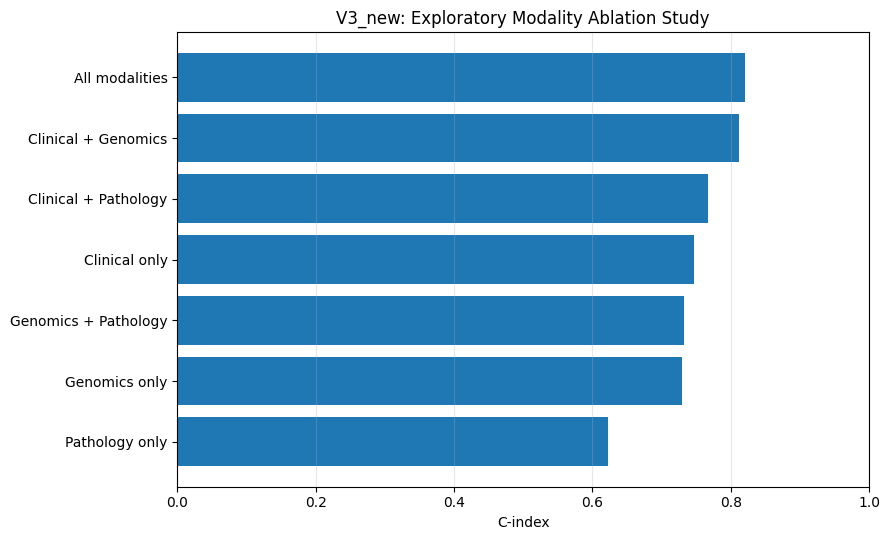

In [ ]:

# ============================================================
# V3_NEW ABLATION STUDY — ALL MODALITY COMBINATIONS
# Post-hoc exploratory evaluation.
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Device and prerequisites
# ------------------------------------------------------------
if "device" not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for name in ["MultimodalTransformer", "test_loader"]:
    if name not in globals():
        raise NameError(f"{name} is missing. Run its setup cells first.")

if "MODEL_CONFIG" not in globals():
    if "config" in globals() and isinstance(config, dict):
        MODEL_CONFIG = config
    elif "CONFIG" in globals() and isinstance(CONFIG, dict):
        MODEL_CONFIG = CONFIG
    else:
        MODEL_CONFIG = {
            "clinical_dim": 20,
            "genomic_dim": 200,
            "pathology_dim": 512,
            "embed_dim": 128,
            "num_heads": 4,
            "num_layers": 2,
            "dropout": 0.3,
        }

print("Device:", device)
print("Model config:", MODEL_CONFIG)
print("Test dataset size:", len(test_loader.dataset))

# ------------------------------------------------------------
# 2. Load V3_new checkpoint — NOT V2
# Use the same Drive root as your successful V3 evaluation.
# ------------------------------------------------------------
BASE_DIR = "/content/ggdrive/MyDrive/TCGA_BRCA"

# V3_CHECKPOINT_PATH = os.path.join(
#     BASE_DIR,
#     "pretraining_finetuning_differential_lr_v3_new",
#     "best_selective_finetuning_model.pt",
# )

# V3_CHECKPOINT_PATH = os.path.join(
#     BASE_DIR,
#     "pretraining_finetuning_differential_lr_v3_new",
#     "best_selective_finetuning_v3_seed42_verified.pt",
# )
V3_CHECKPOINT_PATH = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "pretraining_finetuning_differential_lr_v3_gpu_run2/"
    "best_selective_finetuning_v3_gpu_seed42.pt"
)

assert os.path.isfile(V3_CHECKPOINT_PATH), (
    f"V3_new checkpoint not found:\n{V3_CHECKPOINT_PATH}\n"
    "If your successful evaluation used /content/gdrive instead "
    "of /content/ggdrive, change BASE_DIR to that exact working path."
)

try:
    checkpoint = torch.load(
        V3_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(V3_CHECKPOINT_PATH, map_location=device)

if not isinstance(checkpoint, dict):
    raise TypeError("Unexpected checkpoint format.")

state_dict = None
for key in ("model_state_dict", "state_dict", "model_state"):
    if key in checkpoint and isinstance(checkpoint[key], dict):
        state_dict = checkpoint[key]
        break

# Also support a checkpoint that is itself a state_dict.
if state_dict is None:
    if checkpoint and all(torch.is_tensor(v) for v in checkpoint.values()):
        state_dict = checkpoint
    else:
        raise KeyError(
            "Could not find model_state_dict, state_dict, or model_state. "
            f"Checkpoint keys: {list(checkpoint.keys())}"
        )

if state_dict and all(k.startswith("module.") for k in state_dict):
    state_dict = {
        k[len("module."):]: v for k, v in state_dict.items()
    }

# Create a fresh model so the existing global model is not overwritten.
ablation_model = MultimodalTransformer(MODEL_CONFIG).to(device)
ablation_model.load_state_dict(state_dict, strict=True)
ablation_model.eval()

print("\nV3_new checkpoint loaded successfully.")
print("Checkpoint:", V3_CHECKPOINT_PATH)

# ------------------------------------------------------------
# 3. Define the six modality combinations
# ------------------------------------------------------------
ablation_configs = {
    "Clinical only": {
        "clinical": True, "genomic": False, "pathology": False
    },
    "Genomics only": {
        "clinical": False, "genomic": True, "pathology": False
    },
    "Pathology only": {
        "clinical": False, "genomic": False, "pathology": True
    },
    "Clinical + Genomics": {
        "clinical": True, "genomic": True, "pathology": False
    },
    "Clinical + Pathology": {
        "clinical": True, "genomic": False, "pathology": True
    },
    "Genomics + Pathology": {
        "clinical": False, "genomic": True, "pathology": True
    },
    "All modalities": {
        "clinical": True, "genomic": True, "pathology": True
    },
}

# ------------------------------------------------------------
# 4. Predict using the selected modalities
# ------------------------------------------------------------
def predict_survival_ablation(model, loader, modalities):
    model.eval()
    all_risk, all_survival, all_events = [], [], []

    with torch.inference_mode():
        for batch in loader:
            clinical = batch["clinical"].to(device)
            genomic = batch["genomic"].to(device)
            pathology = batch["pathology"].to(device)
            mask = batch["mask"].to(device)

            survival = batch["survival"].detach().cpu().numpy().reshape(-1)
            events = batch["event"].detach().cpu().numpy().reshape(-1)

            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities=modalities,
            )

            risk = output["survival"].detach().cpu().numpy().reshape(-1)

            all_risk.extend(risk.tolist())
            all_survival.extend(survival.tolist())
            all_events.extend(events.tolist())

    return (
        np.asarray(all_risk, dtype=float),
        np.asarray(all_survival, dtype=float),
        np.asarray(all_events, dtype=int),
    )

# ------------------------------------------------------------
# 5. Evaluate C-index for each modality combination
# ------------------------------------------------------------
ablation_results = []

for name, modalities in ablation_configs.items():
    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    risk, survival, events = predict_survival_ablation(
        ablation_model,
        test_loader,
        modalities,
    )

    if not (len(risk) == len(survival) == len(events)):
        raise ValueError(f"Prediction/label length mismatch for {name}.")

    if not (
        np.isfinite(risk).all()
        and np.isfinite(survival).all()
        and np.isin(events, [0, 1]).all()
        and (survival > 0).all()
    ):
        raise ValueError(f"Invalid predictions or labels for {name}.")

    if events.sum() == 0:
        raise ValueError("The test set has no observed events.")

    # Keep the same risk direction as your original evaluation.
    c_index = float(
        concordance_index(survival, -risk, events)
    )

    print("Test patients:", len(survival))
    print("Observed events:", int(events.sum()))
    print(f"C-index: {c_index:.4f}")

    ablation_results.append({
        "Model": name,
        "C-index": c_index,
        "N test": len(survival),
        "Events": int(events.sum()),
    })

# ------------------------------------------------------------
# 6. Display and save results
# ------------------------------------------------------------
ablation_df = pd.DataFrame(ablation_results)
ablation_df = ablation_df.sort_values(
    "C-index", ascending=False
).reset_index(drop=True)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "ablation_study_v3_new_exploratory",
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

csv_path = os.path.join(
    OUTPUT_DIR, "v3_new_ablation_c_index.csv"
)
ablation_df.to_csv(csv_path, index=False)

print("\n" + "=" * 75)
print("V3_NEW — ABLATION STUDY RESULTS")
print("=" * 75)
display(ablation_df)

print("Results saved to:", csv_path)

# ------------------------------------------------------------
# 7. Plot C-index
# ------------------------------------------------------------
plot_df = ablation_df.sort_values("C-index", ascending=True)

plt.figure(figsize=(9, 5.5))
plt.barh(plot_df["Model"], plot_df["C-index"])
plt.xlabel("C-index")
plt.title("V3_new: Exploratory Modality Ablation Study")
plt.xlim(0.0, 1.0)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


##Test inference

In [ ]:
# ============================================================
# TEST INFERENCE (RFS ONLY)
# ============================================================


def predict_test_rfs(
    model,
    loader,
    use_modalities=None
):

    model.eval()

    all_risk = []
    all_survival = []
    all_events = []


    with torch.no_grad():

        for batch in loader:


            clinical = batch["clinical"].to(device)

            genomic = batch["genomic"].to(device)

            pathology = batch["pathology"].to(device)

            mask = batch["mask"].to(device)


            survival = batch["survival"].float().to(device)

            event = batch["event"].float().to(device)



            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities=use_modalities
            )


            # only survival output exists now
            risk = output["survival"]


            risk = risk.view(-1)


            all_risk.extend(
                risk.cpu().numpy()
            )


            all_survival.extend(
                survival.cpu().numpy()
            )


            all_events.extend(
                event.cpu().numpy()
            )



    return (
        np.array(all_risk),
        np.array(all_survival),
        np.array(all_events)
    )

In [ ]:
test_risk, test_survival, test_events = predict_test_rfs(
    model,
    test_loader,
    {
        "clinical": True,
        "genomic": True,
        "pathology": True
    }
)


print("="*70)
print("TEST RFS PREDICTION COMPLETE")
print("="*70)

print("Risk:", test_risk.shape)
print("Survival:", test_survival.shape)
print("Events:", test_events.shape)

TEST RFS PREDICTION COMPLETE
Risk: (52,)
Survival: (52,)
Events: (52,)


##Validation inference

In [ ]:
# ============================================================
# VALIDATION INFERENCE (RFS)
# ============================================================


def predict_validation(
    model,
    loader,
    use_modalities=None
):

    model.eval()

    all_risk = []
    all_survival = []
    all_events = []


    with torch.no_grad():

        for batch in loader:


            clinical = batch["clinical"].to(device)

            genomic = batch["genomic"].to(device)

            pathology = batch["pathology"].to(device)

            mask = batch["mask"].to(device)


            survival_time = batch["survival"].float().to(device)

            event = batch["event"].float().to(device)



            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities=use_modalities
            )


            survival_pred = output["survival"]


            survival_pred = survival_pred.view(-1)


            all_risk.extend(
                survival_pred.cpu().numpy()
            )


            all_survival.extend(
                survival_time.cpu().numpy()
            )


            all_events.extend(
                event.cpu().numpy()
            )



    return (
        np.array(all_risk),
        np.array(all_survival),
        np.array(all_events)
    )



val_risk, val_survival, val_events = predict_validation(
    model,
    val_loader,
    {
        "clinical": True,
        "genomic": True,
        "pathology": True
    }
)



print("="*70)
print("VALIDATION RFS PREDICTION COMPLETE")
print("="*70)


print(
    "Validation risk:",
    val_risk.shape
)


print(
    "Validation survival:",
    val_survival.shape
)


print(
    "Validation events:",
    val_events.shape
)

VALIDATION RFS PREDICTION COMPLETE
Validation risk: (49,)
Validation survival: (49,)
Validation events: (49,)


##Evaluation Metrics

##Survival evaluation (C-index)

In [ ]:

# ============================================================
# LOAD PRIMARY V3 CHECKPOINT
# ============================================================

import os
import torch

CHECKPOINT_PATH = (
    "/content/ggdrive/MyDrive/TCGA_BRCA/"
    "pretraining_finetuning_differential_lr_v3_gpu_run2/"
    "best_selective_finetuning_v3_gpu_seed42.pt"
)

assert os.path.isfile(CHECKPOINT_PATH), (
    f"Checkpoint not found: {CHECKPOINT_PATH}"
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded.")
print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))


Checkpoint loaded.
Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'val_cindex', 'val_cox_loss', 'train_cox_loss', 'model_config', 'encoder_lr', 'other_lr', 'seed']


In [ ]:
# ============================================================
# VALIDATION SURVIVAL INFERENCE
# ============================================================


def predict_validation(
    model,
    loader,
    use_modalities=None
):

    model.eval()

    all_risk = []
    all_survival = []
    all_events = []


    with torch.no_grad():

        for batch in loader:


            clinical = batch["clinical"].to(device)

            genomic = batch["genomic"].to(device)

            pathology = batch["pathology"].to(device)

            mask = batch["mask"].to(device)


            survival = batch["survival"].numpy()
            event = batch["event"].numpy()



            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities=use_modalities
            )


            risk = output["survival"]


            all_risk.extend(
                risk.view(-1)
                .cpu()
                .numpy()
            )


            all_survival.extend(
                survival
            )


            all_events.extend(
                event
            )


    return (
        np.array(all_risk),
        np.array(all_survival),
        np.array(all_events)
    )


In [ ]:
val_risk, val_survival, val_events = predict_validation(
    model,
    val_loader,
    {
        "clinical": True,
        "genomic": True,
        "pathology": True
    }
)


print(val_risk.shape)
print(val_survival.shape)
print(val_events.shape)

(49,)
(49,)
(49,)


In [ ]:
# ============================================================
# TEST SURVIVAL INFERENCE
# ============================================================


def predict_test_survival(
    model,
    loader,
    use_modalities=None
):

    model.eval()

    all_risk = []
    all_survival = []
    all_events = []


    with torch.no_grad():

        for batch in loader:


            clinical = batch["clinical"].to(device)

            genomic = batch["genomic"].to(device)

            pathology = batch["pathology"].to(device)

            mask = batch["mask"].to(device)



            survival = batch["survival"].cpu().numpy()

            event = batch["event"].cpu().numpy()



            output = model(
                clinical,
                genomic,
                pathology,
                mask,
                use_modalities=use_modalities
            )


            risk = output["survival"]


            all_risk.extend(
                risk.view(-1)
                .cpu()
                .numpy()
            )


            all_survival.extend(
                survival
            )


            all_events.extend(
                event
            )


    return (
        np.array(all_risk),
        np.array(all_survival),
        np.array(all_events)
    )

In [ ]:
test_risk, test_survival, test_events = predict_test_survival(
    model,
    test_loader,
    {
        "clinical": True,
        "genomic": True,
        "pathology": True
    }
)

In [ ]:

# ============================================================
# TEST C-INDEX: BOOTSTRAP 95% CONFIDENCE INTERVAL
# ============================================================

import numpy as np
from lifelines.utils import concordance_index

N_BOOTSTRAPS = 1000
rng = np.random.RandomState(42)

n = len(test_survival)
boot_scores = []

for _ in range(N_BOOTSTRAPS):
    indices = rng.choice(n, size=n, replace=True)

    try:
        score = concordance_index(
            test_survival[indices],
            -test_risk[indices],
            test_events[indices]
        )

        if np.isfinite(score):
            boot_scores.append(score)

    except (ZeroDivisionError, ValueError):
        continue

boot_scores = np.asarray(boot_scores)

print("=" * 70)
print("V3 PRIMARY CHECKPOINT — TEST BOOTSTRAP C-INDEX")
print("=" * 70)
print("Requested bootstrap samples:", N_BOOTSTRAPS)
print("Valid bootstrap samples:", len(boot_scores))

if len(boot_scores) < 100:
    print(
        "WARNING: Too few valid bootstrap samples for a "
        "reliable percentile confidence interval."
    )
else:
    ci_lower, ci_upper = np.percentile(
        boot_scores, [2.5, 97.5]
    )

    print(f"Bootstrap mean: {boot_scores.mean():.4f}")
    print(f"Bootstrap SD:   {boot_scores.std(ddof=1):.4f}")
    print(f"95% CI:         ({ci_lower:.4f}, {ci_upper:.4f})")


V3 PRIMARY CHECKPOINT — TEST BOOTSTRAP C-INDEX
Requested bootstrap samples: 1000
Valid bootstrap samples: 1000
Bootstrap mean: 0.8184
Bootstrap SD:   0.0662
95% CI:         (0.6758, 0.9305)


In [ ]:
from lifelines.utils import concordance_index


# ============================================================
# FINAL TEST C-INDEX — V3 PRIMARY CHECKPOINT
# ============================================================

c_index = concordance_index(
    test_survival,
    -test_risk,
    test_events
)

print("=" * 70)
print("RFS PERFORMANCE — V3 SELECTIVE FINE-TUNING")
print("=" * 70)
print(f"Test patients: {len(test_survival)}")
print(f"Observed events: {int(np.sum(test_events == 1))}")
print(f"C-index: {c_index:.4f}")

if len(boot_scores) >= 100:
    print(f"Bootstrap 95% CI: ({ci_lower:.4f}, {ci_upper:.4f})")
else:
    print("Bootstrap 95% CI: not reported; too few valid resamples")


RFS PERFORMANCE — V3 SELECTIVE FINE-TUNING
Test patients: 52
Observed events: 12
C-index: 0.8214
Bootstrap 95% CI: (0.6758, 0.9305)


##Kaplan-Meier risk groups

In [ ]:
import numpy as np

print("Test patients:", len(test_risk))
print("Survival times:", len(test_survival))
print("Event indicators:", len(test_events))
print("Observed events:", int(np.sum(test_events)))
print("Censored patients:", int(len(test_events) - np.sum(test_events)))

assert len(test_risk) == len(test_survival) == len(test_events)
assert np.all(np.isfinite(test_risk))
assert np.all(np.isfinite(test_survival))
assert np.all(np.isfinite(test_events))

print("Risk range:", np.min(test_risk), "to", np.max(test_risk))
print("Survival time range:", np.min(test_survival), "to", np.max(test_survival))

Test patients: 52
Survival times: 52
Event indicators: 52
Observed events: 12
Censored patients: 40
Risk range: -0.55459744 to 0.50707436
Survival time range: 10.0 to 4088.0


Risk-group summary
--------------------------------------------------
Low risk: n=17, events=1
Medium risk: n=18, events=5
High risk: n=17, events=6


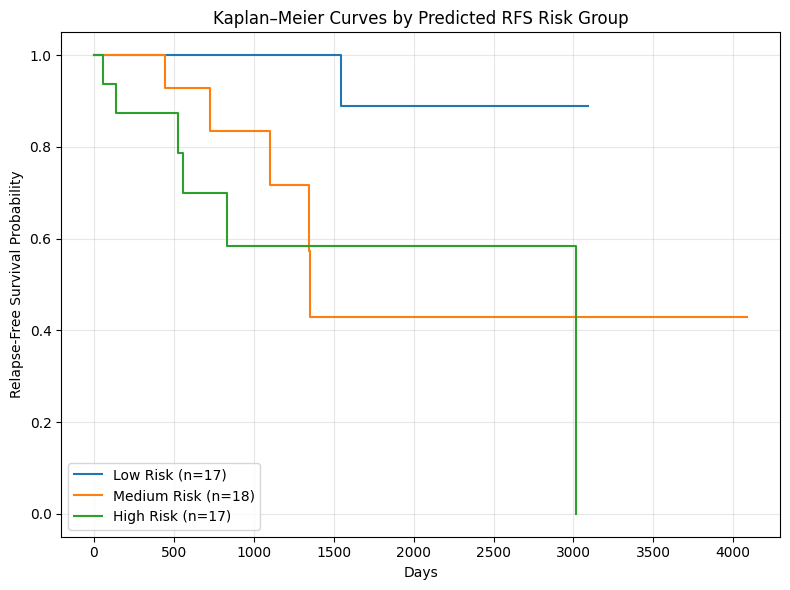

MULTI-GROUP LOG-RANK TEST
Test statistic: 9.6663
p-value: 0.007961


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test

# Convert predictions and outcomes to NumPy arrays
test_risk = np.asarray(test_risk).reshape(-1)
test_survival = np.asarray(test_survival).reshape(-1)
test_events = np.asarray(test_events).reshape(-1).astype(int)

assert len(test_risk) == len(test_survival) == len(test_events)
assert np.all(np.isfinite(test_risk))
assert np.all(np.isfinite(test_survival))
assert np.all(np.isin(test_events, [0, 1]))

# Divide patients into three groups based on predicted risk
q1 = np.percentile(test_risk, 33.33)
q2 = np.percentile(test_risk, 66.67)

low_risk = test_risk <= q1
medium_risk = (test_risk > q1) & (test_risk <= q2)
high_risk = test_risk > q2

print("Risk-group summary")
print("-" * 50)

for name, mask in [
    ("Low risk", low_risk),
    ("Medium risk", medium_risk),
    ("High risk", high_risk),
]:
    print(
        f"{name}: n={mask.sum()}, "
        f"events={test_events[mask].sum()}"
    )

# Plot Kaplan–Meier curves
kmf = KaplanMeierFitter()
plt.figure(figsize=(8, 6))

for name, mask in [
    ("Low Risk", low_risk),
    ("Medium Risk", medium_risk),
    ("High Risk", high_risk),
]:
    if mask.sum() == 0:
        print(f"Warning: {name} group is empty; skipping.")
        continue

    kmf.fit(
        durations=test_survival[mask],
        event_observed=test_events[mask],
        label=f"{name} (n={mask.sum()})"
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Kaplan–Meier Curves by Predicted RFS Risk Group")
plt.xlabel("Days")
plt.ylabel("Relapse-Free Survival Probability")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Multigroup log-rank test
risk_group = np.select(
    [low_risk, medium_risk, high_risk],
    [0, 1, 2],
    default=-1
)

assert np.all(risk_group >= 0)

result = multivariate_logrank_test(
    event_durations=test_survival,
    groups=risk_group,
    event_observed=test_events
)

print("=" * 60)
print("MULTI-GROUP LOG-RANK TEST")
print("=" * 60)
print(f"Test statistic: {result.test_statistic:.4f}")
print(f"p-value: {result.p_value:.6f}")


##Time-dependent AUC

In [ ]:

import numpy as np
from sksurv.util import Surv

# Extract training survival outcomes from the existing dataset
train_survival = np.array([
    float(train_dataset[i]["survival"].item())
    for i in range(len(train_dataset))
])

train_events = np.array([
    bool(train_dataset[i]["event"].item())
    for i in range(len(train_dataset))
])

# Create the training survival object
y_train = Surv.from_arrays(
    event=train_events,
    time=train_survival
)

print("=" * 60)
print("TRAINING SURVIVAL DATA")
print("=" * 60)
print("Training patients:", len(train_survival))
print("Observed events:", int(train_events.sum()))
print("Censored patients:", int((~train_events).sum()))
print("Minimum survival time:", train_survival.min(), "days")
print("Maximum survival time:", train_survival.max(), "days")
print("Survival object preview:")
print(y_train[:5])


TRAINING SURVIVAL DATA
Training patients: 236
Observed events: 54
Censored patients: 182
Minimum survival time: 1.0 days
Maximum survival time: 8556.0 days
Survival object preview:
[(False,  313.) (False, 1004.) (False,  975.) (False,  397.)
 (False,  225.)]


In [ ]:
print("Test maximum survival time:", test_survival.max(), "days")
print("Test minimum survival time:", test_survival.min(), "days")
print("Test maximum follow-up:", test_survival.max() / 365.25, "years")

print("\nTraining maximum follow-up:", train_survival.max(), "days")
print("Training minimum follow-up:", train_survival.min(), "days")
print("Training observed events:", int(np.sum(train_events)))

Test maximum survival time: 4088.0 days
Test minimum survival time: 10.0 days
Test maximum follow-up: 11.192334 years

Training maximum follow-up: 8556.0 days
Training minimum follow-up: 1.0 days
Training observed events: 54


In [ ]:
import numpy as np
from sksurv.util import Surv

train_survival = np.asarray(train_survival).reshape(-1)
train_events = np.asarray(train_events).reshape(-1).astype(bool)

test_survival = np.asarray(test_survival).reshape(-1)
test_events = np.asarray(test_events).reshape(-1).astype(bool)
test_risk = np.asarray(test_risk).reshape(-1)

y_train = Surv.from_arrays(
    event=train_events,
    time=train_survival
)

y_test = Surv.from_arrays(
    event=test_events,
    time=test_survival
)

assert len(test_risk) == len(y_test)
assert len(train_survival) == len(train_events)
assert np.all(np.isfinite(test_risk))

print("Training survival object:", len(y_train), "patients")
print("Test survival object:", len(y_test), "patients")
print("Test events:", int(test_events.sum()))
print("Test censored:", int((~test_events).sum()))

Training survival object: 236 patients
Test survival object: 52 patients
Test events: 12
Test censored: 40


In [ ]:
# ============================================================
# DEFINE EVALUATION TIMES
# ============================================================

import numpy as np


evaluation_times = np.array(
    [
        3*365,      # 3 years
        5*365,      # 5 years
        10*365      # 10 years
    ]
)


print("="*70)
print("AUC EVALUATION TIMES")
print("="*70)

for t in evaluation_times:
    print(f"{t} days ({t/365:.0f} years)")

AUC EVALUATION TIMES
1095 days (3 years)
1825 days (5 years)
3650 days (10 years)


In [ ]:

from sksurv.metrics import cumulative_dynamic_auc

auc_values, mean_auc = cumulative_dynamic_auc(
    y_train,
    y_test,
    test_risk,
    evaluation_times
)

print("=" * 60)
print("TIME-DEPENDENT AUC — NEW MODEL")
print("=" * 60)

for years, auc in zip([3, 5, 10], auc_values):
    print(f"{years}-year AUC: {auc:.4f}")

print(f"\nMean AUC: {mean_auc:.4f}")


TIME-DEPENDENT AUC — NEW MODEL
3-year AUC: 0.9185
5-year AUC: 0.6891
10-year AUC: 0.7027

Mean AUC: 0.7650


##Integrated Brier Score (IBS)

In [ ]:

import numpy as np
from sksurv.metrics import integrated_brier_score

# --------------------------------------------------
# Validate inputs
# --------------------------------------------------
train_t = np.asarray(train_survival, dtype=float).reshape(-1)
train_e = np.asarray(train_events, dtype=bool).reshape(-1)
test_t = np.asarray(test_survival, dtype=float).reshape(-1)
test_e = np.asarray(test_events, dtype=bool).reshape(-1)

train_r = np.asarray(train_risk, dtype=float).reshape(-1)
test_r = np.asarray(test_risk, dtype=float).reshape(-1)

assert len(train_t) == len(train_e) == len(train_r)
assert len(test_t) == len(test_e) == len(test_r)
assert np.all(np.isfinite(train_r))
assert np.all(np.isfinite(test_r))

# --------------------------------------------------
# Estimate Cox baseline cumulative hazard using
# TRAINING outcomes and the current model's risks
# --------------------------------------------------
risk_center = np.max(train_r)
train_relative_risk = np.exp(train_r - risk_center)

event_times = np.unique(train_t[train_e])
baseline_hazard_increments = []

for t in event_times:
    events_at_t = np.sum((train_t == t) & train_e)
    at_risk = train_t >= t
    denominator = train_relative_risk[at_risk].sum()

    baseline_hazard_increments.append(events_at_t / denominator)

baseline_cumhaz = np.cumsum(baseline_hazard_increments)

# --------------------------------------------------
# Choose evaluation times
# Use the central 10th–90th percentile of test follow-up
# --------------------------------------------------
times = np.linspace(
    np.percentile(test_t, 10),
    np.percentile(test_t, 90),
    100
)

# Baseline cumulative hazard at each evaluation time
indices = np.searchsorted(event_times, times, side="right") - 1
H0 = np.zeros(len(times))

has_event_time = indices >= 0
H0[has_event_time] = baseline_cumhaz[indices[has_event_time]]

# --------------------------------------------------
# Convert Cox risk scores to predicted survival
# --------------------------------------------------
test_relative_risk = np.exp(test_r - risk_center)

survival_prob = np.exp(
    -np.outer(test_relative_risk, H0)
)

# Numerical and shape checks
assert survival_prob.shape == (len(test_t), len(times))
assert np.all(np.isfinite(survival_prob))
assert np.all((survival_prob >= 0) & (survival_prob <= 1))

# --------------------------------------------------
# Integrated Brier Score
# --------------------------------------------------
ibs = integrated_brier_score(
    y_train,
    y_test,
    survival_prob,
    times
)

print("=" * 60)
print("INTEGRATED BRIER SCORE — NEW MODEL")
print("=" * 60)
print(f"IBS: {ibs:.4f}")
print(f"Evaluation range: {times[0]:.1f}–{times[-1]:.1f} days")
print(f"Training patients: {len(train_t)}")
print(f"Test patients: {len(test_t)}")


INTEGRATED BRIER SCORE — NEW MODEL
IBS: 0.1855
Evaluation range: 248.2–2913.6 days
Training patients: 236
Test patients: 52


##Survival Calibration Curve

NEWER MODEL — RISK GROUP SUMMARY
             Patients  Observed_Events  Median_Followup_Days
group                                                       
Low Risk           17                1                1543.0
Medium Risk        17                5                 729.0
High Risk          18                6                 565.5


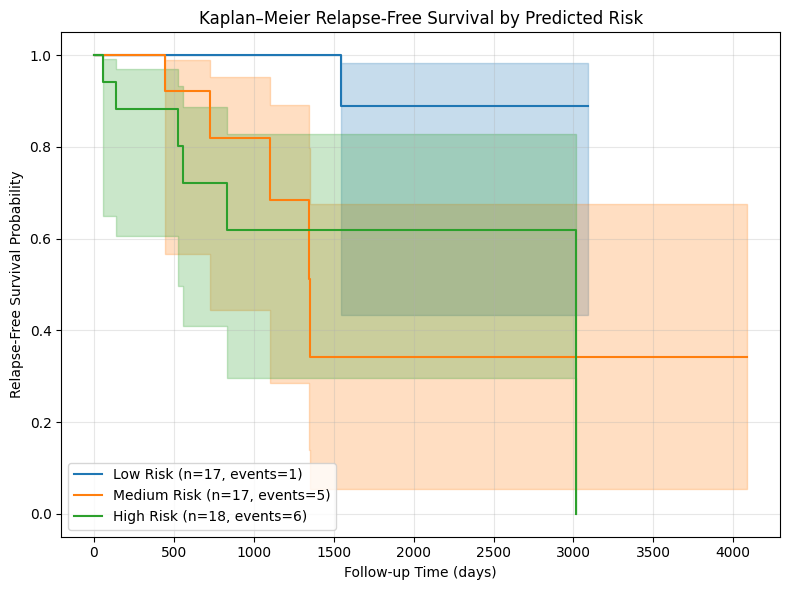

In [ ]:

# ============================================================
# SURVIVAL ANALYSIS — RISK GROUPS (NEWER MODEL)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# 1. Confirm that the newer model's test predictions are being used
risk_df = pd.DataFrame({
    "risk": np.asarray(test_risk).reshape(-1),
    "time": np.asarray(test_survival).reshape(-1),
    "event": np.asarray(test_events).reshape(-1).astype(bool)
})

# 2. Validate the test data
assert len(risk_df) == 52, f"Expected 52 test patients, found {len(risk_df)}"
assert risk_df[["risk", "time"]].notna().all().all(), "Missing risk/time values"
assert np.isfinite(risk_df["risk"]).all(), "Non-finite risk scores"
assert (risk_df["time"] > 0).all(), "Non-positive survival times"

# 3. Divide patients into three risk groups
risk_df["group"] = pd.qcut(
    risk_df["risk"],
    q=3,
    labels=["Low Risk", "Medium Risk", "High Risk"],
    duplicates="drop"
)

# 4. Print group sizes and observed events
print("=" * 55)
print("NEWER MODEL — RISK GROUP SUMMARY")
print("=" * 55)

print(
    risk_df.groupby("group", observed=False)
    .agg(
        Patients=("time", "size"),
        Observed_Events=("event", "sum"),
        Median_Followup_Days=("time", "median")
    )
)

# 5. Plot Kaplan–Meier survival curves
plt.figure(figsize=(8, 6))
kmf = KaplanMeierFitter()

for group in ["Low Risk", "Medium Risk", "High Risk"]:
    subset = risk_df[risk_df["group"] == group]

    if len(subset) == 0:
        continue

    kmf.fit(
        durations=subset["time"],
        event_observed=subset["event"],
        label=f"{group} (n={len(subset)}, events={int(subset['event'].sum())})"
    )

    kmf.plot_survival_function(ci_show=True)

plt.title("Kaplan–Meier Relapse-Free Survival by Predicted Risk")
plt.xlabel("Follow-up Time (days)")
plt.ylabel("Relapse-Free Survival Probability")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


##Investigation cells

In [ ]:
# ============================================================
# COMBINE ALL SPLITS FOR INVESTIGATION
# ============================================================

df_all = pd.concat(
    [train, validation, test],
    axis=0,
    ignore_index=True
)

print("Combined dataframe shape:", df_all.shape)
print("Total patients:", len(df_all))

Combined dataframe shape: (357, 224)
Total patients: 357


##Investigation 1 — Check the pathology branch

In [ ]:
# ============================================================
# PATCH STATISTICS
# ============================================================

patch_counts = []

for uuid in df_all["file_uuid"]:

    pathology, mask = load_pathology_features(
        uuid,
        MAX_PATCHES
    )

    patch_counts.append(mask.sum())

patch_counts = np.array(patch_counts)

print("="*70)
print("PATCH STATISTICS")
print("="*70)

print("MAX_PATCHES =", MAX_PATCHES)

print("Minimum patches :", patch_counts.min())
print("Maximum patches :", patch_counts.max())
print("Average patches :", patch_counts.mean())
print("Median patches  :", np.median(patch_counts))

print()
print("Patients using ALL patches:",
      np.sum(patch_counts == MAX_PATCHES))

print("Patients with fewer patches:",
      np.sum(patch_counts < MAX_PATCHES))

PATCH STATISTICS
MAX_PATCHES = 512
Minimum patches : 9.0
Maximum patches : 512.0
Average patches : 501.36414
Median patches  : 512.0

Patients using ALL patches: 339
Patients with fewer patches: 18


##Investigation 2 — Verify recurrence labels

In [ ]:
# ============================================================
# LABEL CHECK
# ============================================================

print("="*70)
print("RECURRENCE LABEL CHECK")
print("="*70)

print(df_all["event"].value_counts(dropna=False))

print()

print("Missing labels:",
      df_all["event"].isna().sum())

print()

print("Unique labels:",
      df_all["event"].unique())

RECURRENCE LABEL CHECK
event
0    266
1     91
Name: count, dtype: int64

Missing labels: 0

Unique labels: [1 0]


##Investigation 3 — Survival statistics

In [ ]:
# ============================================================
# SURVIVAL STATISTICS
# ============================================================

print("="*70)
print("SURVIVAL STATISTICS")
print("="*70)

print(df_all["survival_time"].describe())

print()

print("Minimum:",
      df_all["survival_time"].min())

print("Maximum:",
      df_all["survival_time"].max())

print()

print("Number of censored:",
      (df_all["event"]==0).sum())

print("Number of events:",
      (df_all["event"]==1).sum())

SURVIVAL STATISTICS
count     357.000000
mean     1288.647059
std      1372.999560
min         1.000000
25%       408.000000
50%       821.000000
75%      1692.000000
max      8556.000000
Name: survival_time, dtype: float64

Minimum: 1.0
Maximum: 8556.0

Number of censored: 266
Number of events: 91


##Investigation 5 — Check prediction probabilities

PREDICTION DISTRIBUTION
Minimum probability: 0.23071307
Maximum probability: 0.6684415
Mean probability: 0.43150553
Median probability: 0.42414784


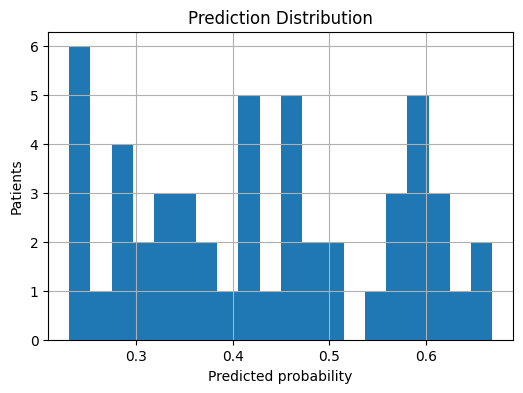

In [ ]:
# ============================================================
# PREDICTION DISTRIBUTION
# ============================================================

print("="*70)
print("PREDICTION DISTRIBUTION")
print("="*70)

print("Minimum probability:",
      test_probs.min())

print("Maximum probability:",
      test_probs.max())

print("Mean probability:",
      test_probs.mean())

print("Median probability:",
      np.median(test_probs))

# Histogram

import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))

plt.hist(
    test_probs,
    bins=20
)

plt.xlabel("Predicted probability")
plt.ylabel("Patients")

plt.title("Prediction Distribution")

plt.grid()

plt.show()

##Checking the data again for the RFS and DFS (more confirmation)

In [ ]:
import pandas as pd
import os


# ============================================================
# PATHS
# ============================================================

FOLLOW_UP_PATH = "/content/gdrive/MyDrive/BreastCanser-DataSet/follow_up.tsv"

CLINICAL_PATH = "/content/gdrive/MyDrive/BreastCanser-DataSet/Human__TCGA_BRCA__MS__Clinical__Clinical__01_28_2016__BI__Clinical__Firehose.tsv"



# ============================================================
# LOAD DATA
# ============================================================

follow_up = pd.read_csv(
    FOLLOW_UP_PATH,
    sep="\t",
    low_memory=False
)


clinical = pd.read_csv(
    CLINICAL_PATH,
    sep="\t",
    low_memory=False
)



print("="*70)
print("FILES LOADED")
print("="*70)


print("Follow-up shape:")
print(follow_up.shape)


print("\nClinical shape:")
print(clinical.shape)

FILES LOADED
Follow-up shape:
(9427, 152)

Clinical shape:
(20, 1098)


In [ ]:
print("="*70)
print("FOLLOW UP COLUMNS")
print("="*70)

for i, col in enumerate(follow_up.columns):
    print(i, col)



print("\n")


print("="*70)
print("CLINICAL COLUMNS")
print("="*70)

for i, col in enumerate(clinical.columns):
    print(i, col)

FOLLOW UP COLUMNS
0 project.project_id
1 cases.case_id
2 cases.submitter_id
3 follow_ups.adverse_event
4 follow_ups.adverse_event_grade
5 follow_ups.barretts_esophagus_goblet_cells_present
6 follow_ups.cause_of_response
7 follow_ups.days_to_adverse_event
8 follow_ups.days_to_first_event
9 follow_ups.days_to_follow_up
10 follow_ups.days_to_imaging
11 follow_ups.days_to_progression
12 follow_ups.days_to_progression_free
13 follow_ups.days_to_recurrence
14 follow_ups.discontiguous_lesion_count
15 follow_ups.disease_response
16 follow_ups.ecog_performance_status
17 follow_ups.evidence_of_progression_type
18 follow_ups.evidence_of_recurrence_type
19 follow_ups.first_event
20 follow_ups.follow_up_id
21 follow_ups.histologic_progression
22 follow_ups.history_of_tumor
23 follow_ups.history_of_tumor_type
24 follow_ups.hormone_replacement_therapy_type
25 follow_ups.imaging_anatomic_site
26 follow_ups.imaging_findings
27 follow_ups.imaging_result
28 follow_ups.imaging_suv
29 follow_ups.imaging_su

In [ ]:
keywords = [
    "recurr",
    "progress",
    "disease",
    "event",
    "survival",
    "death",
    "follow",
    "new",
    "relapse"
]


print("="*70)
print("FOLLOW UP RELEVANT COLUMNS")
print("="*70)


for col in follow_up.columns:

    if any(k in col.lower() for k in keywords):
        print(col)



print("\n")


print("="*70)
print("CLINICAL RELEVANT COLUMNS")
print("="*70)


for col in clinical.columns:

    if any(k in col.lower() for k in keywords):
        print(col)

FOLLOW UP RELEVANT COLUMNS
follow_ups.adverse_event
follow_ups.adverse_event_grade
follow_ups.barretts_esophagus_goblet_cells_present
follow_ups.cause_of_response
follow_ups.days_to_adverse_event
follow_ups.days_to_first_event
follow_ups.days_to_follow_up
follow_ups.days_to_imaging
follow_ups.days_to_progression
follow_ups.days_to_progression_free
follow_ups.days_to_recurrence
follow_ups.discontiguous_lesion_count
follow_ups.disease_response
follow_ups.ecog_performance_status
follow_ups.evidence_of_progression_type
follow_ups.evidence_of_recurrence_type
follow_ups.first_event
follow_ups.follow_up_id
follow_ups.histologic_progression
follow_ups.history_of_tumor
follow_ups.history_of_tumor_type
follow_ups.hormone_replacement_therapy_type
follow_ups.imaging_anatomic_site
follow_ups.imaging_findings
follow_ups.imaging_result
follow_ups.imaging_suv
follow_ups.imaging_suv_max
follow_ups.imaging_type
follow_ups.karnofsky_performance_status
follow_ups.peritoneal_washing_results
follow_ups.proc

In [ ]:
rec_cols = [
    c for c in follow_up.columns
    if "recurr" in c.lower()
]


print("Recurrence columns:")
print(rec_cols)


if len(rec_cols) > 0:

    for c in rec_cols:

        print("\nCOLUMN:", c)
        print(
            follow_up[c].value_counts(dropna=False).head(20)
        )

Recurrence columns:
['follow_ups.days_to_recurrence', 'follow_ups.evidence_of_recurrence_type', 'follow_ups.progression_or_recurrence', 'follow_ups.progression_or_recurrence_anatomic_site', 'follow_ups.progression_or_recurrence_type']

COLUMN: follow_ups.days_to_recurrence
follow_ups.days_to_recurrence
'--     9398
596        2
136        1
181        1
155        1
301        1
746        1
1516       1
2330       1
1645       1
648        1
1034       1
3287       1
431        1
756        1
966        1
667        1
419        1
1709       1
2989       1
Name: count, dtype: int64

COLUMN: follow_ups.evidence_of_recurrence_type
follow_ups.evidence_of_recurrence_type
'--    9427
Name: count, dtype: int64

COLUMN: follow_ups.progression_or_recurrence
follow_ups.progression_or_recurrence
'--    9286
Yes     141
Name: count, dtype: int64

COLUMN: follow_ups.progression_or_recurrence_anatomic_site
follow_ups.progression_or_recurrence_anatomic_site
'--                                      

In [ ]:
surv_cols = [
    c for c in clinical.columns
    if (
        "death" in c.lower()
        or "last" in c.lower()
        or "follow" in c.lower()
        or "survival" in c.lower()
    )
]


print("="*70)
print("SURVIVAL RELATED COLUMNS")
print("="*70)


for c in surv_cols:
    print(c)

SURVIVAL RELATED COLUMNS


In [ ]:
surv_cols = [
    c for c in clinical.columns
    if (
        "death" in c.lower()
        or "last" in c.lower()
        or "follow" in c.lower()
        or "survival" in c.lower()
    )
]


print("="*70)
print("SURVIVAL RELATED COLUMNS")
print("="*70)


for c in surv_cols:
    print(c)

SURVIVAL RELATED COLUMNS


In [ ]:
print("="*70)
print("FOLLOW UP SAMPLE")
print("="*70)

display(
    follow_up.head()
)

FOLLOW UP SAMPLE


,project.project_id,cases.case_id,cases.submitter_id,follow_ups.adverse_event,follow_ups.adverse_event_grade,follow_ups.barretts_esophagus_goblet_cells_present,follow_ups.cause_of_response,follow_ups.days_to_adverse_event,follow_ups.days_to_first_event,follow_ups.days_to_follow_up,...,other_clinical_attributes.undescended_testis_corrected,other_clinical_attributes.undescended_testis_corrected_age,other_clinical_attributes.undescended_testis_corrected_age_range,other_clinical_attributes.undescended_testis_corrected_laterality,other_clinical_attributes.undescended_testis_corrected_method,other_clinical_attributes.undescended_testis_history,other_clinical_attributes.undescended_testis_history_laterality,other_clinical_attributes.viral_hepatitis_serology_tests,other_clinical_attributes.weeks_gestation_at_birth,other_clinical_attributes.weight
0,TCGA-BRCA,001cef41-ff86-4d3f-a140-a647ac4b10a1,TCGA-E2-A1IU,'--,'--,'--,'--,'--,'--,337,...,'--,'--,'--,'--,'--,'--,'--,'--,'--,'--
1,TCGA-BRCA,001cef41-ff86-4d3f-a140-a647ac4b10a1,TCGA-E2-A1IU,'--,'--,'--,'--,'--,'--,127,...,'--,'--,'--,'--,'--,'--,'--,'--,'--,'--
2,TCGA-BRCA,001cef41-ff86-4d3f-a140-a647ac4b10a1,TCGA-E2-A1IU,'--,'--,'--,'--,'--,'--,337,...,'--,'--,'--,'--,'--,'--,'--,'--,'--,'--
3,TCGA-BRCA,001cef41-ff86-4d3f-a140-a647ac4b10a1,TCGA-E2-A1IU,'--,'--,'--,'--,'--,'--,'--,...,'--,'--,'--,'--,'--,'--,'--,'--,'--,'--
4,TCGA-BRCA,001cef41-ff86-4d3f-a140-a647ac4b10a1,TCGA-E2-A1IU,'--,'--,'--,'--,'--,'--,'--,...,'--,'--,'--,'--,'--,'--,'--,'--,'--,'--


In [ ]:
print("="*70)
print("UNIQUE PATIENTS")
print("="*70)


for name, df in [
    ("Clinical", clinical),
    ("Follow-up", follow_up)
]:

    possible = [
        c for c in df.columns
        if "barcode" in c.lower()
        or "patient" in c.lower()
    ]

    print("\n", name)
    print(possible)

UNIQUE PATIENTS

 Clinical
[]

 Follow-up
[]


In [ ]:
import pandas as pd
import numpy as np

# replace with your dataframe names if different
fu = follow_up.copy()

patient_col = "cases.submitter_id"


# convert '--' to missing
fu = fu.replace("--", np.nan)


print("="*70)
print("PATIENT COUNT")
print("="*70)

print("Unique patients:", fu[patient_col].nunique())


# Recurrence events
print("\nRECURRENCE EVENTS")
print("="*70)

recurrence = (
    fu.groupby(patient_col)
    ["follow_ups.progression_or_recurrence"]
    .apply(lambda x: (x=="Yes").any())
)

print(recurrence.value_counts())


# Recurrence time
print("\nRECURRENCE TIME AVAILABLE")
print("="*70)

rec_time = (
    fu.groupby(patient_col)
    ["follow_ups.days_to_recurrence"]
    .apply(lambda x: x.notna().any())
)

print(rec_time.value_counts())


# Progression / recurrence type
print("\nPROGRESSION/RECURRENCE EVENTS")
print("="*70)

print(
    fu["follow_ups.progression_or_recurrence_type"]
    .value_counts(dropna=False)
)


# Death information from clinical file
print("\nCLINICAL ATTRIBUTES RELATED TO SURVIVAL")
print("="*70)

clinical = clinical.replace("--", np.nan)

survival_cols = [
    c for c in clinical["attrib_name"].values
    if "death" in str(c).lower()
    or "vital" in str(c).lower()
    or "survival" in str(c).lower()
]

print(survival_cols)

PATIENT COUNT
Unique patients: 1096

RECURRENCE EVENTS
follow_ups.progression_or_recurrence
False    1000
True       96
Name: count, dtype: int64

RECURRENCE TIME AVAILABLE
follow_ups.days_to_recurrence
True    1096
Name: count, dtype: int64

PROGRESSION/RECURRENCE EVENTS
follow_ups.progression_or_recurrence_type
'--             9286
Distant           89
Locoregional      30
Unknown           22
Name: count, dtype: int64

CLINICAL ATTRIBUTES RELATED TO SURVIVAL
['Median_overall_survival', 'overall_survival', 'overallsurvival']


In [ ]:
print("="*70)
print("CHECK DEATH INFORMATION")
print("="*70)

for col in clinical["attrib_name"].unique():
    if "vital" in str(col).lower() or "death" in str(col).lower():
        print(col)

print("\nOVERALL SURVIVAL ATTRIBUTES")
print("="*70)

for col in clinical["attrib_name"].unique():
    if "survival" in str(col).lower():
        print(col)

CHECK DEATH INFORMATION

OVERALL SURVIVAL ATTRIBUTES
Median_overall_survival
overall_survival
overallsurvival


In [ ]:
# show survival related rows
clinical[
    clinical["attrib_name"].str.contains(
        "death|vital|survival",
        case=False,
        na=False
    )
].head(20)

,attrib_name,TCGA.5L.AAT0,TCGA.5L.AAT1,TCGA.A1.A0SP,TCGA.A2.A04V,TCGA.A2.A04Y,TCGA.A2.A0CQ,TCGA.A2.A1G4,TCGA.A2.A25A,TCGA.A7.A0CD,...,TCGA.S3.AA11,TCGA.S3.AA14,TCGA.S3.AA15,TCGA.UL.AAZ6,TCGA.UU.A93S,TCGA.V7.A7HQ,TCGA.WT.AB44,TCGA.XX.A899,TCGA.XX.A89A,TCGA.Z7.A8R6
16,Median_overall_survival,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
17,overall_survival,1477,1471,584,1920,1099,2695,595,3276,1165,...,421,529,525,518,116,2033,883,467,488,3256
19,overallsurvival,"1477,0","1471,0","584,0","1920,1","1099,0","2695,0","595,0","3276,0","1165,0",...,"421,0","529,0","525,0","518,0","116,1","2033,0","883,0","467,0","488,0","3256,0"


In [ ]:
import pandas as pd

# Load your final multimodal dataset
df_multi = pd.read_csv("/content/gdrive/MyDrive/TCGA_BRCA/multimodal_dataset/multimodal_master_dataset.csv")

print("Shape:")
print(df_multi.shape)

print("\nColumns:")
print(df_multi.columns.tolist())

print("\nFirst rows:")
display(df_multi.head())




Shape:
(357, 1024)

Columns:
['patient_id', 'file_uuid', 'years_to_birth', 'Tumor_purity', 'pathologic_stage', 'pathology_T_stage', 'pathology_N_stage', 'pathology_M_stage', 'number_of_lymph_nodes', 'radiation_therapy', 'histological_type_infiltratinglobularcarcinoma', 'histological_type_medullarycarcinoma', 'histological_type_metaplasticcarcinoma', 'histological_type_mixedhistology(pleasespecify)', 'histological_type_mucinouscarcinoma', 'histological_type_other,specify', 'PAM50_Her2', 'PAM50_LumA', 'PAM50_LumB', 'race_blackorafricanamerican', 'race_white', 'ethnicity_nothispanicorlatino', 'CLEC3A', 'CPB1', 'SCGB2A2', 'SCGB1D2', 'TFF1', 'GSTM1', 'PIP', 'S100A7', 'MUCL1', 'CYP2B7P1', 'ANKRD30A', 'PRAME', 'CYP4Z1', 'KCNJ3', 'AGR3', 'HMGCS2', 'SERPINA6', 'TFAP2B', 'MUC6', 'DHRS2', 'SLC30A8', 'UGT2B11', 'VSTM2A', 'COL2A1', 'C4orf7', 'TAT', 'ADIPOQ', 'ADH1B', 'CALML5', 'GP2', 'MYBPC1', 'GABRP', 'KRT14', 'CEACAM5', 'MUC5B', 'TFF3', 'C1orf64', 'SOX10', 'GRIA2', 'KRT5', 'CRABP1', 'GSTT1', 'SYT

,patient_id,file_uuid,years_to_birth,Tumor_purity,pathologic_stage,pathology_T_stage,pathology_N_stage,pathology_M_stage,number_of_lymph_nodes,radiation_therapy,...,SLC1A6,PTGDS,TFCP2L1,ZIC5,CRYAB,EMILIN3,TNNT2,INA,event,survival_time
0,TCGA-AC-A3BB,00ab866f-a0a3-44c0-ad14-c9dc833239a7,-0.962155,-1.473020,3,3,2,0,0.663363,1,...,-0.365232,1.614857,-0.969645,-0.384022,0.737494,0.452037,-0.530162,0.002997,0,987.0
1,TCGA-A8-A06O,01c79d06-a4a7-47a7-bb8b-b98ce6652c99,0.106767,0.065894,1,1,0,0,-0.269000,0,...,-0.580847,-0.200473,0.987724,1.405035,0.375263,-1.019845,-0.681348,-0.674596,0,396.0
2,TCGA-B6-A0WZ,02732da3-5144-4680-b6ee-cb8563125493,-0.656749,0.958908,2,2,1,0,2.061906,1,...,-0.580847,-0.846220,-0.451058,-0.384022,-0.795755,-0.456894,-1.043650,-0.253540,0,6292.0
3,TCGA-E2-A1L9,0279f555-9738-41e0-b89f-ded25829adc0,-1.420264,0.400312,2,1,1,0,-0.269000,1,...,-0.580847,-0.905408,-1.886017,-0.186071,0.276367,-0.705331,-1.043650,0.034138,0,598.0
4,TCGA-AC-A5XU,032fc1ed-c515-4b26-a229-f67c1eb6fdc3,1.175689,0.375897,2,3,0,0,-0.502090,1,...,-0.351638,-0.997118,-1.802918,-0.599734,-0.579521,-1.000917,-1.043650,-0.338875,0,455.0


In [ ]:
print(df.columns.tolist())

['project.project_id', 'cases.case_id', 'cases.submitter_id', 'follow_ups.adverse_event', 'follow_ups.adverse_event_grade', 'follow_ups.barretts_esophagus_goblet_cells_present', 'follow_ups.cause_of_response', 'follow_ups.days_to_adverse_event', 'follow_ups.days_to_first_event', 'follow_ups.days_to_follow_up', 'follow_ups.days_to_imaging', 'follow_ups.days_to_progression', 'follow_ups.days_to_progression_free', 'follow_ups.days_to_recurrence', 'follow_ups.discontiguous_lesion_count', 'follow_ups.disease_response', 'follow_ups.ecog_performance_status', 'follow_ups.evidence_of_progression_type', 'follow_ups.evidence_of_recurrence_type', 'follow_ups.first_event', 'follow_ups.follow_up_id', 'follow_ups.histologic_progression', 'follow_ups.history_of_tumor', 'follow_ups.history_of_tumor_type', 'follow_ups.hormone_replacement_therapy_type', 'follow_ups.imaging_anatomic_site', 'follow_ups.imaging_findings', 'follow_ups.imaging_result', 'follow_ups.imaging_suv', 'follow_ups.imaging_suv_max', '

In [ ]:
%whos

Variable                  Type         Data/Info
------------------------------------------------
AdamW                     type         <class 'torch.optim.adamw.AdamW'>
CLINICAL_PATH             str          /content/drive/MyDrive/Br<...>I__Clinical__Firehose.tsv
CosineAnnealingLR         type         <class 'torch.optim.lr_sc<...>duler.CosineAnnealingLR'>
DataLoader                type         <class 'torch.utils.data.dataloader.DataLoader'>
Dataset                   type         <class 'torch.utils.data.dataset.Dataset'>
F                         module       <module 'torch.nn.functio<...>/torch/nn/functional.py'>
FOLLOW_UP_PATH            str          /content/drive/MyDrive/Br<...>ser-DataSet/follow_up.tsv
accuracy_score            function     <function accuracy_score at 0x7ca0aaf60b80>
average_precision_score   function     <function average_precisi<...>_score at 0x7ca0aaf640e0>
brier_score_loss          function     <function brier_score_loss at 0x7ca0aaf62520>
c               

In [ ]:
print(df_multi.columns[-10:])

Index(['SLC1A6', 'PTGDS', 'TFCP2L1', 'ZIC5', 'CRYAB', 'EMILIN3', 'TNNT2',
       'INA', 'event', 'survival_time'],
      dtype='object')


In [ ]:
print(df_multi['event'].value_counts())

print(df_multi[['event','survival_time']].head(10))

event
0    266
1     91
Name: count, dtype: int64
   event  survival_time
0      0          987.0
1      0          396.0
2      0         6292.0
3      0          598.0
4      0          455.0
5      1         1699.0
6      0          410.0
7      0          360.0
8      0         1248.0
9      0          480.0


In [ ]:
print(df_multi['event'].value_counts())

event
0    266
1     91
Name: count, dtype: int64


In [ ]:
df_multi[['patient_id','event','survival_time']].head(20)

,patient_id,event,survival_time
0,TCGA-AC-A3BB,0,987.0
1,TCGA-A8-A06O,0,396.0
2,TCGA-B6-A0WZ,0,6292.0
3,TCGA-E2-A1L9,0,598.0
4,TCGA-AC-A5XU,0,455.0
5,TCGA-AR-A0TY,1,1699.0
6,TCGA-D8-A145,0,410.0
7,TCGA-JL-A3YW,0,360.0
8,TCGA-E9-A22D,0,1248.0
9,TCGA-D8-A1JC,0,480.0


============================================================

BASELINE AND COMPARISON MODELS

============================================================

Prepare baseline model inputs

Create a common survival evaluation function

Train and evaluate baseline and comparison survival models:

Model 1 — Cox Proportional Hazards (Cox PH)

Model 2 — Random Survival Forest (RSF)

Model 3 — XGBoost Survival

Model 4 — Survival Support Vector Machine (Survival SVM)

Model 5 — Multilayer Perceptron Survival (MLP-Cox)

Model 6 — Coxnet / Elastic-Net Cox

Model 7 — Extra Survival Trees

Model 8 — Gradient Boosting Survival Analysis (GBSA)

Model 9 — Lasso Cox

Model 10 — Multimodal Transformer

Evaluate all models using the same survival evaluation protocol

Create model comparison table

Create C-index comparison plot

============================================================


##Install/import comparison libraries

In [ ]:
# ============================================================
# DIAGNOSTIC — CHECK INSTALLED PACKAGE VERSIONS
# ============================================================

!python --version
!pip show scikit-learn
!pip show scikit-survival
!pip show scipy
!pip show numpy

Python 3.13.16
Name: scikit-learn
Version: 1.9.1
Summary: A set of python modules for machine learning and data mining
Home-page: https://scikit-learn.org
Author: 
Author-email: 
License-Expression: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: esda, fastai, hdbscan, imbalanced-learn, libpysal, librosa, mapclassify, mlxtend, pynndescent, pysal, scikit-survival, segregation, sentence-transformers, shap, sklearn-compat, sklearn-pandas, spopt, spreg, tsfresh, umap-learn, yellowbrick
Name: scikit-survival
Version: 0.28.0
Summary: Survival analysis built on top of scikit-learn
Home-page: https://github.com/sebp/scikit-survival
Author: 
Author-email: Sebastian Pölsterl <sebp@k-d-w.org>
License-Expression: GPL-3.0-or-later
Location: /usr/local/lib/python3.13/dist-packages
Requires: ecos, joblib, narwhals, numexpr, numpy, osqp, pandas, scikit-learn, scipy
Required-by: 
Name: scipy
Version: 1.16.3
Summary: Fun

In [ ]:
# ============================================================
# CHECK CURRENT RUNTIME — NO INSTALLATION
# ============================================================

import sklearn
import sys

print("Python:", sys.version)
print("Loaded scikit-learn:", sklearn.__version__)

try:
    import sksurv
    print("Loaded scikit-survival:", sksurv.__version__)
except Exception as e:
    print("scikit-survival import error:", e)

print(
    "check_rich_support:",
    hasattr(
        __import__(
            "sklearn.utils._optional_dependencies",
            fromlist=["check_rich_support"]
        ),
        "check_rich_support"
    )
)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Loaded scikit-learn: 1.9.1
Loaded scikit-survival: 0.28.0
check_rich_support: True


In [ ]:
!pip install lifelines

In [ ]:
# ============================================================
# COMPARISON MODEL LIBRARIES
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler

from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

from sksurv.ensemble import RandomSurvivalForest
from sksurv.util import Surv
from sksurv.svm import FastSurvivalSVM
from sksurv.linear_model import CoxnetSurvivalAnalysis

import xgboost as xgb

warnings.filterwarnings("ignore")

print("=" * 70)
print("COMPARISON MODEL LIBRARIES LOADED")
print("=" * 70)

print("scikit-learn:", __import__("sklearn").__version__)
print("scikit-survival:", __import__("sksurv").__version__)
print("lifelines:", __import__("lifelines").__version__)
print("xgboost:", xgb.__version__)

COMPARISON MODEL LIBRARIES LOADED
scikit-learn: 1.9.1
scikit-survival: 0.28.0
lifelines: 0.30.3
xgboost: 3.4.1


In [ ]:
import sys

print("Python:", sys.version)

try:
    import sklearn
    print("scikit-learn:", sklearn.__version__)
except Exception as e:
    print("sklearn ERROR:", type(e).__name__, e)

try:
    import sksurv
    print("scikit-survival:", sksurv.__version__)
except Exception as e:
    print("sksurv ERROR:", type(e).__name__, e)

try:
    import lifelines
    print("lifelines:", lifelines.__version__)
except Exception as e:
    print("lifelines ERROR:", type(e).__name__, e)

try:
    import xgboost
    print("xgboost:", xgboost.__version__)
except Exception as e:
    print("xgboost ERROR:", type(e).__name__, e)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.9.1
scikit-survival: 0.28.0
lifelines: 0.30.3
xgboost: 3.4.1


##Create deterministic pathology representation

In [ ]:

# ============================================================
#  DETERMINISTIC PATHOLOGY REPRESENTATION
# ============================================================

import os
import hashlib
import numpy as np

def load_pathology_baseline_features(
    file_uuid,
    max_patches=512,
    random_seed=42
):
    """
    Creates a reproducible patient-level pathology representation
    for classical ML and MLP comparison models.

    Uses up to max_patches and mask-aware mean pooling.
    Does not modify the Transformer pathology pipeline.
    """

    path = os.path.join(PATHOLOGY_DIR, str(file_uuid) + ".npy")

    if not os.path.isfile(path):
        raise FileNotFoundError(f"Pathology file not found: {path}")

    features = np.load(path).astype(np.float32)

    if features.ndim != 2 or features.shape[1] != 512:
        raise ValueError(
            f"Expected [number_of_patches, 512], got {features.shape}"
        )

    if features.shape[0] == 0:
        raise ValueError(f"No pathology patches found: {path}")

    if not np.isfinite(features).all():
        raise ValueError(f"Non-finite pathology features: {path}")

    # Select a reproducible subset if there are too many patches
    if features.shape[0] > max_patches:
        stable_hash = hashlib.sha256(
            str(file_uuid).encode("utf-8")
        ).hexdigest()

        patient_seed = (
            int(stable_hash[:8], 16) + random_seed
        ) % (2**32)

        rng = np.random.RandomState(patient_seed)

        indices = rng.choice(
            features.shape[0],
            size=max_patches,
            replace=False
        )

        features = features[indices]
        mask = np.ones(max_patches, dtype=np.float32)

    else:
        current = features.shape[0]

        mask = np.concatenate([
            np.ones(current, dtype=np.float32),
            np.zeros(max_patches - current, dtype=np.float32)
        ])

        if current < max_patches:
            padding = np.zeros(
                (max_patches - current, features.shape[1]),
                dtype=np.float32
            )
            features = np.concatenate([features, padding], axis=0)

    pooled_features = (
        features * mask[:, None]
    ).sum(axis=0) / max(mask.sum(), 1.0)

    return pooled_features.astype(np.float32)


print("=" * 70)
print("DETERMINISTIC PATHOLOGY BASELINE FUNCTION READY")
print("=" * 70)


DETERMINISTIC PATHOLOGY BASELINE FUNCTION READY


##Build the comparison feature matrices

In [ ]:
# ============================================================
# BUILD COMPARISON MODEL FEATURES
# ============================================================

def build_comparison_features(
    dataframe,
    dataframe_name="Dataset"
):
    """
    Builds patient-level multimodal features for classical
    ML and MLP comparison models.

    Features:
        Clinical
        Genomic
        Pathology pooled representation
    """

    clinical_data = dataframe[
        clinical_columns
    ].values.astype(np.float32)

    genomic_data = dataframe[
        genomic_columns
    ].values.astype(np.float32)

    pathology_data = []

    print(
        f"\nBuilding pathology features for {dataframe_name}..."
    )

    for i, file_uuid in enumerate(
        dataframe["file_uuid"]
    ):

        pooled = load_pathology_baseline_features(
            file_uuid,
            max_patches=MAX_PATCHES,
            random_seed=42
        )

        pathology_data.append(
            pooled
        )

        if (i + 1) % 25 == 0:

            print(
                f"Processed {i + 1}/{len(dataframe)} patients"
            )

    pathology_data = np.stack(
        pathology_data
    ).astype(np.float32)

    combined = np.concatenate(
        [
            clinical_data,
            genomic_data,
            pathology_data
        ],
        axis=1
    )

    return combined


X_train_raw = build_comparison_features(
    train,
    "TRAIN"
)

X_val_raw = build_comparison_features(
    validation,
    "VALIDATION"
)

X_test_raw = build_comparison_features(
    test,
    "TEST"
)


print("\n" + "=" * 70)
print("COMPARISON FEATURES CREATED")
print("=" * 70)

print(
    "Training features   :",
    X_train_raw.shape
)

print(
    "Validation features :",
    X_val_raw.shape
)

print(
    "Test features       :",
    X_test_raw.shape
)


Building pathology features for TRAIN...
Processed 25/236 patients
Processed 50/236 patients
Processed 75/236 patients
Processed 100/236 patients
Processed 125/236 patients
Processed 150/236 patients
Processed 175/236 patients
Processed 200/236 patients
Processed 225/236 patients

Building pathology features for VALIDATION...
Processed 25/49 patients

Building pathology features for TEST...
Processed 25/52 patients
Processed 50/52 patients

COMPARISON FEATURES CREATED
Training features   : (236, 732)
Validation features : (49, 732)
Test features       : (52, 732)


##Get survival targets

In [ ]:
# ============================================================
# SURVIVAL TARGETS
# ============================================================

y_train_time = train[
    "survival_time"
].values.astype(np.float32)

y_train_event = train[
    "event"
].values.astype(np.int32)


y_val_time = validation[
    "survival_time"
].values.astype(np.float32)

y_val_event = validation[
    "event"
].values.astype(np.int32)


y_test_time = test[
    "survival_time"
].values.astype(np.float32)

y_test_event = test[
    "event"
].values.astype(np.int32)


print("=" * 70)
print("SURVIVAL TARGETS READY")
print("=" * 70)

print(
    "Train:",
    len(y_train_time),
    "patients"
)

print(
    "Validation:",
    len(y_val_time),
    "patients"
)

print(
    "Test:",
    len(y_test_time),
    "patients"
)

print(
    "\nTraining events:",
    y_train_event.sum()
)

print(
    "Validation events:",
    y_val_event.sum()
)

print(
    "Test events:",
    y_test_event.sum()
)

SURVIVAL TARGETS READY
Train: 236 patients
Validation: 49 patients
Test: 52 patients

Training events: 54
Validation events: 12
Test events: 12


##Standardize features

In [ ]:
# ============================================================
# FEATURE STANDARDIZATION
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(
    X_train_raw
).astype(np.float32)

X_val = scaler.transform(
    X_val_raw
).astype(np.float32)

X_test = scaler.transform(
    X_test_raw
).astype(np.float32)


print("=" * 70)
print("FEATURE STANDARDIZATION COMPLETE")
print("=" * 70)

print(
    "Train:",
    X_train.shape
)

print(
    "Validation:",
    X_val.shape
)

print(
    "Test:",
    X_test.shape
)

FEATURE STANDARDIZATION COMPLETE
Train: (236, 732)
Validation: (49, 732)
Test: (52, 732)


##Common C-index function

In [ ]:
# ============================================================
# COMMON C-INDEX FUNCTION
# ============================================================

def calculate_c_index(
    survival_time,
    event,
    risk
):
    """
    Calculates the Harrell C-index.

    Higher predicted risk should correspond to shorter
    observed survival time, therefore lifelines receives
    -risk as the predicted score.
    """

    return concordance_index(
        survival_time,
        -np.asarray(risk),
        event
    )


print("=" * 70)
print("COMMON C-INDEX FUNCTION READY")
print("=" * 70)

COMMON C-INDEX FUNCTION READY


## 1: Cox PH

In [ ]:
# ============================================================
# COX PROPORTIONAL HAZARDS MODEL
# ============================================================

# Create DataFrame for lifelines.

feature_names = [
    f"feature_{i}"
    for i in range(
        X_train.shape[1]
    )
]


cox_train = pd.DataFrame(
    X_train,
    columns=feature_names
)

cox_train["survival_time"] = y_train_time
cox_train["event"] = y_train_event


cox_val = pd.DataFrame(
    X_val,
    columns=feature_names
)

cox_val["survival_time"] = y_val_time
cox_val["event"] = y_val_event


cox_test = pd.DataFrame(
    X_test,
    columns=feature_names
)

cox_test["survival_time"] = y_test_time
cox_test["event"] = y_test_event


# ------------------------------------------------------------
# Train Cox PH
# ------------------------------------------------------------

cox_model = CoxPHFitter(
    penalizer=0.1
)

cox_model.fit(
    cox_train,
    duration_col="survival_time",
    event_col="event"
)


# ------------------------------------------------------------
# Test risk
# ------------------------------------------------------------

cox_test_risk = (
    cox_model.predict_partial_hazard(
        cox_test
    )
    .values
    .reshape(-1)
)


cox_test_cindex = calculate_c_index(
    y_test_time,
    y_test_event,
    cox_test_risk
)


print("=" * 70)
print("COX PH RESULTS")
print("=" * 70)

print(
    f"Test C-index: {cox_test_cindex:.4f}"
)

COX PH RESULTS
Test C-index: 0.6488


## 2: Random Survival Forest

In [ ]:
# ============================================================
# RANDOM SURVIVAL FOREST
# ============================================================

# Create structured survival targets.

y_train_structured = Surv.from_arrays(
    event=y_train_event.astype(bool),
    time=y_train_time
)

y_val_structured = Surv.from_arrays(
    event=y_val_event.astype(bool),
    time=y_val_time
)

y_test_structured = Surv.from_arrays(
    event=y_test_event.astype(bool),
    time=y_test_time
)


# ------------------------------------------------------------
# Train Random Survival Forest
# ------------------------------------------------------------

rsf_model = RandomSurvivalForest(

    n_estimators=300,

    min_samples_split=10,

    min_samples_leaf=5,

    max_features="sqrt",

    max_depth=None,

    n_jobs=-1,

    random_state=42
)


rsf_model.fit(
    X_train,
    y_train_structured
)


# ------------------------------------------------------------
# Test risk
# ------------------------------------------------------------

# RSF's score() returns concordance index directly,
# but we also generate the risk score explicitly
# for consistency with the other models.

rsf_test_risk = rsf_model.predict(
    X_test
)


rsf_test_cindex = calculate_c_index(
    y_test_time,
    y_test_event,
    rsf_test_risk
)


print("=" * 70)
print("RANDOM SURVIVAL FOREST RESULTS")
print("=" * 70)

print(
    f"Test C-index: {rsf_test_cindex:.4f}"
)

RANDOM SURVIVAL FOREST RESULTS
Test C-index: 0.7054


## 3: XGBoost Survival

In [ ]:
# ============================================================
# XGBOOST SURVIVAL: COX MODEL
# ============================================================

# XGBoost survival:cox uses:
#
# positive survival time  -> observed event
# negative survival time  -> censored observation


xgb_train_label = np.where(
    y_train_event == 1,
    y_train_time,
    -y_train_time
)

xgb_val_label = np.where(
    y_val_event == 1,
    y_val_time,
    -y_val_time
)


xgb_model = xgb.XGBRegressor(

    objective="survival:cox",

    n_estimators=500,

    learning_rate=0.03,

    max_depth=2,

    min_child_weight=5,

    subsample=0.8,

    colsample_bytree=0.8,

    reg_alpha=0.1,

    reg_lambda=1.0,

    random_state=42,

    n_jobs=-1
)


xgb_model.fit(

    X_train,

    xgb_train_label,

    eval_set=[
        (
            X_val,
            xgb_val_label
        )
    ],

    verbose=False
)


# ------------------------------------------------------------
# Test risk
# ------------------------------------------------------------

xgb_test_risk = xgb_model.predict(
    X_test
)


xgb_test_cindex = calculate_c_index(
    y_test_time,
    y_test_event,
    xgb_test_risk
)


print("=" * 70)
print("XGBOOST SURVIVAL RESULTS")
print("=" * 70)

print(
    f"Test C-index: {xgb_test_cindex:.4f}"
)

XGBOOST SURVIVAL RESULTS
Test C-index: 0.6131


## 4: MLP Survival Model

In [ ]:
# ============================================================
# MLP SURVIVAL MODEL
# ============================================================

class MLPSurvivalModel(nn.Module):

    def __init__(
        self,
        input_dim
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                0.2
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(
                0.2
            ),

            nn.Linear(
                64,
                1
            )
        )


    def forward(
        self,
        x
    ):

        return self.network(
            x
        ).view(-1)


print("=" * 70)
print("MLP SURVIVAL MODEL DEFINED")
print("=" * 70)

MLP SURVIVAL MODEL DEFINED


##Cox loss for MLP

In [ ]:
# ============================================================
# COX LOSS FOR MLP
# ============================================================

def mlp_cox_loss(
    risk,
    survival_time,
    event
):
    """
    Negative Cox partial log-likelihood.

    risk:
        predicted log-risk score

    survival_time:
        observed/censored survival time

    event:
        1 = event
        0 = censored
    """

    # Sort by decreasing survival time.

    order = torch.argsort(
        survival_time,
        descending=True
    )

    risk = risk[order]
    event = event[order]

    # Log cumulative hazard.

    log_cumulative_hazard = torch.logcumsumexp(
        risk,
        dim=0
    )

    # Partial likelihood.

    event_count = event.sum()

    if event_count <= 0:

        return torch.tensor(
            0.0,
            device=risk.device,
            requires_grad=True
        )

    loss = -(
        (
            risk - log_cumulative_hazard
        ) * event
    ).sum() / event_count

    return loss


print("=" * 70)
print("MLP COX LOSS READY")
print("=" * 70)

MLP COX LOSS READY


##MLP DataLoaders

In [ ]:
# ============================================================
#  MLP DATASETS / DATALOADERS
# ============================================================

from torch.utils.data import TensorDataset, DataLoader


mlp_train_dataset = TensorDataset(

    torch.tensor(
        X_train,
        dtype=torch.float32
    ),

    torch.tensor(
        y_train_time,
        dtype=torch.float32
    ),

    torch.tensor(
        y_train_event,
        dtype=torch.float32
    )
)


mlp_val_dataset = TensorDataset(

    torch.tensor(
        X_val,
        dtype=torch.float32
    ),

    torch.tensor(
        y_val_time,
        dtype=torch.float32
    ),

    torch.tensor(
        y_val_event,
        dtype=torch.float32
    )
)


mlp_test_dataset = TensorDataset(

    torch.tensor(
        X_test,
        dtype=torch.float32
    ),

    torch.tensor(
        y_test_time,
        dtype=torch.float32
    ),

    torch.tensor(
        y_test_event,
        dtype=torch.float32
    )
)


mlp_train_loader = DataLoader(
    mlp_train_dataset,
    batch_size=32,
    shuffle=True
)

mlp_val_loader = DataLoader(
    mlp_val_dataset,
    batch_size=54,
    shuffle=False
)

mlp_test_loader = DataLoader(
    mlp_test_dataset,
    batch_size=54,
    shuffle=False
)


print("=" * 70)
print("MLP DATA LOADERS READY")
print("=" * 70)

MLP DATA LOADERS READY


##Train MLP

In [ ]:
# ============================================================
# TRAIN MLP SURVIVAL MODEL
# ============================================================

torch.manual_seed(42)
np.random.seed(42)


mlp_device = device


mlp_model = MLPSurvivalModel(
    input_dim=X_train.shape[1]
).to(mlp_device)


mlp_optimizer = torch.optim.AdamW(
    mlp_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


MLP_EPOCHS = 200
MLP_PATIENCE = 20


best_val_loss = np.inf
best_state = None
patience_counter = 0


print("=" * 70)
print("STARTING MLP SURVIVAL TRAINING")
print("=" * 70)


for epoch in range(
    1,
    MLP_EPOCHS + 1
):

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    mlp_model.train()

    train_losses = []


    for (
        features,
        survival,
        event
    ) in mlp_train_loader:

        features = features.to(
            mlp_device
        )

        survival = survival.to(
            mlp_device
        )

        event = event.to(
            mlp_device
        )


        mlp_optimizer.zero_grad()


        risk = mlp_model(
            features
        )


        loss = mlp_cox_loss(
            risk,
            survival,
            event
        )


        loss.backward()


        torch.nn.utils.clip_grad_norm_(
            mlp_model.parameters(),
            max_norm=1.0
        )


        mlp_optimizer.step()


        train_losses.append(
            loss.item()
        )


    train_loss = np.mean(
        train_losses
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    mlp_model.eval()

    with torch.no_grad():

        val_features = torch.tensor(
            X_val,
            dtype=torch.float32,
            device=mlp_device
        )

        val_survival_tensor = torch.tensor(
            y_val_time,
            dtype=torch.float32,
            device=mlp_device
        )

        val_event_tensor = torch.tensor(
            y_val_event,
            dtype=torch.float32,
            device=mlp_device
        )


        val_risk_tensor = mlp_model(
            val_features
        )


        val_loss = mlp_cox_loss(
            val_risk_tensor,
            val_survival_tensor,
            val_event_tensor
        ).item()


    # --------------------------------------------------------
    # Best model
    # --------------------------------------------------------

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in mlp_model.state_dict().items()
        }

        patience_counter = 0

    else:

        patience_counter += 1


    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )


    if patience_counter >= MLP_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )

        break


# ------------------------------------------------------------
# Restore best model
# ------------------------------------------------------------

if best_state is not None:

    mlp_model.load_state_dict(
        best_state
    )


print("\n" + "=" * 70)
print("MLP TRAINING FINISHED")
print("=" * 70)

print(
    f"Best validation loss: {best_val_loss:.4f}"
)

STARTING MLP SURVIVAL TRAINING
Epoch 001 | Train Loss: 2.5655 | Val Loss: 2.6069
Epoch 010 | Train Loss: 1.1191 | Val Loss: 3.1862
Epoch 020 | Train Loss: 0.4426 | Val Loss: 4.7363

Early stopping at epoch 22

MLP TRAINING FINISHED
Best validation loss: 2.5874


##Evaluate MLP

In [ ]:
# ============================================================
# MLP TEST EVALUATION
# ============================================================

mlp_model.eval()


with torch.no_grad():

    test_features_tensor = torch.tensor(
        X_test,
        dtype=torch.float32,
        device=mlp_device
    )

    mlp_test_risk = (
        mlp_model(
            test_features_tensor
        )
        .cpu()
        .numpy()
    )


mlp_test_cindex = calculate_c_index(
    y_test_time,
    y_test_event,
    mlp_test_risk
)


print("=" * 70)
print("MLP SURVIVAL RESULTS")
print("=" * 70)

print(
    f"Test C-index: {mlp_test_cindex:.4f}"
)

MLP SURVIVAL RESULTS
Test C-index: 0.7679


##Calculate bootstrap CI for every comparison model

In [ ]:
# ============================================================
#  BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

def bootstrap_cindex_ci(
    survival_time,
    event,
    risk,
    n_bootstraps=1000,
    seed=42
):

    survival_time = np.asarray(
        survival_time
    )

    event = np.asarray(
        event
    )

    risk = np.asarray(
        risk
    )


    rng = np.random.RandomState(
        seed
    )


    n = len(
        survival_time
    )


    scores = []


    for _ in range(
        n_bootstraps
    ):

        indices = rng.choice(
            n,
            size=n,
            replace=True
        )


        # Skip bootstrap samples containing
        # no observed events.

        if event[indices].sum() == 0:

            continue


        score = calculate_c_index(

            survival_time[indices],

            event[indices],

            risk[indices]
        )


        scores.append(
            score
        )


    scores = np.asarray(
        scores
    )


    lower = np.percentile(
        scores,
        2.5
    )

    upper = np.percentile(
        scores,
        97.5
    )


    return (
        scores.mean(),
        lower,
        upper
    )


print("=" * 70)
print("BOOTSTRAP C-INDEX FUNCTION READY")
print("=" * 70)

BOOTSTRAP C-INDEX FUNCTION READY



## 5: SVM : Suvival Support Vector


In [ ]:
# ============================================================
# SURVIVAL SUPPORT VECTOR MACHINE
# ============================================================

from sksurv.svm import FastSurvivalSVM
from sksurv.util import Surv

# ============================================================
# CREATE STRUCTURED SURVIVAL TARGETS
# ============================================================

y_train_svm = Surv.from_arrays(
    event=y_train_event.astype(bool),
    time=y_train_time.astype(float)
)

y_val_svm = Surv.from_arrays(
    event=y_val_event.astype(bool),
    time=y_val_time.astype(float)
)

y_test_svm = Surv.from_arrays(
    event=y_test_event.astype(bool),
    time=y_test_time.astype(float)
)

print("SVM survival targets created.")
print("Train:", y_train_svm.shape)
print("Validation:", y_val_svm.shape)
print("Test:", y_test_svm.shape)


# ============================================================
# TRAIN SURVIVAL SVM
# ============================================================

svm_model = FastSurvivalSVM(
    alpha=0.01,
    rank_ratio=1.0,
    max_iter=1000,
    tol=1e-5,
    random_state=42
)

svm_model.fit(
    X_train,
    y_train_svm
)

print("Survival SVM training completed.")


# ============================================================
# VALIDATION PREDICTION
# ============================================================

svm_val_risk = svm_model.predict(X_val)

print("Validation risk shape:", svm_val_risk.shape)
print("First 5 validation risk scores:")
print(svm_val_risk[:5])


# ============================================================
# TEST PREDICTION
# ============================================================

svm_test_risk = svm_model.predict(X_test)

print("Test risk shape:", svm_test_risk.shape)
print("First 5 test risk scores:")
print(svm_test_risk[:5])


# ============================================================
# TEST C-INDEX
# ============================================================

svm_test_cindex = concordance_index(
    y_test_time,
    -svm_test_risk,
    y_test_event
)

print(
    f"Survival SVM Test C-index: "
    f"{svm_test_cindex:.4f}"
)


# ============================================================
# BOOTSTRAP 95% CI
# ============================================================

svm_mean, svm_lower, svm_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    svm_test_risk
)

print("Survival SVM")
print(f"C-index: {svm_mean:.4f}")
print(
    f"95% CI: "
    f"{svm_lower:.4f} - {svm_upper:.4f}"
)

SVM survival targets created.
Train: (236,)
Validation: (49,)
Test: (52,)
Survival SVM training completed.
Validation risk shape: (49,)
First 5 validation risk scores:
[-1.0184948   0.41657963 -2.26017286 -0.56400143 -0.09738726]
Test risk shape: (52,)
First 5 test risk scores:
[-1.19557434 -0.24059097  0.3427933  -1.59107685 -0.69775083]
Survival SVM Test C-index: 0.6548
Survival SVM
C-index: 0.6507
95% CI: 0.4505 - 0.8211



## 6: Context / Elastic-Net Cox

In [ ]:
# ============================================================
# COXNET / ELASTIC-NET COX
# ============================================================

from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.util import Surv
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Create structured survival targets
# ------------------------------------------------------------

y_train_coxnet = Surv.from_arrays(
    event=y_train_event.astype(bool),
    time=y_train_time.astype(float)
)

y_val_coxnet = Surv.from_arrays(
    event=y_val_event.astype(bool),
    time=y_val_time.astype(float)
)

y_test_coxnet = Surv.from_arrays(
    event=y_test_event.astype(bool),
    time=y_test_time.astype(float)
)

# ------------------------------------------------------------
# 2. Standardize features
#    Fit ONLY on the training set
# ------------------------------------------------------------

coxnet_scaler = StandardScaler()

X_train_coxnet = coxnet_scaler.fit_transform(X_train)
X_val_coxnet = coxnet_scaler.transform(X_val)
X_test_coxnet = coxnet_scaler.transform(X_test)

print("Coxnet feature shapes:")
print("Train:", X_train_coxnet.shape)
print("Validation:", X_val_coxnet.shape)
print("Test:", X_test_coxnet.shape)

# ------------------------------------------------------------
# 3. Create Coxnet model
# ------------------------------------------------------------

coxnet_model = CoxnetSurvivalAnalysis(
    l1_ratio=0.5,
    alpha_min_ratio=0.01,
    n_alphas=100,
    max_iter=100000,
    tol=1e-7,
    verbose=False
)

# ------------------------------------------------------------
# 4. Train Coxnet
# ------------------------------------------------------------

coxnet_model.fit(
    X_train_coxnet,
    y_train_coxnet
)

# ------------------------------------------------------------
# 5. Select the best regularization level
#    using validation C-index
# ------------------------------------------------------------

coxnet_val_scores = []

for i in range(len(coxnet_model.alphas_)):

    val_risk = coxnet_model.predict(
        X_val_coxnet,
        alpha=coxnet_model.alphas_[i]
    )

    val_cindex = concordance_index(
        y_val_time,
        -val_risk,
        y_val_event
    )

    coxnet_val_scores.append(val_cindex)

coxnet_val_scores = np.array(coxnet_val_scores)

best_alpha_index = np.argmax(coxnet_val_scores)
best_coxnet_alpha = coxnet_model.alphas_[best_alpha_index]
best_coxnet_val_cindex = coxnet_val_scores[best_alpha_index]

print("\nCoxnet regularization:")
print("Number of alpha values:", len(coxnet_model.alphas_))
print("Best alpha:", best_coxnet_alpha)
print("Best validation C-index:", round(best_coxnet_val_cindex, 4))

# ------------------------------------------------------------
# 6. Generate test risk scores using the selected alpha
# ------------------------------------------------------------

coxnet_val_risk = coxnet_model.predict(
    X_val_coxnet,
    alpha=best_coxnet_alpha
)

coxnet_test_risk = coxnet_model.predict(
    X_test_coxnet,
    alpha=best_coxnet_alpha
)

print("\nRisk score shapes:")
print("Validation:", coxnet_val_risk.shape)
print("Test:", coxnet_test_risk.shape)

# ------------------------------------------------------------
# 7. Test-set C-index
# ------------------------------------------------------------

coxnet_test_cindex = concordance_index(
    y_test_time,
    -coxnet_test_risk,
    y_test_event
)

print("\nCoxnet test C-index:")
print(round(coxnet_test_cindex, 4))

# ------------------------------------------------------------
# 8. Bootstrap 95% CI
#    Same procedure used for all other models
# ------------------------------------------------------------

coxnet_mean, coxnet_lower, coxnet_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    coxnet_test_risk
)

print("\nCoxnet bootstrap results:")
print("Bootstrap mean:", round(coxnet_mean, 4))
print("95% CI:", round(coxnet_lower, 4), "-", round(coxnet_upper, 4))

Coxnet feature shapes:
Train: (236, 732)
Validation: (49, 732)
Test: (52, 732)

Coxnet regularization:
Number of alpha values: 100
Best alpha: 0.04691327514812681
Best validation C-index: 0.7558

Risk score shapes:
Validation: (49,)
Test: (52,)

Coxnet test C-index:
0.5565

Coxnet bootstrap results:
Bootstrap mean: 0.5545
95% CI: 0.3737 - 0.7207


## 7: Extra Survival Trees

In [ ]:
# ============================================================
# MODEL — EXTRA SURVIVAL TREES
# ============================================================

from sksurv.ensemble import ExtraSurvivalTrees
from sksurv.util import Surv
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Create structured survival targets
# ------------------------------------------------------------

y_train_extra = Surv.from_arrays(
    event=y_train_event.astype(bool),
    time=y_train_time.astype(float)
)

y_val_extra = Surv.from_arrays(
    event=y_val_event.astype(bool),
    time=y_val_time.astype(float)
)

y_test_extra = Surv.from_arrays(
    event=y_test_event.astype(bool),
    time=y_test_time.astype(float)
)

# ------------------------------------------------------------
# 2. Confirm feature shapes
# ------------------------------------------------------------

print("Extra Survival Trees feature shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# ------------------------------------------------------------
# 3. Initialize Extra Survival Trees model
# ------------------------------------------------------------

extra_survival_model = ExtraSurvivalTrees(
    n_estimators=500,
    min_samples_split=6,
    min_samples_leaf=3,
    max_features="sqrt",
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 4. Train model
# ------------------------------------------------------------

print("\nTraining Extra Survival Trees...")

extra_survival_model.fit(
    X_train,
    y_train_extra
)

print("Training completed.")

# ------------------------------------------------------------
# 5. Validation prediction
# ------------------------------------------------------------

extra_val_risk = extra_survival_model.predict(
    X_val
)

extra_val_cindex = concordance_index(
    y_val_time,
    -extra_val_risk,
    y_val_event
)

print("\nExtra Survival Trees validation:")
print("Validation C-index:", round(extra_val_cindex, 4))

# ------------------------------------------------------------
# 6. Test prediction
# ------------------------------------------------------------

extra_test_risk = extra_survival_model.predict(
    X_test
)

print("\nRisk score shapes:")
print("Validation:", extra_val_risk.shape)
print("Test:", extra_test_risk.shape)

# ------------------------------------------------------------
# 7. Test-set C-index
# ------------------------------------------------------------

extra_test_cindex = concordance_index(
    y_test_time,
    -extra_test_risk,
    y_test_event
)

print("\nExtra Survival Trees test C-index:")
print(round(extra_test_cindex, 4))

# ------------------------------------------------------------
# 8. Bootstrap 95% confidence interval
# ------------------------------------------------------------

extra_mean, extra_lower, extra_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    extra_test_risk
)

print("\nExtra Survival Trees bootstrap results:")
print("Bootstrap mean:", round(extra_mean, 4))
print(
    "95% CI:",
    round(extra_lower, 4),
    "-",
    round(extra_upper, 4)
)

Extra Survival Trees feature shapes:
Train: (236, 732)
Validation: (49, 732)
Test: (52, 732)

Training Extra Survival Trees...
Training completed.

Extra Survival Trees validation:
Validation C-index: 0.7442

Risk score shapes:
Validation: (49,)
Test: (52,)

Extra Survival Trees test C-index:
0.7827

Extra Survival Trees bootstrap results:
Bootstrap mean: 0.7782
95% CI: 0.6296 - 0.8967



## 8: Gradient Boosting Survival Analysis

In [ ]:
# ============================================================
# MODEL — GRADIENT BOOSTING SURVIVAL ANALYSIS
# ============================================================

from sksurv.ensemble import GradientBoostingSurvivalAnalysis
from sksurv.util import Surv
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Create structured survival targets
# ------------------------------------------------------------

y_train_gbsa = Surv.from_arrays(
    event=y_train_event.astype(bool),
    time=y_train_time.astype(float)
)

y_val_gbsa = Surv.from_arrays(
    event=y_val_event.astype(bool),
    time=y_val_time.astype(float)
)

y_test_gbsa = Surv.from_arrays(
    event=y_test_event.astype(bool),
    time=y_test_time.astype(float)
)

# ------------------------------------------------------------
# 2. Confirm feature shapes
# ------------------------------------------------------------

print("Gradient Boosting Survival Analysis feature shapes:")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# ------------------------------------------------------------
# 3. Initialize Gradient Boosting Survival model
# ------------------------------------------------------------

gbsa_model = GradientBoostingSurvivalAnalysis(
    loss="coxph",
    learning_rate=0.05,
    n_estimators=300,
    subsample=0.8,
    min_samples_split=6,
    min_samples_leaf=3,
    max_depth=2,
    max_features="sqrt",
    random_state=42,
    n_iter_no_change=None,
    verbose=0
)

# ------------------------------------------------------------
# 4. Train model
# ------------------------------------------------------------

print("\nTraining Gradient Boosting Survival Analysis...")

gbsa_model.fit(
    X_train,
    y_train_gbsa
)

print("Training completed.")

# ------------------------------------------------------------
# 5. Validation prediction
# ------------------------------------------------------------

gbsa_val_risk = gbsa_model.predict(
    X_val
)

gbsa_val_cindex = concordance_index(
    y_val_time,
    -gbsa_val_risk,
    y_val_event
)

print("\nGradient Boosting validation:")
print(
    "Validation C-index:",
    round(gbsa_val_cindex, 4)
)

# ------------------------------------------------------------
# 6. Test prediction
# ------------------------------------------------------------

gbsa_test_risk = gbsa_model.predict(
    X_test
)

print("\nRisk score shapes:")
print("Validation:", gbsa_val_risk.shape)
print("Test:", gbsa_test_risk.shape)

# ------------------------------------------------------------
# 7. Test-set C-index
# ------------------------------------------------------------

gbsa_test_cindex = concordance_index(
    y_test_time,
    -gbsa_test_risk,
    y_test_event
)

print("\nGradient Boosting test C-index:")
print(round(gbsa_test_cindex, 4))

# ------------------------------------------------------------
# 8. Bootstrap 95% confidence interval
# ------------------------------------------------------------

gbsa_mean, gbsa_lower, gbsa_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    gbsa_test_risk
)

print("\nGradient Boosting bootstrap results:")
print("Bootstrap mean:", round(gbsa_mean, 4))
print(
    "95% CI:",
    round(gbsa_lower, 4),
    "-",
    round(gbsa_upper, 4)
)

Gradient Boosting Survival Analysis feature shapes:
Train: (236, 732)
Validation: (49, 732)
Test: (52, 732)

Training Gradient Boosting Survival Analysis...
Training completed.

Gradient Boosting validation:
Validation C-index: 0.7984

Risk score shapes:
Validation: (49,)
Test: (52,)

Gradient Boosting test C-index:
0.6905

Gradient Boosting bootstrap results:
Bootstrap mean: 0.6843
95% CI: 0.4955 - 0.8499


## 9: Lasso Cox

In [ ]:
# ============================================================
# MODEL — LASSO COX
# ============================================================

from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.util import Surv
from sklearn.preprocessing import StandardScaler
from lifelines.utils import concordance_index

# ------------------------------------------------------------
# 1. Create structured survival targets
# ------------------------------------------------------------

y_train_lasso = Surv.from_arrays(
    event=y_train_event.astype(bool),
    time=y_train_time.astype(float)
)

y_val_lasso = Surv.from_arrays(
    event=y_val_event.astype(bool),
    time=y_val_time.astype(float)
)

y_test_lasso = Surv.from_arrays(
    event=y_test_event.astype(bool),
    time=y_test_time.astype(float)
)

# ------------------------------------------------------------
# 2. Standardize features
#    Fit scaler ONLY on the training set
# ------------------------------------------------------------

lasso_scaler = StandardScaler()

X_train_lasso = lasso_scaler.fit_transform(X_train)
X_val_lasso = lasso_scaler.transform(X_val)
X_test_lasso = lasso_scaler.transform(X_test)

# ------------------------------------------------------------
# 3. Confirm feature shapes
# ------------------------------------------------------------

print("Lasso Cox feature shapes:")
print("Train:", X_train_lasso.shape)
print("Validation:", X_val_lasso.shape)
print("Test:", X_test_lasso.shape)

# ------------------------------------------------------------
# 4. Initialize pure LASSO Cox model
# ------------------------------------------------------------

lasso_cox_model = CoxnetSurvivalAnalysis(
    l1_ratio=1.0,
    alpha_min_ratio=0.01,
    n_alphas=100,
    max_iter=100000,
    tol=1e-7,
    verbose=False
)

# ------------------------------------------------------------
# 5. Train Lasso Cox model
# ------------------------------------------------------------

print("\nTraining Lasso Cox...")

lasso_cox_model.fit(
    X_train_lasso,
    y_train_lasso
)

print("Training completed.")

# ------------------------------------------------------------
# 6. Evaluate all regularization strengths
#    on the validation set
# ------------------------------------------------------------

lasso_val_scores = []

for i in range(len(lasso_cox_model.alphas_)):

    val_risk = lasso_cox_model.predict(
        X_val_lasso,
        alpha=lasso_cox_model.alphas_[i]
    )

    val_cindex = concordance_index(
        y_val_time,
        -val_risk,
        y_val_event
    )

    lasso_val_scores.append(val_cindex)

lasso_val_scores = np.array(lasso_val_scores)

# ------------------------------------------------------------
# 7. Select the best alpha using validation C-index
# ------------------------------------------------------------

best_lasso_alpha_index = np.argmax(
    lasso_val_scores
)

best_lasso_alpha = lasso_cox_model.alphas_[
    best_lasso_alpha_index
]

best_lasso_val_cindex = lasso_val_scores[
    best_lasso_alpha_index
]

print("\nLasso Cox regularization:")
print(
    "Number of alpha values:",
    len(lasso_cox_model.alphas_)
)

print(
    "Best alpha:",
    best_lasso_alpha
)

print(
    "Best validation C-index:",
    round(best_lasso_val_cindex, 4)
)

# ------------------------------------------------------------
# 8. Generate validation risk scores
#    using the selected alpha
# ------------------------------------------------------------

lasso_val_risk = lasso_cox_model.predict(
    X_val_lasso,
    alpha=best_lasso_alpha
)

# ------------------------------------------------------------
# 9. Generate test risk scores
#    using the selected alpha
# ------------------------------------------------------------

lasso_test_risk = lasso_cox_model.predict(
    X_test_lasso,
    alpha=best_lasso_alpha
)

print("\nRisk score shapes:")
print("Validation:", lasso_val_risk.shape)
print("Test:", lasso_test_risk.shape)

# ------------------------------------------------------------
# 10. Calculate test-set C-index
# ------------------------------------------------------------

lasso_test_cindex = concordance_index(
    y_test_time,
    -lasso_test_risk,
    y_test_event
)

print("\nLasso Cox test C-index:")
print(round(lasso_test_cindex, 4))

# ------------------------------------------------------------
# 11. Bootstrap 95% confidence interval
# ------------------------------------------------------------

lasso_mean, lasso_lower, lasso_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    lasso_test_risk
)

print("\nLasso Cox bootstrap results:")
print(
    "Bootstrap mean:",
    round(lasso_mean, 4)
)

print(
    "95% CI:",
    round(lasso_lower, 4),
    "-",
    round(lasso_upper, 4)
)

Lasso Cox feature shapes:
Train: (236, 732)
Validation: (49, 732)
Test: (52, 732)

Training Lasso Cox...
Training completed.

Lasso Cox regularization:
Number of alpha values: 100
Best alpha: 0.02239049719479821
Best validation C-index: 0.7364

Risk score shapes:
Validation: (49,)
Test: (52,)

Lasso Cox test C-index:
0.5268

Lasso Cox bootstrap results:
Bootstrap mean: 0.5256
95% CI: 0.3529 - 0.6809


##Create all comparison results

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON RESULTS
# ============================================================

comparison_results = []


# ------------------------------------------------------------
# 1. Cox PH
# ------------------------------------------------------------

cox_mean, cox_lower, cox_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    cox_test_risk
)

comparison_results.append({
    "Model": "Cox PH",
    "Category": "Classical survival",
    "C-index": cox_test_cindex,
    "95% CI Lower": cox_lower,
    "95% CI Upper": cox_upper
})


# ------------------------------------------------------------
# 2. Random Survival Forest
# ------------------------------------------------------------

rsf_mean, rsf_lower, rsf_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    rsf_test_risk
)

comparison_results.append({
    "Model": "Random Survival Forest",
    "Category": "Machine learning",
    "C-index": rsf_test_cindex,
    "95% CI Lower": rsf_lower,
    "95% CI Upper": rsf_upper
})


# ------------------------------------------------------------
# 3. XGBoost Survival
# ------------------------------------------------------------

xgb_mean, xgb_lower, xgb_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    xgb_test_risk
)

comparison_results.append({
    "Model": "XGBoost Survival",
    "Category": "Machine learning",
    "C-index": xgb_test_cindex,
    "95% CI Lower": xgb_lower,
    "95% CI Upper": xgb_upper
})


# ------------------------------------------------------------
# 4. Survival SVM
# ------------------------------------------------------------

svm_mean, svm_lower, svm_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    svm_test_risk
)

comparison_results.append({
    "Model": "Survival SVM",
    "Category": "Machine learning",
    "C-index": svm_test_cindex,
    "95% CI Lower": svm_lower,
    "95% CI Upper": svm_upper
})


# ------------------------------------------------------------
# 5. MLP-Cox
# ------------------------------------------------------------

mlp_mean, mlp_lower, mlp_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    mlp_test_risk
)

comparison_results.append({
    "Model": "MLP-Cox",
    "Category": "Deep learning",
    "C-index": mlp_test_cindex,
    "95% CI Lower": mlp_lower,
    "95% CI Upper": mlp_upper
})

# ------------------------------------------------------------
# 6. Coxnet / Elastic-Net Cox
# ------------------------------------------------------------

coxnet_mean, coxnet_lower, coxnet_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    coxnet_test_risk
)

comparison_results.append({
    "Model": "Coxnet / Elastic-Net Cox",
    "Category": "Classical survival",
    "C-index": coxnet_test_cindex,
    "95% CI Lower": coxnet_lower,
    "95% CI Upper": coxnet_upper
})


# ------------------------------------------------------------
# 7. Extra Survival Trees
# ------------------------------------------------------------

extra_mean, extra_lower, extra_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    extra_test_risk
)

comparison_results.append({
    "Model": "Extra Survival Trees",
    "Category": "Machine learning",
    "C-index": extra_test_cindex,
    "95% CI Lower": extra_lower,
    "95% CI Upper": extra_upper
})


# ------------------------------------------------------------
# 8. Gradient Boosting Survival Analysis
# ------------------------------------------------------------

gbsa_mean, gbsa_lower, gbsa_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    gbsa_test_risk
)

comparison_results.append({
    "Model": "Gradient Boosting Survival Analysis",
    "Category": "Machine learning",
    "C-index": gbsa_test_cindex,
    "95% CI Lower": gbsa_lower,
    "95% CI Upper": gbsa_upper
})


# ------------------------------------------------------------
# 9. Lasso Cox
# ------------------------------------------------------------

lasso_mean, lasso_lower, lasso_upper = bootstrap_cindex_ci(
    y_test_time,
    y_test_event,
    lasso_test_risk
)

comparison_results.append({
    "Model": "Lasso Cox",
    "Category": "Classical survival",
    "C-index": lasso_test_cindex,
    "95% CI Lower": lasso_lower,
    "95% CI Upper": lasso_upper
})

# ------------------------------------------------------------
# 10. Multimodal Transformer — NEW CHECKPOINT PATH
# ------------------------------------------------------------





# ------------------------------------------------------------
# Create final comparison DataFrame
# ------------------------------------------------------------

comparison_df = pd.DataFrame(
    comparison_results
)


# ------------------------------------------------------------
# Round values for display
# ------------------------------------------------------------

comparison_display = comparison_df.copy()

comparison_display["C-index"] = (
    comparison_display["C-index"].round(4)
)

comparison_display["95% CI Lower"] = (
    comparison_display["95% CI Lower"].round(4)
)

comparison_display["95% CI Upper"] = (
    comparison_display["95% CI Upper"].round(4)
)


# ------------------------------------------------------------
# Display final results
# ------------------------------------------------------------

print("=" * 70)
print("FINAL SURVIVAL MODEL COMPARISON — 10 MODELS")
print("=" * 70)

display(comparison_display)

FINAL SURVIVAL MODEL COMPARISON — 10 MODELS


,Model,Category,C-index,95% CI Lower,95% CI Upper
0,Cox PH,Classical survival,0.6488,0.4408,0.8151
1,Random Survival Forest,Machine learning,0.7054,0.4822,0.8635
2,XGBoost Survival,Machine learning,0.6131,0.3633,0.8132
3,Survival SVM,Machine learning,0.6548,0.4505,0.8211
4,MLP-Cox,Deep learning,0.7679,0.5417,0.9312
5,Coxnet / Elastic-Net Cox,Classical survival,0.5565,0.3737,0.7207
6,Extra Survival Trees,Machine learning,0.7827,0.6296,0.8967
7,Gradient Boosting Survival Analysis,Machine learning,0.6905,0.4955,0.8499
8,Lasso Cox,Classical survival,0.5268,0.3529,0.6809


##Add my Transformer result

In [ ]:
# ============================================================
# ADD PROPOSED TRANSFORMER
# ============================================================

transformer_row = pd.DataFrame([{

    "Model":
    "Multimodal Transformer",

    "Category":
    "Deep learning / Transformer",

    "C-index":
    c_index,

    "95% CI Lower":
    ci_lower,

    "95% CI Upper":
    ci_upper
}])


final_comparison_df = pd.concat(

    [
        comparison_df,
        transformer_row
    ],

    ignore_index=True
)


print("=" * 70)
print("FINAL MODEL COMPARISON")
print("=" * 70)


display(
    final_comparison_df
)

FINAL MODEL COMPARISON


,Model,Category,C-index,95% CI Lower,95% CI Upper
0,Cox PH,Classical survival,0.648810,0.440784,0.815115
1,Random Survival Forest,Machine learning,0.705357,0.482171,0.863504
2,XGBoost Survival,Machine learning,0.613095,0.363290,0.813192
3,Survival SVM,Machine learning,0.654762,0.450510,0.821053
4,MLP-Cox,Deep learning,0.767857,0.541655,0.931208
5,Coxnet / Elastic-Net Cox,Classical survival,0.556548,0.373663,0.720673
6,Extra Survival Trees,Machine learning,0.782738,0.629625,0.896652
7,Gradient Boosting Survival Analysis,Machine learning,0.690476,0.495515,0.849860
8,Lasso Cox,Classical survival,0.526786,0.352899,0.680946
9,Multimodal Transformer,Deep learning / Transformer,0.821429,0.675752,0.930505


##Add 95% CI as readable text

In [ ]:
# ============================================================
#  THESIS-READY COMPARISON TABLE
# ============================================================

thesis_comparison_df = final_comparison_df.copy()


thesis_comparison_df[
    "C-index (95% CI)"
] = thesis_comparison_df.apply(

    lambda row:
        f"{row['C-index']:.4f} "
        f"({row['95% CI Lower']:.4f}–"
        f"{row['95% CI Upper']:.4f})",

    axis=1
)


thesis_comparison_df = (
    thesis_comparison_df[
        [
            "Model",
            "Category",
            "C-index (95% CI)"
        ]
    ]
)


print("=" * 70)
print("THESIS-READY MODEL COMPARISON TABLE")
print("=" * 70)


display(
    thesis_comparison_df
)

THESIS-READY MODEL COMPARISON TABLE


,Model,Category,C-index (95% CI)
0,Cox PH,Classical survival,0.6488 (0.4408–0.8151)
1,Random Survival Forest,Machine learning,0.7054 (0.4822–0.8635)
2,XGBoost Survival,Machine learning,0.6131 (0.3633–0.8132)
3,Survival SVM,Machine learning,0.6548 (0.4505–0.8211)
4,MLP-Cox,Deep learning,0.7679 (0.5417–0.9312)
5,Coxnet / Elastic-Net Cox,Classical survival,0.5565 (0.3737–0.7207)
6,Extra Survival Trees,Machine learning,0.7827 (0.6296–0.8967)
7,Gradient Boosting Survival Analysis,Machine learning,0.6905 (0.4955–0.8499)
8,Lasso Cox,Classical survival,0.5268 (0.3529–0.6809)
9,Multimodal Transformer,Deep learning / Transformer,0.8214 (0.6758–0.9305)


In [ ]:
# ============================================================
# CHECK CURRENT TRANSFORMER VARIABLES
# ============================================================

print("c_index:", c_index)
print("test_risk shape:", test_risk.shape)
print("test_survival shape:", test_survival.shape)
print("test_events shape:", test_events.shape)

print("\nFirst 10 test_risk values:")
print(test_risk[:10])

print("\nNumber of events:", test_events.sum())
print("Number of patients:", len(test_events))

c_index: 0.8214285714285714
test_risk shape: (52,)
test_survival shape: (52,)
test_events shape: (52,)

First 10 test_risk values:
[-0.3336573   0.03753116  0.39814472 -0.00441795 -0.3865356  -0.3288252
 -0.42037967 -0.40418616 -0.21321432  0.16094121]

Number of events: 12
Number of patients: 52


In [ ]:
# ============================================================
# REGENERATE FINAL TRANSFORMER TEST PREDICTIONS
# ============================================================

transformer_test_risk, transformer_test_survival, transformer_test_events = (
    predict_test_rfs(
        model,
        test_loader,
        use_modalities=None
    )
)

print("Risk shape:", transformer_test_risk.shape)
print("Survival shape:", transformer_test_survival.shape)
print("Events shape:", transformer_test_events.shape)

Risk shape: (52,)
Survival shape: (52,)
Events shape: (52,)


In [ ]:
print(type(model))

<class '__main__.MultimodalTransformer'>


##C-index comparison plot

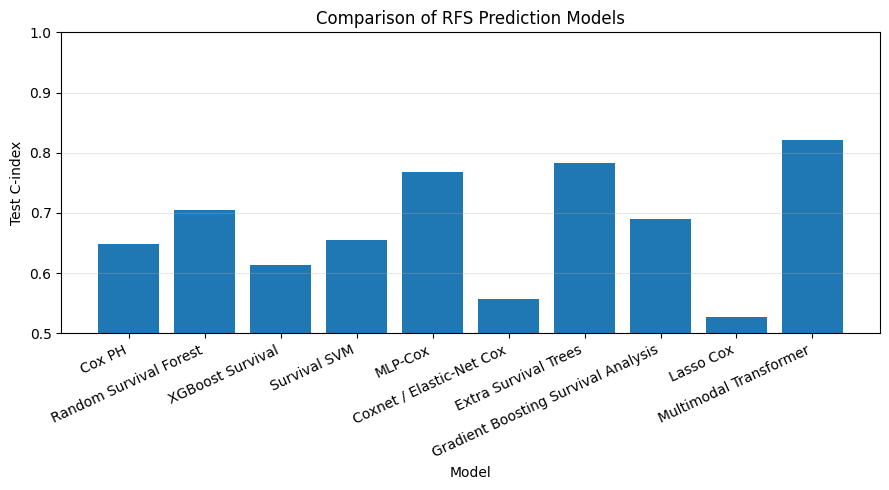

In [ ]:
# ============================================================
#  MODEL C-INDEX COMPARISON
# ============================================================

import matplotlib.pyplot as plt


plot_df = final_comparison_df.copy()


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    plot_df["Model"],
    plot_df["C-index"]
)


plt.ylabel(
    "Test C-index"
)


plt.xlabel(
    "Model"
)


plt.title(
    "Comparison of RFS Prediction Models"
)


plt.ylim(
    0.5,
    1.0
)


plt.xticks(
    rotation=25,
    ha="right"
)


plt.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()